## Script to process multiple years using a Fourier Series Fit to the Temp Time Series, and measure the gradient of the curve at the start and end of Winter

### edit array of years to process below - roughly XXX hours for YYY years processing time 

In [1]:
import xarray as xr
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.fft import fft

import matplotlib.ticker as mticker
from cartopy import crs as ccrs, feature as cfeature
import netCDF4
from netCDF4 import Dataset
from datetime import datetime as dt

import scipy.stats as stats
from sklearn import linear_model
import statsmodels.api as sm
import seaborn as sns

import pymannkendall as mk

# to get rid of runtime warnings when OLS fits hit a divide by zero - handled by setting R2 and p-vals appropriately
import warnings
warnings.filterwarnings('ignore')

In [10]:


###################
# helper functions
###################
def GradientStatsFourier(temp_data, temp_data_next, threshold):
    '''

    Function that uses the input 25th percentile temperature in K to identify the Winter from a time series of temperatures.
    Input data should already be set to 365 days.

    Args:
        temp_data: xarray of temperature data for a single grid cell for the year of interest
        temp_data_next: xarray of temperature data for a single grid cell for the following year (for NH winter)
        threshold: xarray for the 75th percentile threshold to use
        
    Returns:
        start day: DOY that daily mean t2m (from smoothed Fourier fit) first crossed below threshold (25th percentile)
        end day: DOY that daily mean t2m (from smoothed Fourier fit) first crossed above threshold (25th percentile) 
        grad_start: the gradient (slope) of the fourier fit at on the start day of winter
        grad_end: the gradient (slope) of the fourier fit on the end day of winter
        
    Example:
        start_day, last_day, grad_start, grad_end = GradientStatsFourier(temps, temps_next, thresh)

    '''

    # default values
    start_f = 0 
    end_f = 0
    grad_start_f = 0 
    grad_end_f = 0 
    winter_length_f = 0

    # split method based on NH or SH

    ######
    # SOUTHERN Hemisphere (uses current year only)
    if temp_data.lat.values < 0:
        # extract DOY and T2m values for those days
        x1 = temp_data.time.dt.dayofyear.values
        y1 = temp_data.values

        # Fourier fit, up to 4th harmonic (mean + 3 more) as in Weller et al 2020
        ymean = np.mean(y1)
        y_norm = y1 - ymean
        # perform DFT of temp data
        coef = fft(y_norm)
        # low-pass filter: retain only the mean and the first three harmonics, set all other frequencies to zero
        # help from https://kls2177.github.io/Climate-and-Geophysical-Data-Analysis/chapters/Week6/filtering_in_freq2.html
        Z_lp = np.copy(coef)
        Z_lp[4:-3:] = 0.0  # we have to set both the positive and negative frequencies to zero
        # apply inverse fourier transform to convert back to time domain (just want the real part)
        y_norm_lp = np.real(np.fft.ifft(Z_lp))

        # add back in the original mean temp
        y_lp = y_norm_lp + ymean

        # RMSE for Fourier fit
        rmse = np.sqrt(np.sum((y1-y_lp)**2)/365.0)

        # create some x values for plotting fits
        x_values = np.linspace(min(x1), max(x1), 365)
    
        ### DETERMINE START AND END FOR FOURIER and Calc Gradient
        # use fit to get stats
        # in Scott et al 2026 summer was >= threshold so using same definition for (winter <= threshold)
        winter_length_f = np.count_nonzero(y_lp <= threshold.values)
        winter_days_f = np.where(y_lp <= threshold.values)[0]
        grad_fourier = np.gradient(y_lp)

        # deal with case where there is no winter 
        if winter_length_f == 0:
            start_f = np.nan
            end_f = np.nan
            grad_start_f = np.nan 
            grad_end_f = np.nan 

        else:
            # otherwise can get start/end days 
            start_f = int(x_values[min(winter_days_f)])
            grad_start_f = grad_fourier[start_f]

            # end day comes after first day so find next crossing of  fit
            # this is to be careful to not count until the end of a double crossing
            end_window = np.where((y_lp[start_f:365]) > threshold.values)

            # if it does cross back above threshold before the end of the "year"
            if np.count_nonzero(end_window):
                end_f = end_window[0][0] + start_f
                grad_end_f = grad_fourier[end_f]

            # otherwise it never crosses back above threshold for the "year"
            # so the last day is day 365
            else:
                end_f = 365
                grad_end_f = grad_fourier[end_f-1] 

                
    
    ######
    # NORTHERN Hemisphere (uses current year and following year)
    else: 
        # concat both years
        ds_two = xr.concat([temp_data, temp_data_next], dim="time")

        # get the current year for slicing
        input_year = temp_data.time.dt.year.values[0]

        # select July 1 - June 30 across the two years to do fit
        startdate = str(input_year)+'-07-01' # 182nd day of a normal year
        enddate = str(input_year+1)+'-06-30'
        nh_yr = ds_two.sel(time=slice(startdate,enddate))
        
        # DOY (relative to July 1) and T2m values for those days
        x1 = np.arange(1,len(nh_yr.time)+1) 
        y1 = nh_yr.values
        
        # Fourier fit, up to 4th harmonic (mean + 3 more) as in Weller et al 2020
        ymean = np.mean(y1)
        y_norm = y1 - ymean
        # perform DFT of temp data
        coef = fft(y_norm)
        # low-pass filter: retain only the mean and the first three harmonics, set all other frequencies to zero
        # help from https://kls2177.github.io/Climate-and-Geophysical-Data-Analysis/chapters/Week6/filtering_in_freq2.html
        Z_lp = np.copy(coef)
        Z_lp[4:-3:] = 0.0  # we have to set both the positive and negative frequencies to zero
        # apply inverse fourier transform to convert back to time domain (just want the real part)
        y_norm_lp = np.real(np.fft.ifft(Z_lp))

        # add back in the original mean temp
        y_lp = y_norm_lp + ymean

        # RMSE for Fourier fit
        rmse = np.sqrt(np.sum((y1-y_lp)**2)/365.0)
        
        # create some x values for plotting  fit
        x_values = np.linspace(min(x1), max(x1), 365) 

        ### DETERMINE START AND END FOR FOURIER and Calc Gradient
        # use fit to get stats
        # in Scott et al 2026 summer was >= threshold so using same definition for (winter <= threshold)
        winter_length_f = np.count_nonzero(y_lp <= threshold.values)
        winter_days_f = np.where(y_lp <= threshold.values)[0]
        grad_fourier = np.gradient(y_lp)

        # deal with case where there is no winter 
        if winter_length_f == 0:
            start_f = np.nan
            end_f = np.nan
            grad_start_f = np.nan 
            grad_end_f = np.nan 

        else:
            # otherwise can get start/end days 
            start_f = int(x_values[min(winter_days_f)])
            grad_start_f = grad_fourier[start_f]

            # end day comes after first day so find next crossing of  fit
            # this is to be careful to not count until the end of a double crossing
            end_window = np.where((y_lp[start_f:365]) > threshold.values)

            # if it does cross back above threshold before the end of the "year"
            if np.count_nonzero(end_window):
                end_f = end_window[0][0] + start_f
                grad_end_f = grad_fourier[end_f]

            # otherwise it never crosses back above threshold for the "year"
            # so the last day is day 365
            else:
                end_f = 365
                grad_end_f = grad_fourier[end_f-1] 
                
    # returns all floats since start and end could be nan
    return float(start_f), float(end_f), float(grad_start_f), float(grad_end_f)



# a function that takes in a dataset of global t2m values and if it is a leap year averages
# the temps on Feb 28 & Feb 29, then drops Feb 29 to ensure the year has 365 days
def HandleLeapYears(input_ds):
    '''

    Function that takes the mean of Feb 28 & Feb 29 (if it exists) and returns an xarray Dataset that has 365 days
    where Feb 28 will now have a t2m value that is the mean of Feb 28 & Feb 29

    Args:
        input_ds: the data set containing a single year of data that may need adjusting for leap year
        
    Returns:
        output_ds
        
    Example:
        no_leap_ds = HandleLeapYears(input_ds)

    '''
    

    # check if a leap year
    if(input_ds.time.dt.is_leap_year[0].values):
        
        # make deep copy
        output_ds = input_ds.copy(deep=True)
        
        # get mean of Feb 28 (time index 58) & Feb 29 (time index 59) for each grid cell and overwrite Feb 28 with it
        mean_dat = output_ds.t2m[58:60].mean(dim='time', skipna=True, keep_attrs=True)
        output_ds.t2m[58] = mean_dat
        
        # drop Feb 29
        output_ds = output_ds.convert_calendar('noleap', use_cftime=None)

        # ensure time is datetime64
        output_ds["time"] = output_ds.time.dt.strftime('%Y-%m-%d')
        output_ds['time'] = pd.to_datetime(output_ds['time'])

        # return the new dataset 
        return output_ds
    else:
        return input_ds
    

In [3]:
# latitude & longitude ranges for NH and SH midlatitudes so they will be easy to adjust
nh_min = 23.5
nh_max = 70
sh_min = -23.5
sh_max = -70

### Load threshold values for finding winter

In [4]:
# get baseline (again) to keep code blocks together
file_path = '../../../../Data/ERA5-global/Baseline/computed_1961-1990-full_25th.nc'
c_25 = xr.open_dataarray(file_path)
c_25.values


array([[218.86286926, 218.86286926, 218.86286926, ..., 218.86286926,
        218.86286926, 218.86286926],
       [218.52233887, 218.52339172, 218.52293396, ..., 218.51637268,
        218.51916504, 218.52043152],
       [218.57655334, 218.57861328, 218.58085632, ..., 218.56170654,
        218.56726074, 218.57206726],
       ...,
       [246.8707428 , 246.86950684, 246.86828613, ..., 246.86943054,
        246.86888123, 246.86985779],
       [246.88891602, 246.88896179, 246.88874817, ..., 246.8840332 ,
        246.88557434, 246.88737488],
       [246.99066162, 246.99066162, 246.99066162, ..., 246.99066162,
        246.99066162, 246.99066162]], shape=(721, 1440))

### Test it out on Vancouver

In [6]:
# grid parameters for looping
num_lat = 721
num_lon = 1440

loop_lats = c_25.lat.values[:num_lat]
loop_lons = c_25.lon.values[:num_lon]

In [11]:
# testing mean temp addition
input_year = 2021

# get this year and next year's daily mean t2m data
if input_year <= 1990:
    file_path = '../../../../Data/ERA5-global/Baseline/' + str(input_year) + '/*.nc'
else:
    file_path = '../../../../Data/ERA5-global/Analysis/' + str(input_year) + '/*.nc'
ds = xr.open_mfdataset(file_path)

if input_year+1 <= 1990:
    file_path_next = '../../../../Data/ERA5-global/Baseline/' + str(input_year+1) + '/*.nc'
else:
    file_path_next = '../../../../Data/ERA5-global/Analysis/' + str(input_year+1) + '/*.nc'
dsnext = xr.open_mfdataset(file_path_next)

# remove leap day by averaging Feb 28 & 29 together before dropping Feb 29
ds = HandleLeapYears(ds)
dsnext = HandleLeapYears(dsnext)

# load into memory to speed up the summer stats processing
ds.load()
dsnext.load()

#test for Vancouver
input_lat = 49.246
input_lon = -123.116
curr = ds.t2m.sel(lat=input_lat, lon=input_lon, method="nearest")
nxt = dsnext.t2m.sel(lat=input_lat, lon=input_lon, method="nearest")
thresh = c_25.sel(lat=input_lat, lon=input_lon, method="nearest")
start_day, last_day, grad_start, grad_end = GradientStatsFourier(curr, nxt, thresh)
start_day, last_day, grad_start, grad_end

(149.0, 232.0, -0.13287353515625, 0.09979248046875)

In [ ]:
#(142.0, 266.0, 0.133148193359375, -0.1600799560546875)

In [12]:
# test for Sydney
input_lat = -33 - 52/60 - 4/3600
input_lon = 151.25
curr = ds.t2m.sel(lat=input_lat, lon=input_lon, method="nearest")
nxt = dsnext.t2m.sel(lat=input_lat, lon=input_lon, method="nearest")
thresh = c_25.sel(lat=input_lat, lon=input_lon, method="nearest")
start_day, last_day, grad_start, grad_end = GradientStatsFourier(curr, nxt, thresh)
start_day, last_day, grad_start, grad_end

(155.0, 219.0, -0.058502197265625, 0.0449676513671875)

## ********** NEED to run all years now and output file for later analysis

## Main Loop: loop through multiple years to generate summer stats

In [15]:
# process_yrs = [1990,1991,1992,1993, 1994, 1995, 1996, 1997, 1998, 1999, 2002, 2004, 2005, 2006, 2007, 2008,
#               2009, 2010, 2011, 2012, 2012, 2013, 2014, 2015, 2016, 2017, 2018, 2019, 2020, 2021, 2022]
process_yrs = np.arange(2001, 2026,1)
#missing = np.arange(1986,1990,1)

#process_yrs = np.append(process_yrs,missing)
process_yrs

array([2001, 2002, 2003, 2004, 2005, 2006, 2007, 2008, 2009, 2010, 2011,
       2012, 2013, 2014, 2015, 2016, 2017, 2018, 2019, 2020, 2021, 2022,
       2023, 2024, 2025])

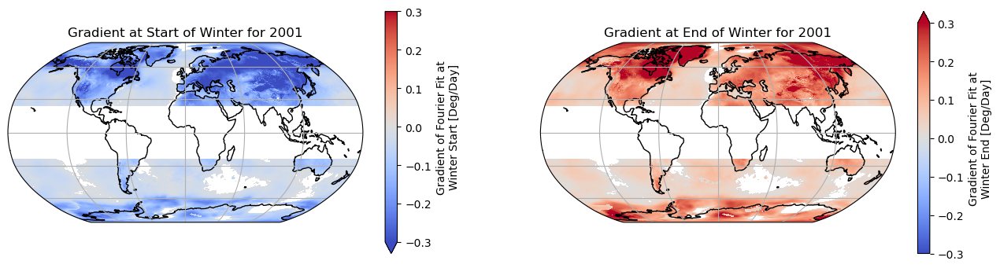

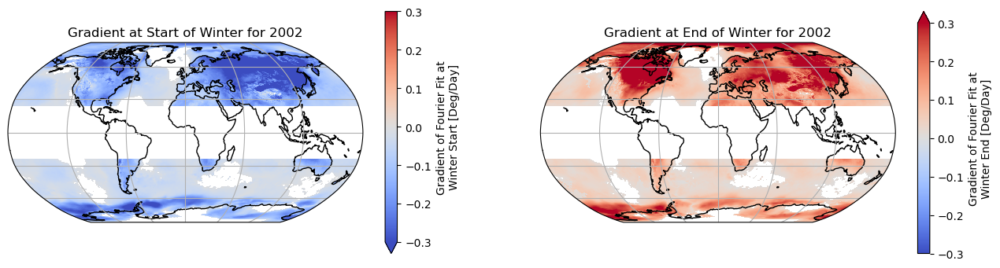

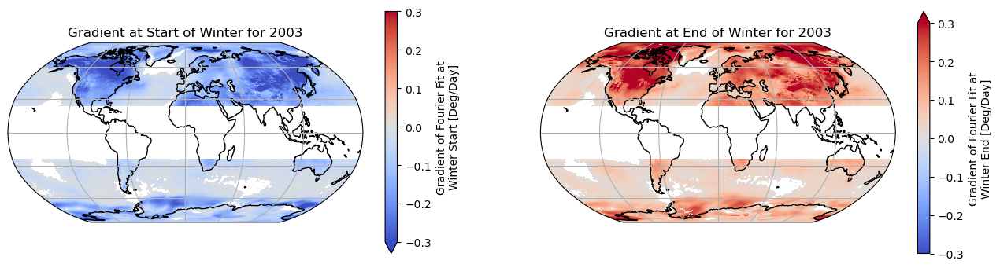

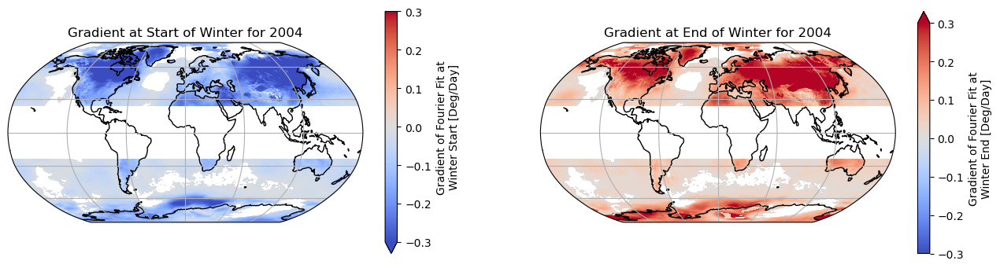

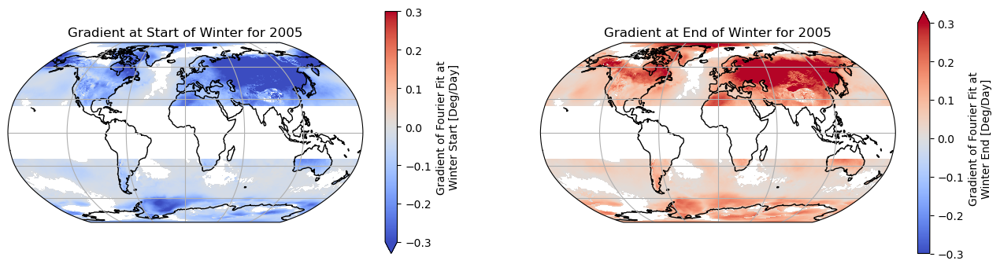

...

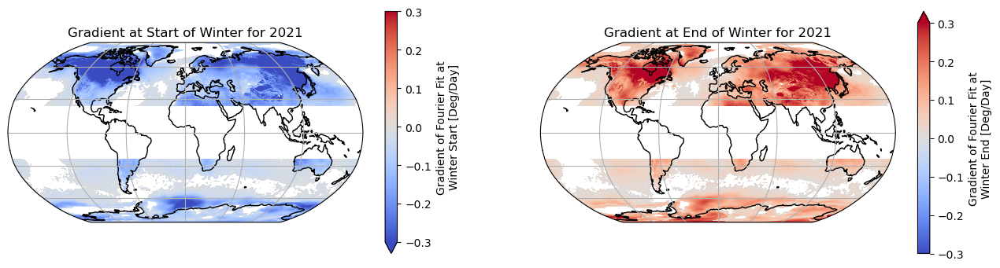

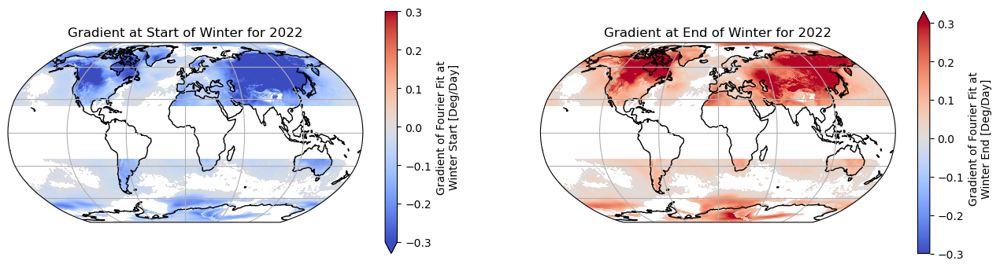

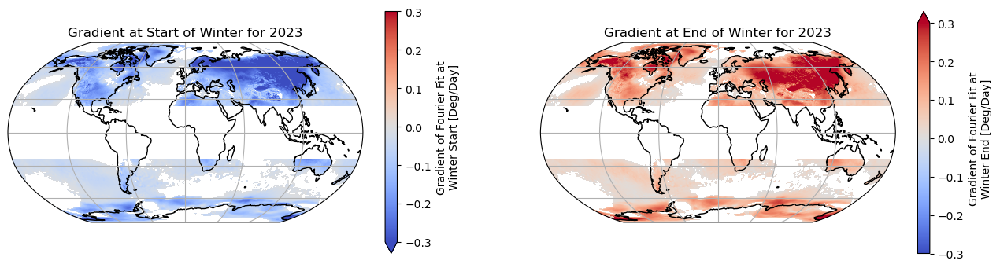

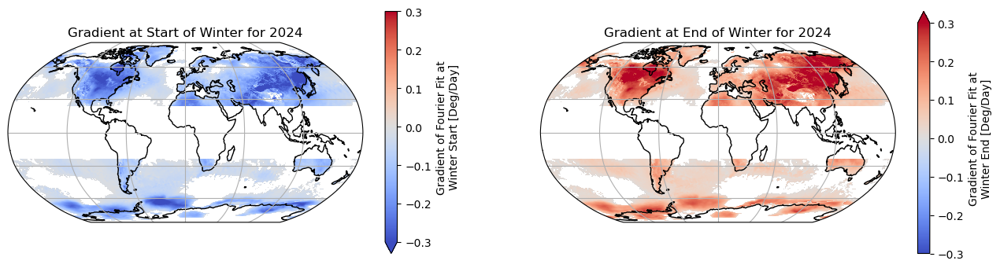

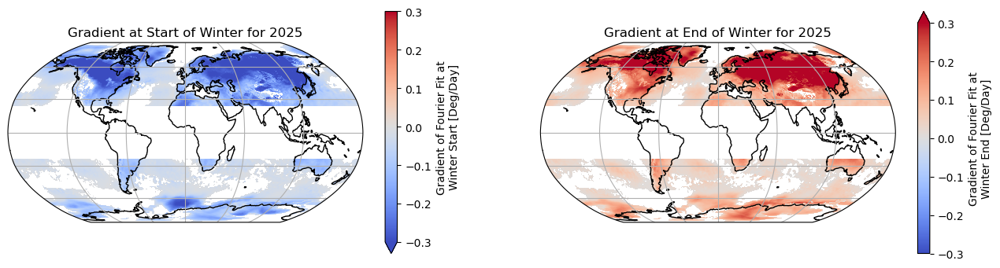

CPU times: user 7h 37min 23s, sys: 3min 50s, total: 7h 41min 13s
Wall time: 7h 41min 35s


In [16]:
%%time

# Runtime: 19 min for 1 year
# 
# 12.5 min for 40 yrs

# loop thru the years in the defined array above
for input_year in process_yrs:

    # get this year and next year's daily mean t2m data
    if input_year <= 1990:
        file_path = '../../../../Data/ERA5-global/Baseline/' + str(input_year) + '/*.nc'
    else:
        file_path = '../../../../Data/ERA5-global/Analysis/' + str(input_year) + '/*.nc'
    ds = xr.open_mfdataset(file_path)

    if input_year+1 <= 1990:
        file_path_next = '../../../../Data/ERA5-global/Baseline/' + str(input_year+1) + '/*.nc'
    else:
        file_path_next = '../../../../Data/ERA5-global/Analysis/' + str(input_year+1) + '/*.nc'
    dsnext = xr.open_mfdataset(file_path_next)

    # remove leap day by averaging Feb 28 & 29 together before dropping Feb 29
    ds = HandleLeapYears(ds)
    dsnext = HandleLeapYears(dsnext)

    # load into memory to speed up the winter stats processing
    ds.load()
    dsnext.load()

    # empty data arrays for winter stats
    winterstart = xr.DataArray(np.zeros((num_lat,num_lon)), 
                               coords=[loop_lats, loop_lons], 
                               dims=['lat','lon'])
    winterend = xr.DataArray(np.zeros((num_lat,num_lon)), 
                             coords=[loop_lats, loop_lons], 
                             dims=['lat','lon'])
    start_grad_f = xr.DataArray(np.zeros((num_lat,num_lon)), 
                                coords=[loop_lats, loop_lons], 
                                dims=['lat','lon'])
    
    end_grad_f = xr.DataArray(np.zeros((num_lat,num_lon)), 
                                coords=[loop_lats, loop_lons], 
                                dims=['lat','lon'])
    
    # add attributes
    winterstart.attrs["long_name"] = "Start day of winter for the year (DOY in [1,365])"
    winterstart.attrs["units"] = "Day of year"
    
    winterend.attrs["long_name"] = "Last day of winter for the year (DOY in [1,365])"
    winterend.attrs["units"] = "Day of year"
    
    start_grad_f.attrs["long_name"] = "Gradient of Fourier Fit at Winter Start"
    start_grad_f.attrs["units"] = "Deg/Day"
    
    end_grad_f.attrs["long_name"] = "Gradient of Fourier Fit at Winter End"
    end_grad_f.attrs["units"] = "Deg/Day"
    

    # loop through all of the lat,lon of interest
    for input_lat in loop_lats:
        for input_lon in loop_lons:
            # get threshold from c_75
            thresh = c_25.sel(lat=input_lat,lon=input_lon)
    
            # all the temps for that grid cell over time for this year and next (for SH)
            curr = ds.t2m.sel(lat=input_lat,lon=input_lon) 
            nxt = dsnext.t2m.sel(lat=input_lat, lon=input_lon)
    
            # build winter stats for the grid cell and produce the plot if desired (currently False)
            start_day, last_day, grad_start, grad_end = GradientStatsFourier(curr, nxt, thresh)
            
            # xarray requires strange indexing in order to replace values by coordinate
            winterstart.loc[input_lat, input_lon] = start_day
            winterend.loc[input_lat, input_lon] = last_day
            start_grad_f.loc[input_lat, input_lon] = grad_start
            end_grad_f.loc[input_lat, input_lon] = grad_end
            
            

    # save it out
    sum_ds = xr.Dataset(data_vars={'WinterStart':winterstart,
                               'WinterEnd':winterend,
                                'GradientWinterStartFourier':start_grad_f,
                                'GradientWinterEndFourier':end_grad_f})
    
    output_path = '../../../../Data/ERA5-global/Analysis/New-Fourier/Gradients/Winter/'+str(input_year)+'_winter_gradient_stats.nc'
    sum_ds.to_netcdf(output_path)

    # plots for the year
    ##############
    # Global winter for the year
    fig = plt.figure(figsize=(16,8))
    
    ax1 = fig.add_subplot(1,2,1, projection=ccrs.Robinson(central_longitude=0))
    # assign axis and def projection to use
    #ax1 = plt.axes(projection=ccrs.Robinson(central_longitude=0))
    
    # add coastlines and grid
    ax1.coastlines()
    ax1.gridlines()
    
    sum_ds.GradientWinterStartFourier.where((sum_ds.lat >= nh_min) | (sum_ds.lat <= sh_min)).plot(
        ax=ax1,
        transform=ccrs.PlateCarree(), # assign map projection
        vmin=-0.3,
        vmax=0.3, # define range to include an entire year
        cmap="coolwarm",#"YlOrRd"#cmap="coolwarm"
        cbar_kwargs={'shrink': 0.5}
    )
    ax1.set_title("Gradient at Start of Winter for "+str(input_year))#+" using 1961-1990 baseline")
    
    ax2 = fig.add_subplot(1,2,2, projection=ccrs.Robinson(central_longitude=0))
    # assign axis and def projection to use
    #ax2 = plt.axes()
    
    # add coastlines and grid
    ax2.coastlines()
    ax2.gridlines()
    
    sum_ds.GradientWinterEndFourier.where((sum_ds.lat >= nh_min) | (sum_ds.lat <= sh_min)).plot(
        ax=ax2,
        transform=ccrs.PlateCarree(), # assign map projection
        vmin=-0.3,
        vmax=0.3, # define range to include an entire year
        cmap="coolwarm",#"YlOrRd"#cmap="coolwarm"
        cbar_kwargs={'shrink': 0.5}
    )
    ax2.set_title("Gradient at End of Winter for "+str(input_year))#+" using 1961-1990 baseline")
    #plt.tight_layout()
    plt.show()



# ****** BELOW NOT UPDATED

# ********** Once we have all years processed for gradients, then compile them into a single file with the coastal flag and LSM

## Load LSM for filtering

In [61]:
file_path = '../../../Data/ERA5-global/ERA5-2023-09-01-CoordFixed-LSM.nc'
ds_lsm = xr.open_dataset(file_path)
ds_lsm

<xarray.Dataset> Size: 8MB
Dimensions:  (lat: 721, lon: 1440)
Coordinates:
  * lat      (lat) float32 3kB 90.0 89.75 89.5 89.25 ... -89.5 -89.75 -90.0
  * lon      (lon) float32 6kB -180.0 -179.8 -179.5 -179.2 ... 179.2 179.5 179.8
Data variables:
    lsm      (lat, lon) float64 8MB ...

## Pull in the coastal margins for use in data processing and write out full 1961-2023 Summer Stats for Fourier fit data

In [62]:
# write those results out for later use
input_path = '../../../Data/ERA5-global/ERA5-2023-09-01-CoordFixed-CoastalMargins.nc'
results_ds = xr.open_dataset(input_path)



In [12]:
results_ds

<xarray.Dataset> Size: 1MB
Dimensions:  (lat: 721, lon: 1440)
Coordinates:
  * lat      (lat) float32 3kB 90.0 89.75 89.5 89.25 ... -89.5 -89.75 -90.0
  * lon      (lon) float32 6kB -180.0 -179.8 -179.5 -179.2 ... 179.2 179.5 179.8
Data variables:
    Coastal  (lat, lon) bool 1MB ...

## * Build and write out the full data set from Fourier fits including the coastal margin boolean

In [63]:
%%time

# takes ~2.5 min to load

# start with one year and lsm then coastal and add a coordinate for the year
year = 1961
input_path = '../../../Data/ERA5-global/Analysis/New-Fourier/Gradients/'+str(year)+'_summer_gradient_stats.nc'
ds_base = xr.open_dataset(input_path)
ds_base = ds_base.merge(ds_lsm) # add lsm
ds_base = ds_base.merge(results_ds) # add coastal flag
ds_base = ds_base.expand_dims("time").assign_coords(time=("time", [dt(year,1,1)]))

# loop thru remaining years and also add time coord
input_years = np.arange(1962,2024,1)

for year in input_years:
    input_path = '../../../Data/ERA5-global/Analysis/New-Fourier/Gradients/'+str(year)+'_summer_gradient_stats.nc'
    ds_i = xr.open_dataset(input_path)
    ds_i = ds_i.merge(ds_lsm)
    ds_i = ds_i.merge(results_ds)
    ds_i = ds_i.expand_dims("time").assign_coords(time=("time", [dt(year,1,1)]))
    ds_base = ds_base.merge(ds_i)

ds_base

CPU times: user 53.4 s, sys: 1min 19s, total: 2min 13s
Wall time: 2min 28s


<xarray.Dataset> Size: 3GB
Dimensions:                   (lat: 721, lon: 1440, time: 63)
Coordinates:
  * lat                       (lat) float64 6kB -90.0 -89.75 ... 89.75 90.0
  * lon                       (lon) float64 12kB -180.0 -179.8 ... 179.5 179.8
  * time                      (time) datetime64[ns] 504B 1961-01-01 ... 2023-...
Data variables:
    SummerStart               (time, lat, lon) float64 523MB 136.0 ... 162.0
    SummerEnd                 (time, lat, lon) float64 523MB 222.0 ... 244.0
    GradientSummStartFourier  (time, lat, lon) float64 523MB 0.2842 ... 0.2287
    GradientSummEndFourier    (time, lat, lon) float64 523MB -0.2812 ... -0.2034
    lsm                       (time, lat, lon) float64 523MB 1.0 1.0 ... 0.0 0.0
    Coastal                   (time, lat, lon) float64 523MB 0.0 0.0 ... 0.0 0.0

In [64]:
# re-add attributes which get lost on merge apparently
ds_base.SummerStart.attrs["long_name"] = "Start day of summer for the year (DOY in [1,365])"
ds_base.SummerStart.attrs["units"] = "Day of year"

ds_base.SummerEnd.attrs["long_name"] = "Last day of summer for the year (DOY in [1,365])"
ds_base.SummerEnd.attrs["units"] = "Day of year"

ds_base.GradientSummStartFourier.attrs["long_name"] = "Gradient of Fourier Fit at Summer Start"
ds_base.GradientSummStartFourier.attrs["units"] = "Deg/Day"
    
ds_base.GradientSummEndFourier.attrs["long_name"] = "Gradient of Fourier Fit at Summer End"
ds_base.GradientSummEndFourier.attrs["units"] = "Deg/Day"

###
### also cast the Coastal as boolean?
###
ds_base.Coastal.values = ds_base.Coastal.values.astype(bool)
ds_base.Coastal.attrs["long_name"] = "Boolean value for whether a >30% land cell has at least one >80% water neighbor"
ds_base.Coastal.attrs["units"] = "true/false"

ds_base

<xarray.Dataset> Size: 3GB
Dimensions:                   (lat: 721, lon: 1440, time: 63)
Coordinates:
  * lat                       (lat) float64 6kB -90.0 -89.75 ... 89.75 90.0
  * lon                       (lon) float64 12kB -180.0 -179.8 ... 179.5 179.8
  * time                      (time) datetime64[ns] 504B 1961-01-01 ... 2023-...
Data variables:
    SummerStart               (time, lat, lon) float64 523MB 136.0 ... 162.0
    SummerEnd                 (time, lat, lon) float64 523MB 222.0 ... 244.0
    GradientSummStartFourier  (time, lat, lon) float64 523MB 0.2842 ... 0.2287
    GradientSummEndFourier    (time, lat, lon) float64 523MB -0.2812 ... -0.2034
    lsm                       (time, lat, lon) float64 523MB 1.0 1.0 ... 0.0 0.0
    Coastal                   (time, lat, lon) bool 65MB False False ... False

In [67]:
# write out complete dataset with LSM and Coastal flags
output_path = '../../../Data/ERA5-global/Analysis/New-Fourier/Gradients/1961-2023_ALL_summer_gradient_stats.nc'
ds_base.to_netcdf(output_path)
ds_base.close()

In [3]:
! ls -al "../../../Data/ERA5-global/Analysis/New-Fourier/Gradients"

total 9524280
drwxr-xr-x@ 73 tedscott  staff        2336 Apr 14 14:05 .
drwxr-xr-x@ 86 tedscott  staff        2752 Jul 15 14:16 ..
-rw-r--r--@  1 tedscott  staff        6148 Apr 14 11:36 .DS_Store
-rw-r--r--@  1 tedscott  staff    33249659 Mar 26 08:58 1961_summer_gradient_stats.nc
drwxr-xr-x@ 37 tedscott  staff        1184 Apr 14 14:06 1961-1990_ClimStartEnd
-rw-r--r--@  1 tedscott  staff  2681807405 Mar 26 18:26 1961-2023_ALL_summer_gradient_stats.nc
-rw-r--r--@  1 tedscott  staff    24943042 Mar 27 13:37 1961-2023_EndGradTrends.nc
-rw-r--r--@  1 tedscott  staff    24942864 Mar 27 11:15 1961-2023_StartGradTrends.nc
-rw-r--r--@  1 tedscott  staff    33249659 Mar 26 09:17 1962_summer_gradient_stats.nc
-rw-r--r--@  1 tedscott  staff    33249659 Mar 26 09:36 1963_summer_gradient_stats.nc
-rw-r--r--@  1 tedscott  staff    33249659 Mar 26 09:55 1964_summer_gradient_stats.nc
-rw-r--r--@  1 tedscott  staff    33249659 Mar 26 10:14 1965_summer_gradient_stats.nc
-rw-r--r--@  1 tedscott  staff 

In [75]:
# free up the memory since we're going to reload it
# ds_base.close()
# ds_base.nbytes
# del ds_base
# ds_base

# ********** Spatial analysis of trends via MK

### Read in summer start/end gradients

In [107]:
# read the data back in in case we start from here
input_path = '../../../Data/ERA5-global/Analysis/New-Fourier/Gradients/1961-2023_ALL_summer_gradient_stats.nc'
ds_full = xr.open_dataset(input_path)
ds_full

<xarray.Dataset> Size: 3GB
Dimensions:                   (lat: 721, lon: 1440, time: 63)
Coordinates:
  * lat                       (lat) float64 6kB -90.0 -89.75 ... 89.75 90.0
  * lon                       (lon) float64 12kB -180.0 -179.8 ... 179.5 179.8
  * time                      (time) datetime64[ns] 504B 1961-01-01 ... 2023-...
Data variables:
    SummerStart               (time, lat, lon) float64 523MB ...
    SummerEnd                 (time, lat, lon) float64 523MB ...
    GradientSummStartFourier  (time, lat, lon) float64 523MB ...
    GradientSummEndFourier    (time, lat, lon) float64 523MB ...
    lsm                       (time, lat, lon) float64 523MB ...
    Coastal                   (time, lat, lon) bool 65MB ...

## Gradient of Summer Start Trends

In [76]:
ds_full_start = ds_full.GradientSummStartFourier
ds_full_start

<xarray.DataArray 'GradientSummStartFourier' (time: 63, lat: 721, lon: 1440)> Size: 523MB
[65409120 values with dtype=float64]
Coordinates:
  * lat      (lat) float64 6kB -90.0 -89.75 -89.5 -89.25 ... 89.5 89.75 90.0
  * lon      (lon) float64 12kB -180.0 -179.8 -179.5 ... 179.2 179.5 179.8
  * time     (time) datetime64[ns] 504B 1961-01-01 1962-01-01 ... 2023-01-01
Attributes:
    long_name:  Gradient of Fourier Fit at Summer Start
    units:      Deg/Day

In [77]:
%%time

# takes 27 min for 63 years with MK test!

# grid parameters for looping
num_lat = 721
num_lon = 1440

loop_lats = ds_full_start.lat.values[:num_lat]
loop_lons = ds_full_start.lon.values[:num_lon]

# empty data arrays for summer stats
# variables from modified mann-kendall test (Hamed & Rao)
start_mkslope = xr.DataArray(np.zeros((num_lat,num_lon)), 
                            coords=[loop_lats, loop_lons], 
                            dims=['lat','lon'])

start_mkh = xr.DataArray(np.zeros((num_lat,num_lon)), 
                           coords=[loop_lats, loop_lons], 
                           dims=['lat','lon'])

start_mkp = xr.DataArray(np.zeros((num_lat,num_lon)), 
                           coords=[loop_lats, loop_lons], 
                           dims=['lat','lon'])


# add attributes
start_mkslope.attrs["long_name"] = "Theil-Sen's Slope of linear fit of gradient of summer start over time"
start_mkslope.attrs["units"] = "Days/year"

start_mkh.attrs["long_name"] = "Hamed & Rao MK test for presence of trend"
start_mkh.attrs["units"] = "Binary"

start_mkp.attrs["long_name"] = "Hamed & Rao MK test for significance (p-value) of trend"
start_mkp.attrs["units"] = "None"



# loop through all of the lat,lon of interest
for input_lat in loop_lats:
    for input_lon in loop_lons:

        # create x & y values for linear fit
        x = ds_full_start.time.dt.year.values
        y = ds_full_start.sel(lat=input_lat, lon=input_lon).values

        # Modified Mann-Kendall (hamed & Rao) results
        result_mk = mk.hamed_rao_modification_test(y)
        start_mkslope.loc[input_lat, input_lon] = result_mk.slope
        start_mkh.loc[input_lat, input_lon] = result_mk.h
        start_mkp.loc[input_lat, input_lon] = result_mk.p

        
# results dataset
results_ds = xr.Dataset(data_vars={'StartMKSlope':start_mkslope,
                           'StartMKH':start_mkh,
                           'StartMKP':start_mkp
                                  })

# see results
results_ds

CPU times: user 24min 7s, sys: 2min 24s, total: 26min 32s
Wall time: 26min 44s


<xarray.Dataset> Size: 25MB
Dimensions:       (lat: 721, lon: 1440)
Coordinates:
  * lat           (lat) float64 6kB -90.0 -89.75 -89.5 ... 89.5 89.75 90.0
  * lon           (lon) float64 12kB -180.0 -179.8 -179.5 ... 179.2 179.5 179.8
Data variables:
    StartMKSlope  (lat, lon) float64 8MB 0.00115 0.00115 ... -0.0007081
    StartMKH      (lat, lon) float64 8MB 1.0 1.0 1.0 1.0 1.0 ... 1.0 1.0 1.0 1.0
    StartMKP      (lat, lon) float64 8MB 0.0001618 0.0001618 ... 1.768e-05

### Summer Start trends over analysis period: 1990-2023

In [80]:
# restrict to 1990-2023
ds_start_analysis = ds_full_start.sel(time=slice('1990','2023'))
ds_start_analysis
                                    

<xarray.DataArray 'GradientSummStartFourier' (time: 34, lat: 721, lon: 1440)> Size: 282MB
[35300160 values with dtype=float64]
Coordinates:
  * lat      (lat) float64 6kB -90.0 -89.75 -89.5 -89.25 ... 89.5 89.75 90.0
  * lon      (lon) float64 12kB -180.0 -179.8 -179.5 ... 179.2 179.5 179.8
  * time     (time) datetime64[ns] 272B 1990-01-01 1991-01-01 ... 2023-01-01
Attributes:
    long_name:  Gradient of Fourier Fit at Summer Start
    units:      Deg/Day

### Linear trends for each grid cell 1990-2023

In [81]:
%%time

# takes 20 min for 34 years w/ MK test

# grid parameters for looping
num_lat = 721
num_lon = 1440

loop_lats = ds_start_analysis.lat.values[:num_lat]
loop_lons = ds_start_analysis.lon.values[:num_lon]


# empty data arrays for summer stats
# variables from modified mann-kendall test (Hamed & Rao)
start_mkslope = xr.DataArray(np.zeros((num_lat,num_lon)), 
                            coords=[loop_lats, loop_lons], 
                            dims=['lat','lon'])

start_mkh = xr.DataArray(np.zeros((num_lat,num_lon)), 
                           coords=[loop_lats, loop_lons], 
                           dims=['lat','lon'])

start_mkp = xr.DataArray(np.zeros((num_lat,num_lon)), 
                           coords=[loop_lats, loop_lons], 
                           dims=['lat','lon'])


# add attributes
start_mkslope.attrs["long_name"] = "Theil-Sen's Slope of linear fit of gradient of summer start over time"
start_mkslope.attrs["units"] = "Days/year"

start_mkh.attrs["long_name"] = "Hamed & Rao MK test for presence of trend"
start_mkh.attrs["units"] = "Binary"

start_mkp.attrs["long_name"] = "Hamed & Rao MK test for significance (p-value) of trend"
start_mkp.attrs["units"] = "None"



# loop through all of the lat,lon of interest
for input_lat in loop_lats:
    for input_lon in loop_lons:

        # create x & y values for linear fit
        x = ds_start_analysis.time.dt.year.values
        y = ds_start_analysis.sel(lat=input_lat, lon=input_lon).values

        # Modified Mann-Kendall (hamed & Rao) results
        result_mk = mk.hamed_rao_modification_test(y)
        start_mkslope.loc[input_lat, input_lon] = result_mk.slope
        start_mkh.loc[input_lat, input_lon] = result_mk.h
        start_mkp.loc[input_lat, input_lon] = result_mk.p

        
# results dataset
results_ds_an = xr.Dataset(data_vars={'StartMKSlope':start_mkslope,
                           'StartMKH':start_mkh,
                           'StartMKP':start_mkp
                                  })

# see results
results_ds_an

CPU times: user 19min 27s, sys: 1min 17s, total: 20min 44s
Wall time: 20min 45s


<xarray.Dataset> Size: 25MB
Dimensions:       (lat: 721, lon: 1440)
Coordinates:
  * lat           (lat) float64 6kB -90.0 -89.75 -89.5 ... 89.5 89.75 90.0
  * lon           (lon) float64 12kB -180.0 -179.8 -179.5 ... 179.2 179.5 179.8
Data variables:
    StartMKSlope  (lat, lon) float64 8MB 0.001046 0.001046 ... -0.0003822
    StartMKH      (lat, lon) float64 8MB 0.0 0.0 0.0 0.0 0.0 ... 0.0 0.0 0.0 0.0
    StartMKP      (lat, lon) float64 8MB 0.2726 0.2726 0.2726 ... 0.5532 0.5532

In [84]:
# use func from scipi.stats
# pval_fdr_cor = stats.false_discovery_control(results_ds_an.StartPvalue.values)

# # add as variable to dataset
# results_ds_an['StartPvalFDR'] = (['lat','lon'], pval_fdr_cor)

# results_ds_an

### Output Summer Start trends

In [85]:
# write those results out for later use
output_path = '../../../Data/ERA5-global/Analysis/New-Fourier/Gradients/1961-2023_StartGradTrends.nc'
results_ds.to_netcdf(output_path)

output_path2 = '../../../Data/ERA5-global/Analysis/New-Fourier/Gradients/1990-2023_StartGradTrends.nc'
results_ds_an.to_netcdf(output_path2)

## Read the start trends back in to make plots

In [2]:
input_path = '../../../Data/ERA5-global/Analysis/New-Fourier/Gradients/1961-2023_StartGradTrends.nc'
results_ds = xr.open_dataset(input_path)

input_path2 = '../../../Data/ERA5-global/Analysis/New-Fourier/Gradients/1990-2023_StartGradTrends.nc'
results_ds_an = xr.open_dataset(input_path2)

### 1961-2023: Plot with hatching from MK test

In [31]:
# plot theme - make sure hatches are black
sns.set_theme(style="darkgrid", rc={"patch.edgecolor": "black"})
#sns.set_theme(style="darkgrid")

# reset the theme to get rid of grey background colour
sns.reset_defaults()

In [32]:
sns.axes_style()

{'axes.facecolor': 'white',
 'axes.edgecolor': 'black',
 'axes.grid': False,
 'axes.axisbelow': 'line',
 'axes.labelcolor': 'black',
 'figure.facecolor': 'white',
 'grid.color': '#b0b0b0',
 'grid.linestyle': '-',
 'text.color': 'black',
 'xtick.color': 'black',
 'ytick.color': 'black',
 'xtick.direction': 'out',
 'ytick.direction': 'out',
 'lines.solid_capstyle': <CapStyle.projecting: 'projecting'>,
 'patch.edgecolor': 'black',
 'patch.force_edgecolor': False,
 'image.cmap': 'viridis',
 'font.family': ['sans-serif'],
 'font.sans-serif': ['DejaVu Sans',
  'Bitstream Vera Sans',
  'Computer Modern Sans Serif',
  'Lucida Grande',
  'Verdana',
  'Geneva',
  'Lucid',
  'Arial',
  'Helvetica',
  'Avant Garde',
  'sans-serif'],
 'xtick.bottom': True,
 'xtick.top': False,
 'ytick.left': True,
 'ytick.right': False,
 'axes.spines.left': True,
 'axes.spines.bottom': True,
 'axes.spines.right': True,
 'axes.spines.top': True}

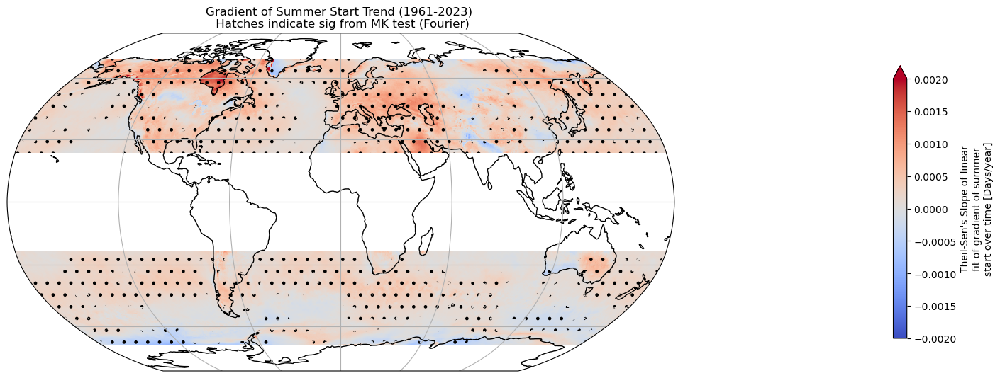

In [3]:

# Global summer start trend
fig = plt.figure(figsize=(15,8))

# assign axis and def projection to use
ax = plt.axes(projection=ccrs.Robinson(central_longitude=0))

# add coastlines and grid
ax.coastlines()
ax.gridlines()

results_ds.StartMKSlope.where((((results_ds.lat >= 23.5) & (results_ds.lat <= 70)) | 
                              ((results_ds.lat <= -23.5) & (results_ds.lat >= -70)))).plot(
    ax=ax,
    transform=ccrs.PlateCarree(), # assign map projection
    vmin=-0.002,
    vmax=0.002, 
    cmap="coolwarm",#"YlOrRd"#cmap="coolwarm"
    cbar_kwargs={'shrink': 0.5}
)

# points with MK test p-value under 0.05
mksig = results_ds.StartMKP.where((((results_ds.lat >= 23.5) & (results_ds.lat <= 70)) | 
                              ((results_ds.lat <= -23.5) & (results_ds.lat >= -70)))) <= 0.1

mksig.where(mksig.values).plot.contourf(hatches="..", transform=ccrs.PlateCarree(), 
                                        #colors='none', 
                                        cmap='none' )#cbar_kwargs={'shrink': 0.0})

# remove the colorbar from the contour
fig.axes[-1].remove()

plt.title("Gradient of Summer Start Trend (1961-2023) \n Hatches indicate sig from MK test (Fourier)")#+" using 1961-1990 baseline")
#plt.savefig("./Plots/"+str(input_year)+"_SummerMeanHS_global.png")
plt.tight_layout()
plt.show()

### North America MK test only

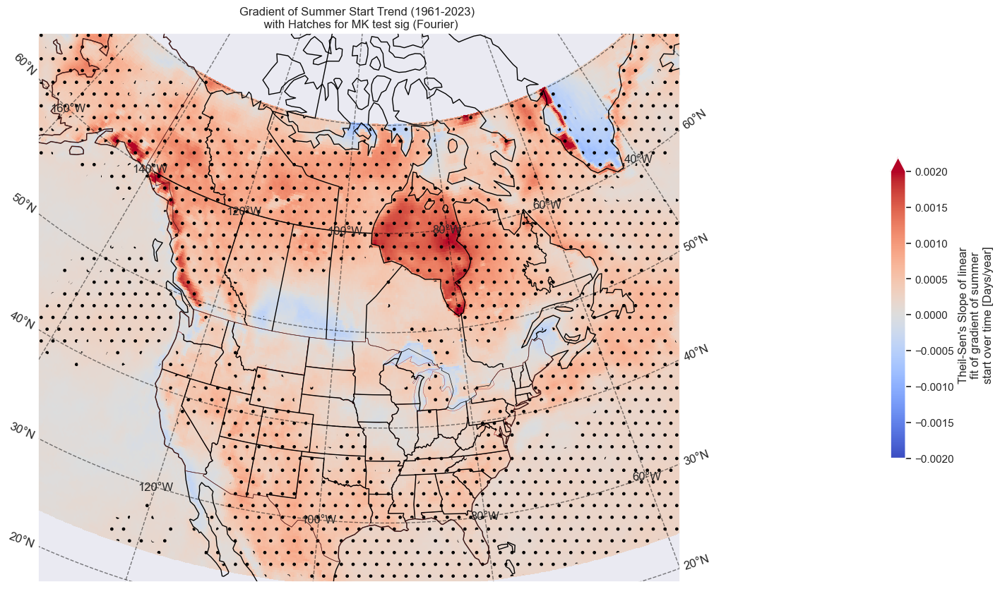

In [16]:

central_longitude = -(91 + 52 / 60)
central_latitude = 40

############
#Global map of summer start
fig = plt.figure(figsize=(15,9))

# assign axis and def projection to use
ax = plt.axes(projection=ccrs.LambertConformal(central_longitude=central_longitude, central_latitude=central_latitude))

# add coastlines and grid
ax.coastlines()
ax.gridlines(draw_labels=True, linewidth=1, color='black', alpha=0.5, linestyle='--')

dataplot = results_ds.StartMKSlope.where((((results_ds.lat >= 23.5) & (results_ds.lat <= 70)) | 
                              ((results_ds.lat <= -23.5) & (results_ds.lat >= -70)))).plot(
    ax=ax,
    transform=ccrs.PlateCarree(), # assign map projection
    vmin=-0.002,
    vmax=0.002, 
    cmap="coolwarm",
    cbar_kwargs={'shrink': 0.5}
    
)

# points with MK test p-value under 0.1
mksig = results_ds.StartMKP.where((((results_ds.lat >= 23.5) & (results_ds.lat <= 70)) | 
                              ((results_ds.lat <= -23.5) & (results_ds.lat >= -70)))) <= 0.1

mksig.where(mksig.values).plot.contourf(hatches="..", transform=ccrs.PlateCarree(), 
                                        #colors='none', 
                                        cmap='none' )#cbar_kwargs={'shrink': 0.0})

# remove the colorbar from the contour
fig.axes[-1].remove()



ax.set_extent((-130, -60, 20, 75))

provinces_50m = cfeature.NaturalEarthFeature('cultural',
                                             'admin_1_states_provinces_lines',
                                             '50m',
                                             facecolor='none')
ax.add_feature(cfeature.BORDERS, linewidth=0.5, edgecolor='black')
ax.add_feature(cfeature.STATES, linewidth=0.3, edgecolor='brown')
ax.add_feature(provinces_50m,edgecolor='black')
plt.title("Gradient of Summer Start Trend (1961-2023) \n with Hatches for MK test sig (Fourier)")#+" using 1961-1990 baseline")
#plt.savefig("./Plots/"+str(input_year)+"_SummerMeanHS_global.png")
plt.tight_layout()
#plt.savefig("./Plots/"+str(input_year)+"_SummerLength_global.png")
plt.show()


#### Make NH and SH FDR maps for full period 1961-2023

#### FDR applied

In [3]:
np.sum(results_ds.StartMKP.values <= 0), np.sum(results_ds.StartMKP.values == 0), np.sum(results_ds.StartMKP.values == 1)

(np.int64(5905), np.int64(5905), np.int64(2726))

In [4]:
# have to replace the zeroes and ones with values between 0 and 1 for FDR
results_ds_p = results_ds.StartMKP
results_ds_p = results_ds_p.where(results_ds_p.values > 0)
results_ds_p = results_ds_p.fillna(1e-10) # fix zeroes
results_ds_p
#np.sum(results_ds_an_tmp.LengthMKP.values <= 0)
results_ds_p = results_ds_p.where(results_ds_p.values < 1.0)
results_ds_p
results_ds_p = results_ds_p.fillna(0.999) # fix ones
results_ds_p

<xarray.DataArray 'StartMKP' (lat: 721, lon: 1440)> Size: 8MB
array([[1.61831990e-04, 1.61831990e-04, 1.61831990e-04, ...,
        1.61831990e-04, 1.61831990e-04, 1.61831990e-04],
       [2.25015383e-04, 2.35738342e-04, 2.35738342e-04, ...,
        2.25015383e-04, 2.25015383e-04, 2.25015383e-04],
       [2.58638189e-04, 2.35738342e-04, 2.14751550e-04, ...,
        2.70855147e-04, 2.70855147e-04, 2.58638189e-04],
       ...,
       [1.75369207e-06, 1.98825583e-06, 1.95174760e-06, ...,
        1.20116310e-06, 1.10418721e-06, 1.10565609e-06],
       [3.94472262e-06, 3.82446363e-06, 3.93843087e-06, ...,
        3.69462600e-06, 3.79244300e-06, 3.91960516e-06],
       [1.76805260e-05, 1.76805260e-05, 1.76805260e-05, ...,
        1.76805260e-05, 1.76805260e-05, 1.76805260e-05]],
      shape=(721, 1440))
Coordinates:
  * lat      (lat) float64 6kB -90.0 -89.75 -89.5 -89.25 ... 89.5 89.75 90.0
  * lon      (lon) float64 12kB -180.0 -179.8 -179.5 ... 179.2 179.5 179.8
Attributes:
    long_name:  Hamed & Rao MK test for significance (p-value) of trend
    units:      None

In [5]:
# use func from scipi.stats
pval_fdr_cor = stats.false_discovery_control(results_ds_p.values)

# add as variable to dataset
results_ds_p['StartPvalFDR'] = (['lat','lon'], pval_fdr_cor)

results_ds_p

<xarray.DataArray 'StartMKP' (lat: 721, lon: 1440)> Size: 8MB
array([[1.61831990e-04, 1.61831990e-04, 1.61831990e-04, ...,
        1.61831990e-04, 1.61831990e-04, 1.61831990e-04],
       [2.25015383e-04, 2.35738342e-04, 2.35738342e-04, ...,
        2.25015383e-04, 2.25015383e-04, 2.25015383e-04],
       [2.58638189e-04, 2.35738342e-04, 2.14751550e-04, ...,
        2.70855147e-04, 2.70855147e-04, 2.58638189e-04],
       ...,
       [1.75369207e-06, 1.98825583e-06, 1.95174760e-06, ...,
        1.20116310e-06, 1.10418721e-06, 1.10565609e-06],
       [3.94472262e-06, 3.82446363e-06, 3.93843087e-06, ...,
        3.69462600e-06, 3.79244300e-06, 3.91960516e-06],
       [1.76805260e-05, 1.76805260e-05, 1.76805260e-05, ...,
        1.76805260e-05, 1.76805260e-05, 1.76805260e-05]],
      shape=(721, 1440))
Coordinates:
  * lat           (lat) float64 6kB -90.0 -89.75 -89.5 ... 89.5 89.75 90.0
  * lon           (lon) float64 12kB -180.0 -179.8 -179.5 ... 179.2 179.5 179.8
    StartPvalFDR  (lat, lon) float64 8MB 0.00107 0.00107 ... 0.0001518 0.0001465
Attributes:
    long_name:  Hamed & Rao MK test for significance (p-value) of trend
    units:      None

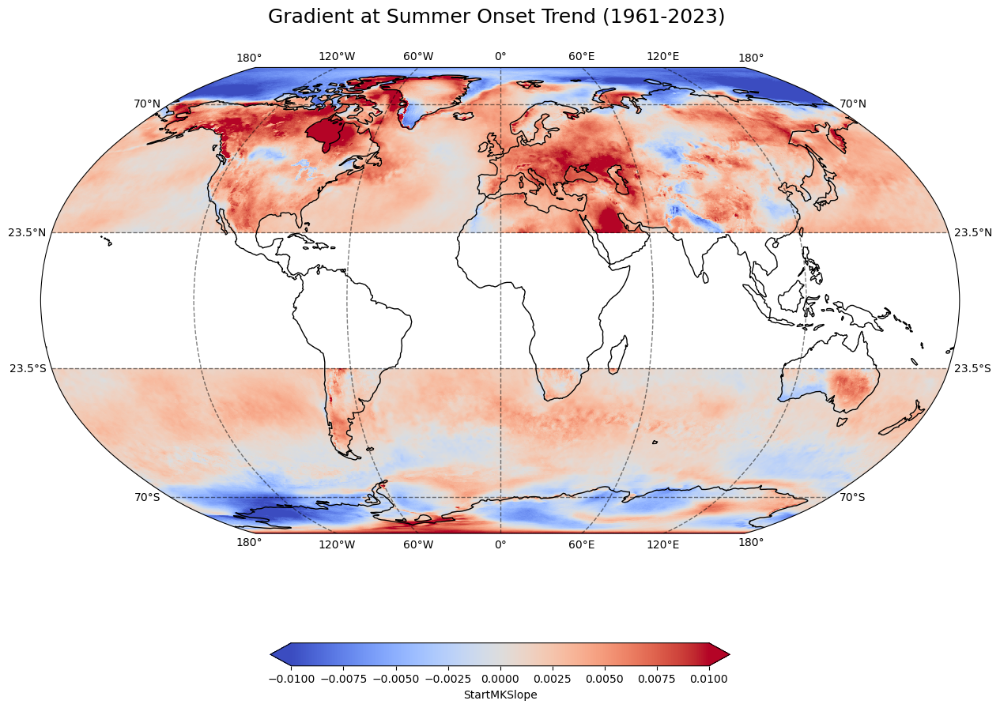

In [6]:

# Global summer length trend
fig = plt.figure(figsize=(15,12))

# assign axis and def projection to use
ax = plt.axes(projection=ccrs.Robinson(central_longitude=0))

# add coastlines and grid
ax.coastlines()
ax.gridlines(draw_labels=True,linewidth=1, color='black', alpha=0.5, ylocs=mticker.FixedLocator([-70, -23.5, 23.5, 70]), linestyle='--')

(results_ds.StartMKSlope.where(((results_ds.lat >= 23.5) | (results_ds.lat <= -23.5)))*10).plot(# & (results_ds_an_p.LengthPvalFDR < 0.1)).plot(
    ax=ax,
    transform=ccrs.PlateCarree(), # assign map projection
    vmin=-0.01,
    vmax=0.01, 
    cmap="coolwarm",#"YlOrRd"#cmap="coolwarm"
    cbar_kwargs={'shrink': 0.5, 'location':'bottom'}
)

plt.title("Gradient at Summer Onset Trend (1961-2023) \n ", fontsize=18)#+" using 1961-1990 baseline")
#plt.savefig("./Plots/"+str(input_year)+"_SummerMeanHS_global.png")
plt.show()

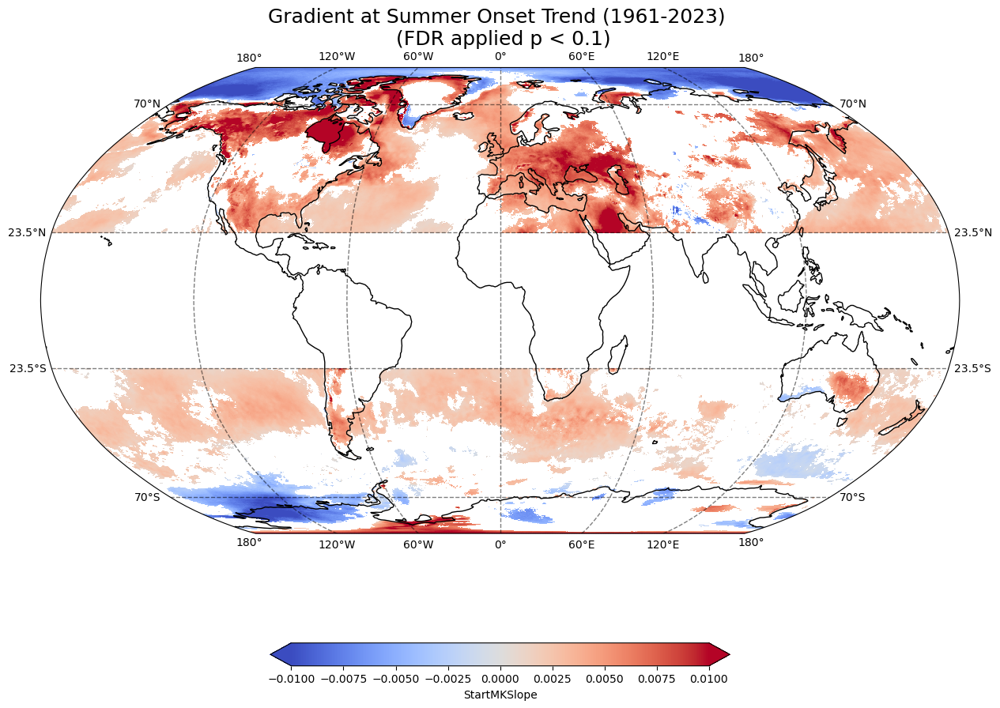

In [36]:

# Global summer length trend
fig = plt.figure(figsize=(15,12))

# assign axis and def projection to use
ax = plt.axes(projection=ccrs.Robinson(central_longitude=0))

# add coastlines and grid
ax.coastlines()
ax.gridlines(draw_labels=True,linewidth=1, color='black', alpha=0.5, ylocs=mticker.FixedLocator([-70, -23.5, 23.5, 70]), linestyle='--')

(results_ds.StartMKSlope.where(((results_ds.lat >= 23.5) | (results_ds.lat <= -23.5)) & (results_ds_p.StartPvalFDR < 0.1))*10).plot(# & (results_ds_an_p.LengthPvalFDR < 0.1)).plot(
    ax=ax,
    transform=ccrs.PlateCarree(), # assign map projection
    vmin=-0.01,
    vmax=0.01, 
    cmap="coolwarm",#"YlOrRd"#cmap="coolwarm"
    cbar_kwargs={'shrink': 0.5, 'location':'bottom'}
)

plt.title("Gradient at Summer Onset Trend (1961-2023) \n (FDR applied p < 0.1)", fontsize=18)#+" using 1961-1990 baseline")
#plt.savefig("./Plots/"+str(input_year)+"_SummerMeanHS_global.png")
plt.show()

#### relabel, adjust units, and make better plot for publication?

In [6]:
# make a copy to keep original intact
res_plot = results_ds.copy(deep=True)

# update to be change in days per decade
res_plot['StartMKSlope'] = res_plot.StartMKSlope * 10

# update attributes
res_plot['StartMKSlope'].attrs["long_name"] = "Change in Gradient at Summer Onset \n"
res_plot['StartMKSlope'].attrs["units"] = "$^{\circ}$C / day / decade"

res_plot, results_ds

(<xarray.Dataset> Size: 25MB
 Dimensions:       (lat: 721, lon: 1440)
 Coordinates:
   * lat           (lat) float64 6kB -90.0 -89.75 -89.5 ... 89.5 89.75 90.0
   * lon           (lon) float64 12kB -180.0 -179.8 -179.5 ... 179.2 179.5 179.8
 Data variables:
     StartMKSlope  (lat, lon) float64 8MB 0.0115 0.0115 ... -0.007081 -0.007081
     StartMKH      (lat, lon) float64 8MB ...
     StartMKP      (lat, lon) float64 8MB 0.0001618 0.0001618 ... 1.768e-05,
 <xarray.Dataset> Size: 25MB
 Dimensions:       (lat: 721, lon: 1440)
 Coordinates:
   * lat           (lat) float64 6kB -90.0 -89.75 -89.5 ... 89.5 89.75 90.0
   * lon           (lon) float64 12kB -180.0 -179.8 -179.5 ... 179.2 179.5 179.8
 Data variables:
     StartMKSlope  (lat, lon) float64 8MB ...
     StartMKH      (lat, lon) float64 8MB ...
     StartMKP      (lat, lon) float64 8MB 0.0001618 0.0001618 ... 1.768e-05)

#### NH only map

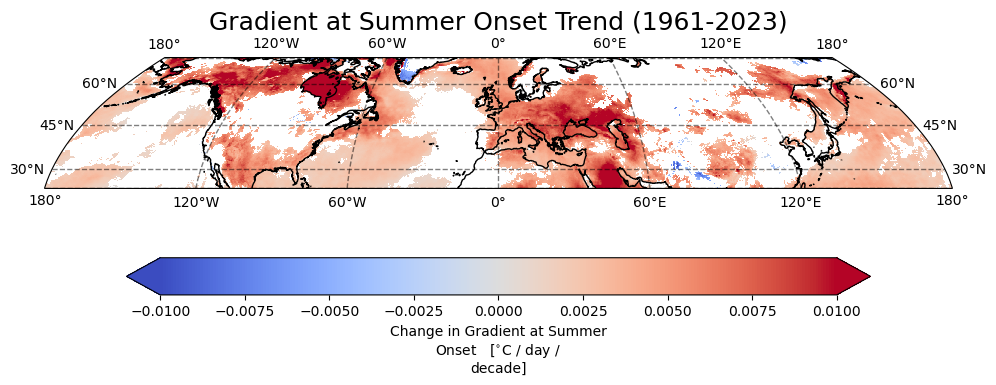

In [39]:
nh_min = 23.5
nh_max = 70

# Global summer length trend
fig = plt.figure(figsize=(12,6))

# assign axis and def projection to use
ax = plt.axes(projection=ccrs.Robinson(central_longitude=0))

# add coastlines and grid
ax.coastlines()
ax.gridlines(draw_labels=True,linewidth=1, color='black', alpha=0.5,  ylocs=mticker.FixedLocator([ 23.5,30,45,60, 70]), linestyle='--')

res_plot.StartMKSlope.sel(lat=slice(nh_min, nh_max)).where((results_ds_p.StartPvalFDR < 0.1)).plot(
    ax=ax,
    transform=ccrs.PlateCarree(), # assign map projection
    vmin=-0.01,
    vmax=0.01, 
    cmap="coolwarm",#"YlOrRd"#cmap="coolwarm"
    cbar_kwargs={'shrink': 0.8, 'location':'bottom'}
)

plt.title("Gradient at Summer Onset Trend (1961-2023)", fontsize=18)#+" using 1961-1990 baseline")
plt.savefig("./Plots/1961-2023_SummerOnset_Grad_Trends_NH_FDR.png",bbox_inches='tight')
plt.savefig("./Plots/1961-2023_SummerOnset_Grad_Trends_NH_FDR.pdf",bbox_inches='tight')
plt.show()

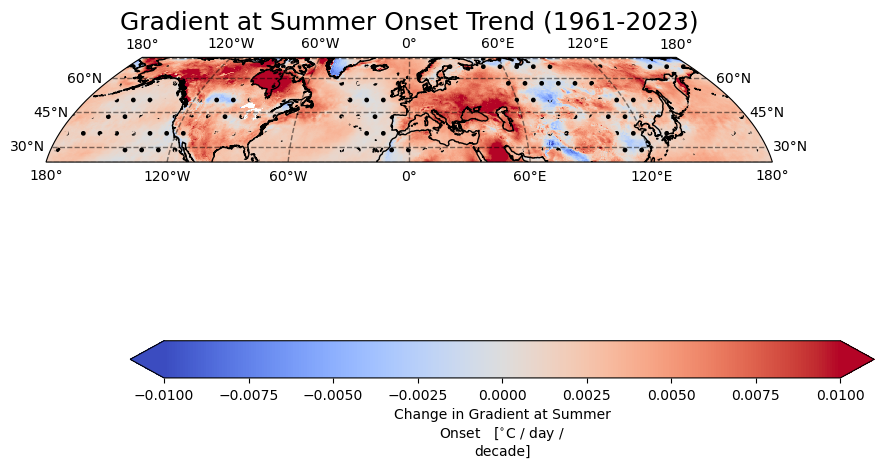

In [11]:
nh_min = 23.5
nh_max = 70

# Global summer length trend
fig = plt.figure(figsize=(12,6))

# assign axis and def projection to use
ax = plt.axes(projection=ccrs.Robinson(central_longitude=0))

# add coastlines and grid
ax.coastlines()
ax.gridlines(draw_labels=True,linewidth=1, color='black', alpha=0.5,  ylocs=mticker.FixedLocator([ 23.5,30,45,60, 70]), linestyle='--')

# filtering out great lakes due to ERA5 issues
mask = res_plot.StartMKSlope.sel(lat=slice(nh_min, nh_max)).where((res_plot.lat > 41) & (res_plot.lat < 49) & (res_plot.lon < -75) & (res_plot.lon > -92)) < 0

res_plot.StartMKSlope.sel(lat=slice(nh_min, nh_max)).where(mask == False).plot(#where((results_ds_p.StartPvalFDR < 0.1)).plot(
    ax=ax,
    transform=ccrs.PlateCarree(), # assign map projection
    vmin=-0.01,
    vmax=0.01, 
    cmap="coolwarm",#"YlOrRd"#cmap="coolwarm"
    cbar_kwargs={'shrink': 0.8, 'location':'bottom'}
)

# points with MK test p-value OVER 0.1
mkNOTsig = res_plot.StartMKP.sel(lat=slice(nh_min, nh_max)) > 0.1

mkNOTsig.where(mkNOTsig.values).plot.contourf(hatches=".", transform=ccrs.PlateCarree(), cmap='none' )#cbar_kwargs={'shrink': 0.0})

# remove the colorbar from the contour
fig.axes[-1].remove()

plt.title("Gradient at Summer Onset Trend (1961-2023)", fontsize=18)#+" using 1961-1990 baseline")
plt.savefig("./Plots/1961-2023_SummerOnset_Grad_Trends_NH_FDR_hatches.png",bbox_inches='tight')
plt.savefig("./Plots/1961-2023_SummerOnset_Grad_Trends_NH_FDR_hatches.pdf",bbox_inches='tight')
plt.show()






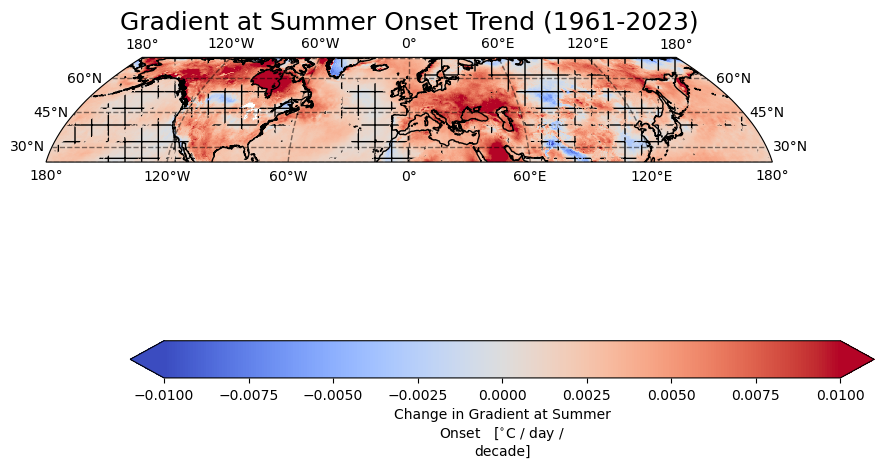

In [8]:
nh_min = 23.5
nh_max = 70

# Global summer length trend
fig = plt.figure(figsize=(12,6))

# assign axis and def projection to use
ax = plt.axes(projection=ccrs.Robinson(central_longitude=0))

# add coastlines and grid
ax.coastlines()
ax.gridlines(draw_labels=True,linewidth=1, color='black', alpha=0.5,  ylocs=mticker.FixedLocator([ 23.5,30,45,60, 70]), linestyle='--')

# filtering out great lakes due to ERA5 issues
mask = res_plot.StartMKSlope.sel(lat=slice(nh_min, nh_max)).where((res_plot.lat > 41) & (res_plot.lat < 49) & (res_plot.lon < -75) & (res_plot.lon > -92)) < 0

res_plot.StartMKSlope.sel(lat=slice(nh_min, nh_max)).where(mask == False).plot(#where((results_ds_p.StartPvalFDR < 0.1)).plot(
    ax=ax,
    transform=ccrs.PlateCarree(), # assign map projection
    vmin=-0.01,
    vmax=0.01, 
    cmap="coolwarm",#"YlOrRd"#cmap="coolwarm"
    cbar_kwargs={'shrink': 0.8, 'location':'bottom'}
)

# points with MK test p-value OVER 0.1
mkNOTsig = res_plot.StartMKP.sel(lat=slice(nh_min, nh_max)) > 0.1

mkNOTsig.where(mkNOTsig.values).plot.contourf(hatches="+", transform=ccrs.PlateCarree(), cmap='none' )#cbar_kwargs={'shrink': 0.0})

# remove the colorbar from the contour
fig.axes[-1].remove()

plt.title("Gradient at Summer Onset Trend (1961-2023)", fontsize=18)#+" using 1961-1990 baseline")
plt.savefig("./Plots/1961-2023_SummerOnset_Grad_Trends_NH_FDR_notsig+.png",bbox_inches='tight')
plt.savefig("./Plots/1961-2023_SummerOnset_Grad_Trends_NH_FDR_notsig+.pdf",bbox_inches='tight')
plt.show()






#### NH only map - unfiltered

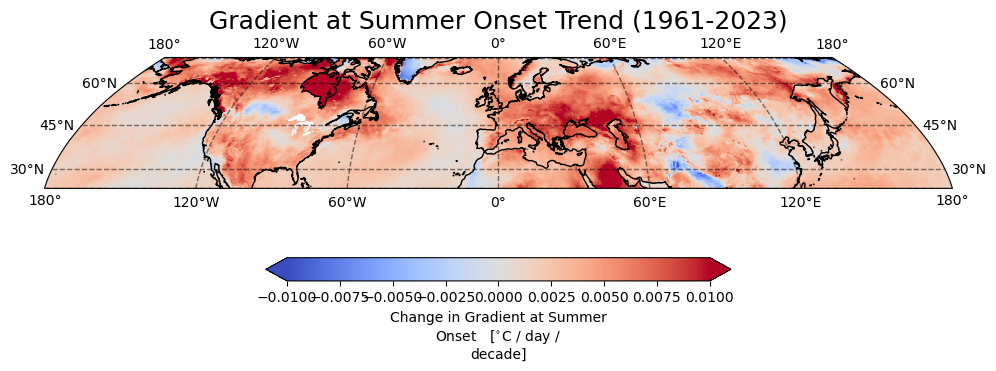

In [9]:
nh_min = 23.5
nh_max = 70

# Global summer length trend
fig = plt.figure(figsize=(12,6))

# assign axis and def projection to use
ax = plt.axes(projection=ccrs.Robinson(central_longitude=0))

# add coastlines and grid
ax.coastlines()
ax.gridlines(draw_labels=True,linewidth=1, color='black', alpha=0.5,  ylocs=mticker.FixedLocator([ 23.5,30,45,60, 70]), linestyle='--')

# filtering out great lakes due to ERA5 issues
mask = res_plot.StartMKSlope.sel(lat=slice(nh_min, nh_max)).where((res_plot.lat > 41) & (res_plot.lat < 49) & (res_plot.lon < -75) & (res_plot.lon > -92)) < 0

res_plot.StartMKSlope.sel(lat=slice(nh_min, nh_max)).where(mask == False).plot(
    ax=ax,
    transform=ccrs.PlateCarree(), # assign map projection
    vmin=-0.01,
    vmax=0.01, 
    cmap="coolwarm",#"YlOrRd"#cmap="coolwarm"
    cbar_kwargs={'shrink': 0.5, 'location':'bottom'}
)

plt.title("Gradient at Summer Onset Trend (1961-2023)", fontsize=18)#+" using 1961-1990 baseline")
plt.savefig("./Plots/1961-2023_SummerOnset_Grad_Trends_NH_unfiltered.png",bbox_inches='tight')
plt.savefig("./Plots/1961-2023_SummerOnset_Grad_Trends_NH_unfiltered.pdf",bbox_inches='tight')
plt.show()

#### SH only map

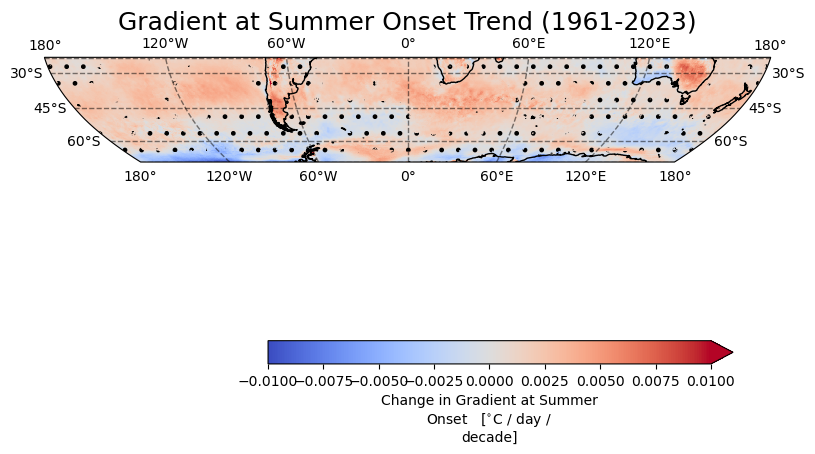

In [14]:
sh_min = -70
sh_max = -23.5

# Global summer length trend
fig = plt.figure(figsize=(12,6))

# assign axis and def projection to use
ax = plt.axes(projection=ccrs.Robinson(central_longitude=0))

# add coastlines and grid
ax.coastlines()
ax.gridlines(draw_labels=True,linewidth=1, color='black', alpha=0.5, ylocs=mticker.FixedLocator([ -70,-60,-45,-30, -23.5]), linestyle='--')

res_plot.StartMKSlope.sel(lat=slice(sh_min, sh_max)).plot(#where((results_ds_p.StartPvalFDR < 0.1)).plot(
    ax=ax,
    transform=ccrs.PlateCarree(), # assign map projection
    vmin=-0.01,
    vmax=0.01, 
    cmap="coolwarm",#"YlOrRd"#cmap="coolwarm"
    cbar_kwargs={'shrink': 0.5, 'location':'bottom'}
)

# points with MK test p-value OVER 0.1
mkNOTsig = res_plot.StartMKP.sel(lat=slice(sh_min, sh_max)) > 0.1

mkNOTsig.where(mkNOTsig.values).plot.contourf(hatches=".", transform=ccrs.PlateCarree(), cmap='none' )#cbar_kwargs={'shrink': 0.0})

# remove the colorbar from the contour
fig.axes[-1].remove()

plt.title("Gradient at Summer Onset Trend (1961-2023)", fontsize=18)#+" using 1961-1990 baseline")
plt.savefig("./Plots/1961-2023_SummerOnset_Grad_Trends_SH_FDR_hatches.png",bbox_inches='tight')
plt.savefig("./Plots/1961-2023_SummerOnset_Grad_Trends_SH_FDR_hatches.pdf",bbox_inches='tight')
plt.show()

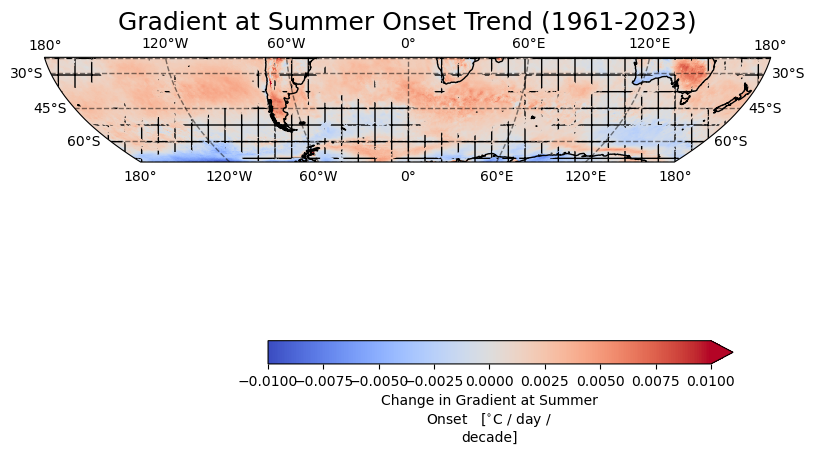

In [10]:
sh_min = -70
sh_max = -23.5

# Global summer length trend
fig = plt.figure(figsize=(12,6))

# assign axis and def projection to use
ax = plt.axes(projection=ccrs.Robinson(central_longitude=0))

# add coastlines and grid
ax.coastlines()
ax.gridlines(draw_labels=True,linewidth=1, color='black', alpha=0.5, ylocs=mticker.FixedLocator([ -70,-60,-45,-30, -23.5]), linestyle='--')

res_plot.StartMKSlope.sel(lat=slice(sh_min, sh_max)).plot(#where((results_ds_p.StartPvalFDR < 0.1)).plot(
    ax=ax,
    transform=ccrs.PlateCarree(), # assign map projection
    vmin=-0.01,
    vmax=0.01, 
    cmap="coolwarm",#"YlOrRd"#cmap="coolwarm"
    cbar_kwargs={'shrink': 0.5, 'location':'bottom'}
)

# points with MK test p-value OVER 0.1
mkNOTsig = res_plot.StartMKP.sel(lat=slice(sh_min, sh_max)) > 0.1

mkNOTsig.where(mkNOTsig.values).plot.contourf(hatches="+", transform=ccrs.PlateCarree(), cmap='none' )#cbar_kwargs={'shrink': 0.0})

# remove the colorbar from the contour
fig.axes[-1].remove()

plt.title("Gradient at Summer Onset Trend (1961-2023)", fontsize=18)#+" using 1961-1990 baseline")
plt.savefig("./Plots/1961-2023_SummerOnset_Grad_Trends_SH_FDR_notsig+.png",bbox_inches='tight')
plt.savefig("./Plots/1961-2023_SummerOnset_Grad_Trends_SH_FDR_notsig+.pdf",bbox_inches='tight')
plt.show()

#### SH only map - unfiltered

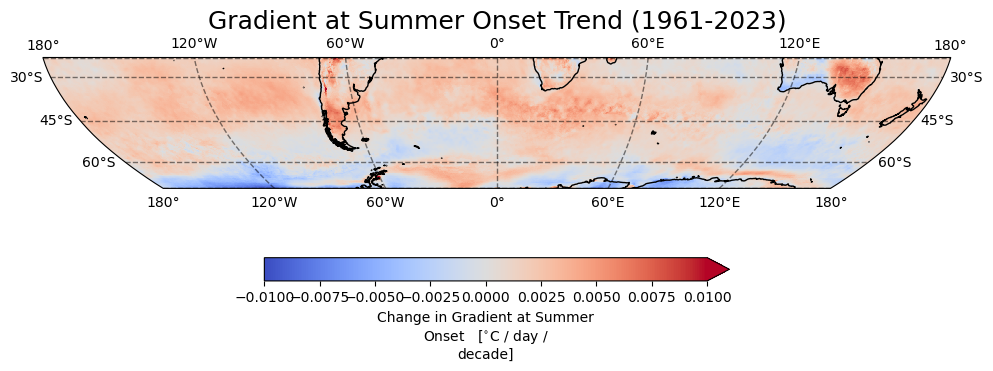

In [7]:
sh_min = -70
sh_max = -23.5

# Global summer length trend
fig = plt.figure(figsize=(12,6))

# assign axis and def projection to use
ax = plt.axes(projection=ccrs.Robinson(central_longitude=0))

# add coastlines and grid
ax.coastlines()
ax.gridlines(draw_labels=True,linewidth=1, color='black', alpha=0.5, ylocs=mticker.FixedLocator([ -70,-60,-45,-30, -23.5]), linestyle='--')

res_plot.StartMKSlope.sel(lat=slice(sh_min, sh_max)).plot(
    ax=ax,
    transform=ccrs.PlateCarree(), # assign map projection
    vmin=-0.01,
    vmax=0.01, 
    cmap="coolwarm",#"YlOrRd"#cmap="coolwarm"
    cbar_kwargs={'shrink': 0.5, 'location':'bottom'}
)

plt.title("Gradient at Summer Onset Trend (1961-2023)", fontsize=18)#+" using 1961-1990 baseline")
plt.savefig("./Plots/1961-2023_SummerOnset_Grad_Trends_SH_unfiltered.png",bbox_inches='tight')
plt.savefig("./Plots/1961-2023_SummerOnset_Grad_Trends_SH_unfiltered.pdf",bbox_inches='tight')

plt.show()

### 1990-2023: Plot with hatching from MK test

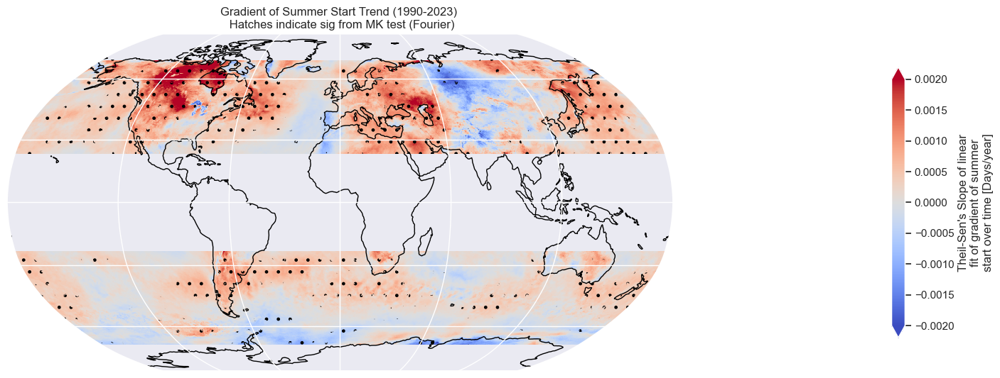

In [18]:

# Global summer start trend
fig = plt.figure(figsize=(15,8))

# assign axis and def projection to use
ax = plt.axes(projection=ccrs.Robinson(central_longitude=0))

# add coastlines and grid
ax.coastlines()
ax.gridlines()

results_ds_an.StartMKSlope.where((((results_ds_an.lat >= 23.5) & (results_ds_an.lat <= 70)) | 
                              ((results_ds_an.lat <= -23.5) & (results_ds_an.lat >= -70)))).plot(
    ax=ax,
    transform=ccrs.PlateCarree(), # assign map projection
    vmin=-0.002,
    vmax=0.002, 
    cmap="coolwarm",#"YlOrRd"#cmap="coolwarm"
    cbar_kwargs={'shrink': 0.5}
)

# points with MK test p-value under 0.05
mksig = results_ds_an.StartMKP.where((((results_ds_an.lat >= 23.5) & (results_ds_an.lat <= 70)) | 
                              ((results_ds_an.lat <= -23.5) & (results_ds_an.lat >= -70)))) <= 0.1

mksig.where(mksig.values).plot.contourf(hatches="..", transform=ccrs.PlateCarree(), 
                                        #colors='none', 
                                        cmap='none' )#cbar_kwargs={'shrink': 0.0})

# remove the colorbar from the contour
fig.axes[-1].remove()

plt.title("Gradient of Summer Start Trend (1990-2023) \n Hatches indicate sig from MK test (Fourier)")#+" using 1961-1990 baseline")
#plt.savefig("./Plots/"+str(input_year)+"_SummerMeanHS_global.png")
plt.tight_layout()
plt.show()

#### FDR applied

In [42]:
np.sum(results_ds_an.StartMKP.values <= 0), np.sum(results_ds_an.StartMKP.values == 0), np.sum(results_ds_an.StartMKP.values == 1)

(np.int64(2124), np.int64(2124), np.int64(13610))

In [43]:
# have to replace the zeroes and ones with values between 0 and 1 for FDR
results_ds_an_p = results_ds_an.StartMKP
results_ds_an_p = results_ds_an_p.where(results_ds_an_p.values > 0)
results_ds_an_p = results_ds_an_p.fillna(1e-10) # fix zeroes
results_ds_an_p
#np.sum(results_ds_an_tmp.LengthMKP.values <= 0)
results_ds_an_p = results_ds_an_p.where(results_ds_an_p.values < 1.0)
results_ds_an_p
results_ds_an_p = results_ds_an_p.fillna(0.999) # fix ones
results_ds_an_p

<xarray.DataArray 'StartMKP' (lat: 721, lon: 1440)> Size: 8MB
array([[0.27263754, 0.27263754, 0.27263754, ..., 0.27263754, 0.27263754,
        0.27263754],
       [0.25988724, 0.25988724, 0.25988724, ..., 0.25988724, 0.25988724,
        0.25988724],
       [0.08789355, 0.08789355, 0.08789355, ..., 0.09277412, 0.09487676,
        0.08789355],
       ...,
       [0.42340962, 0.42340962, 0.42340962, ..., 0.38988953, 0.38988953,
        0.38988953],
       [0.40644334, 0.40644334, 0.40644334, ..., 0.39806275, 0.40644334,
        0.40644334],
       [0.55319605, 0.55319605, 0.55319605, ..., 0.55319605, 0.55319605,
        0.55319605]], shape=(721, 1440))
Coordinates:
  * lat      (lat) float64 6kB -90.0 -89.75 -89.5 -89.25 ... 89.5 89.75 90.0
  * lon      (lon) float64 12kB -180.0 -179.8 -179.5 ... 179.2 179.5 179.8
Attributes:
    long_name:  Hamed & Rao MK test for significance (p-value) of trend
    units:      None

In [44]:
# use func from scipi.stats
pval_fdr_cor = stats.false_discovery_control(results_ds_an_p.values)

# add as variable to dataset
results_ds_an_p['StartPvalFDR'] = (['lat','lon'], pval_fdr_cor)

results_ds_an_p

<xarray.DataArray 'StartMKP' (lat: 721, lon: 1440)> Size: 8MB
array([[0.27263754, 0.27263754, 0.27263754, ..., 0.27263754, 0.27263754,
        0.27263754],
       [0.25988724, 0.25988724, 0.25988724, ..., 0.25988724, 0.25988724,
        0.25988724],
       [0.08789355, 0.08789355, 0.08789355, ..., 0.09277412, 0.09487676,
        0.08789355],
       ...,
       [0.42340962, 0.42340962, 0.42340962, ..., 0.38988953, 0.38988953,
        0.38988953],
       [0.40644334, 0.40644334, 0.40644334, ..., 0.39806275, 0.40644334,
        0.40644334],
       [0.55319605, 0.55319605, 0.55319605, ..., 0.55319605, 0.55319605,
        0.55319605]], shape=(721, 1440))
Coordinates:
  * lat           (lat) float64 6kB -90.0 -89.75 -89.5 ... 89.5 89.75 90.0
  * lon           (lon) float64 12kB -180.0 -179.8 -179.5 ... 179.2 179.5 179.8
    StartPvalFDR  (lat, lon) float64 8MB 0.4078 0.4138 0.4191 ... 0.6818 0.6925
Attributes:
    long_name:  Hamed & Rao MK test for significance (p-value) of trend
    units:      None

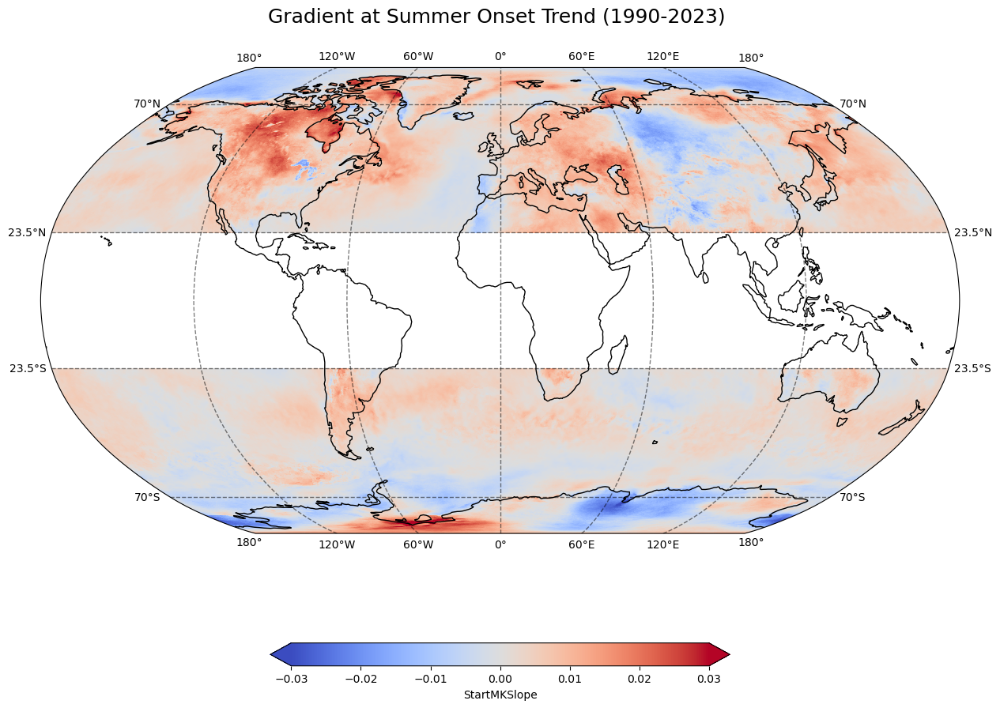

In [45]:

# Global summer length trend
fig = plt.figure(figsize=(15,12))

# assign axis and def projection to use
ax = plt.axes(projection=ccrs.Robinson(central_longitude=0))

# add coastlines and grid
ax.coastlines()
ax.gridlines(draw_labels=True,linewidth=1, color='black', alpha=0.5, ylocs=mticker.FixedLocator([-70, -23.5, 23.5, 70]), linestyle='--')

(results_ds_an.StartMKSlope.where(((results_ds_an.lat >= 23.5) | (results_ds_an.lat <= -23.5)))*10).plot(# & (results_ds_an_p.LengthPvalFDR < 0.1)).plot(
    ax=ax,
    transform=ccrs.PlateCarree(), # assign map projection
    vmin=-0.03,
    vmax=0.03, 
    cmap="coolwarm",#"YlOrRd"#cmap="coolwarm"
    cbar_kwargs={'shrink': 0.5, 'location':'bottom'}
)

plt.title("Gradient at Summer Onset Trend (1990-2023) \n ", fontsize=18)#+" using 1961-1990 baseline")
#plt.savefig("./Plots/"+str(input_year)+"_SummerMeanHS_global.png")
plt.show()

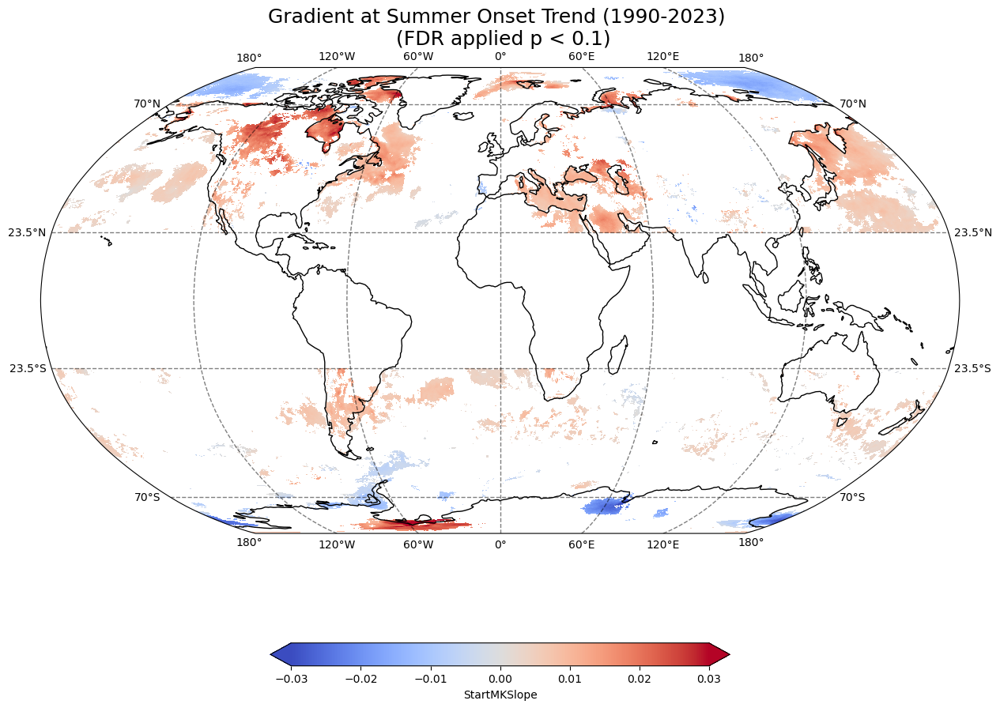

In [46]:

# Global summer length trend
fig = plt.figure(figsize=(15,12))

# assign axis and def projection to use
ax = plt.axes(projection=ccrs.Robinson(central_longitude=0))

# add coastlines and grid
ax.coastlines()
ax.gridlines(draw_labels=True,linewidth=1, color='black', alpha=0.5, ylocs=mticker.FixedLocator([-70, -23.5, 23.5, 70]), linestyle='--')

(results_ds_an.StartMKSlope.where(((results_ds_an.lat >= 23.5) | (results_ds_an.lat <= -23.5)) & (results_ds_an_p.StartPvalFDR < 0.1))*10).plot(# & (results_ds_an_p.LengthPvalFDR < 0.1)).plot(
    ax=ax,
    transform=ccrs.PlateCarree(), # assign map projection
    vmin=-0.03,
    vmax=0.03, 
    cmap="coolwarm",#"YlOrRd"#cmap="coolwarm"
    cbar_kwargs={'shrink': 0.5, 'location':'bottom'}
)

plt.title("Gradient at Summer Onset Trend (1990-2023) \n (FDR applied p < 0.1)", fontsize=18)#+" using 1961-1990 baseline")
#plt.savefig("./Plots/"+str(input_year)+"_SummerMeanHS_global.png")
plt.show()

#### relabel, adjust units, and make better plot for publication?

In [47]:
# make a copy to keep original intact
res_plot = results_ds_an.copy(deep=True)

# update to be change in days per decade
res_plot['StartMKSlope'] = res_plot.StartMKSlope * 10

# update attributes
res_plot['StartMKSlope'].attrs["long_name"] = "Change in Gradient of Summer Start \n"
res_plot['StartMKSlope'].attrs["units"] = "K / day / 10 yrs"

res_plot, results_ds_an

(<xarray.Dataset> Size: 25MB
 Dimensions:       (lat: 721, lon: 1440)
 Coordinates:
   * lat           (lat) float64 6kB -90.0 -89.75 -89.5 ... 89.5 89.75 90.0
   * lon           (lon) float64 12kB -180.0 -179.8 -179.5 ... 179.2 179.5 179.8
 Data variables:
     StartMKSlope  (lat, lon) float64 8MB 0.01046 0.01046 ... -0.003822 -0.003822
     StartMKH      (lat, lon) float64 8MB ...
     StartMKP      (lat, lon) float64 8MB 0.2726 0.2726 0.2726 ... 0.5532 0.5532,
 <xarray.Dataset> Size: 25MB
 Dimensions:       (lat: 721, lon: 1440)
 Coordinates:
   * lat           (lat) float64 6kB -90.0 -89.75 -89.5 ... 89.5 89.75 90.0
   * lon           (lon) float64 12kB -180.0 -179.8 -179.5 ... 179.2 179.5 179.8
 Data variables:
     StartMKSlope  (lat, lon) float64 8MB ...
     StartMKH      (lat, lon) float64 8MB ...
     StartMKP      (lat, lon) float64 8MB 0.2726 0.2726 0.2726 ... 0.5532 0.5532)

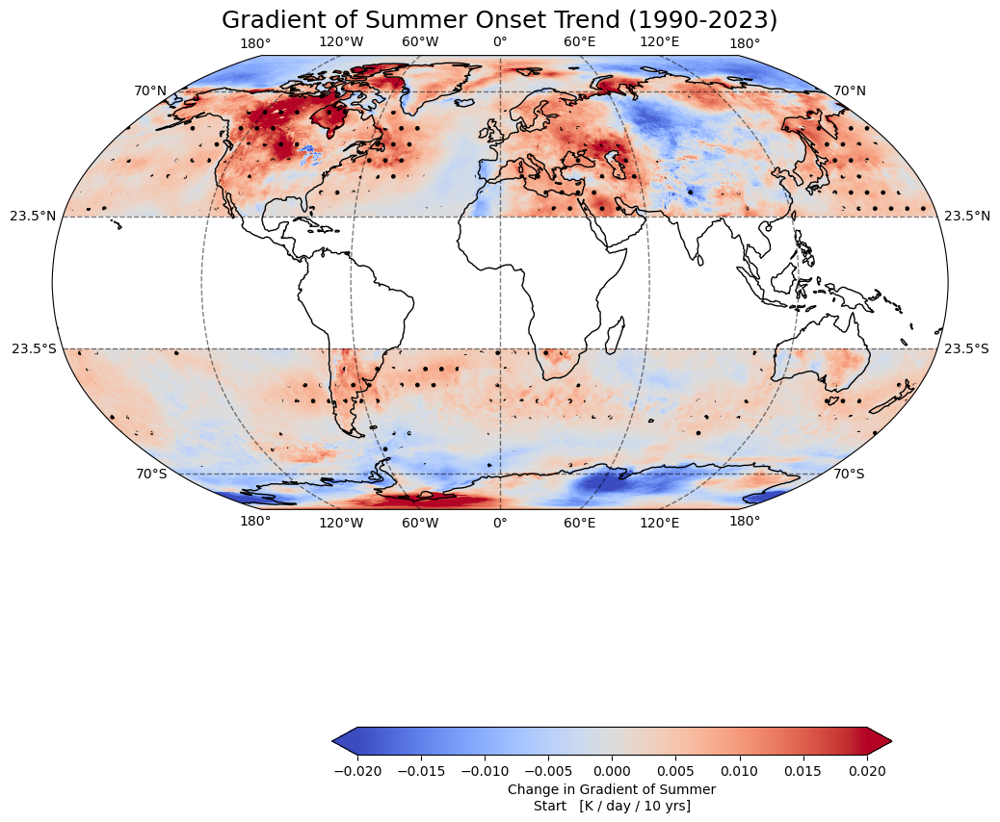

In [48]:

# Global summer length trend
fig = plt.figure(figsize=(15,12))

# assign axis and def projection to use
ax = plt.axes(projection=ccrs.Robinson(central_longitude=0))

# add coastlines and grid
ax.coastlines()
ax.gridlines(draw_labels=True,linewidth=1, color='black', alpha=0.5, ylocs=mticker.FixedLocator([-70, -23.5, 23.5, 70]), linestyle='--')

res_plot.StartMKSlope.where((res_plot.lat >= 23.5) | (res_plot.lat <= -23.5)).plot(
    ax=ax,
    transform=ccrs.PlateCarree(), # assign map projection
    vmin=-0.02,
    vmax=0.02, 
    cmap="coolwarm",#"YlOrRd"#cmap="coolwarm"
    cbar_kwargs={'shrink': 0.5, 'location':'bottom'}
)

# points with MK test p-value under 0.05
mksig = res_plot.StartMKP.where((((res_plot.lat >= 23.5) & (res_plot.lat <= 70)) | 
                              ((res_plot.lat <= -23.5) & (res_plot.lat >= -70)))) <= 0.05

mksig.where(mksig.values).plot.contourf(hatches="..", transform=ccrs.PlateCarree(), 
                                        #colors='none', 
                                        cmap='none' )#cbar_kwargs={'shrink': 0.0})

# remove the colorbar from the contour
fig.axes[-1].remove()

plt.title("Gradient of Summer Onset Trend (1990-2023)", fontsize=18)#+" using 1961-1990 baseline")
#plt.savefig("./Plots/"+str(input_year)+"_SummerMeanHS_global.png")
plt.show()

#### NH only map

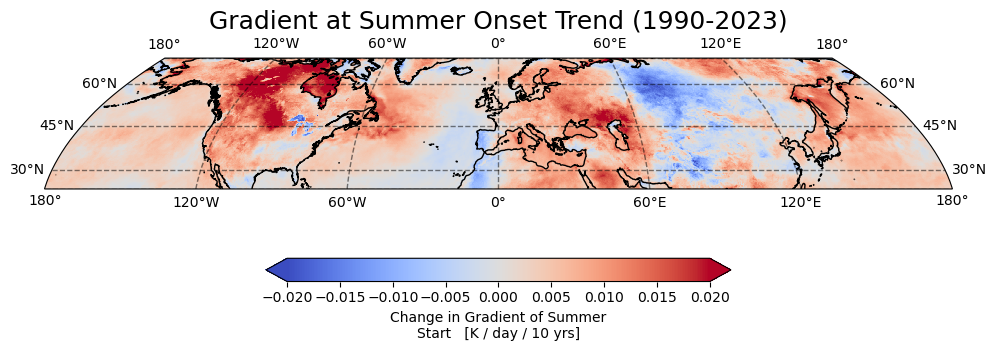

In [49]:
nh_min = 23.5
nh_max = 70

# Global summer length trend
fig = plt.figure(figsize=(12,6))

# assign axis and def projection to use
ax = plt.axes(projection=ccrs.Robinson(central_longitude=0))

# add coastlines and grid
ax.coastlines()
ax.gridlines(draw_labels=True,linewidth=1, color='black', alpha=0.5,  ylocs=mticker.FixedLocator([ 23.5,30,45,60, 70]), linestyle='--')

res_plot.StartMKSlope.sel(lat=slice(nh_min, nh_max)).plot(
    ax=ax,
    transform=ccrs.PlateCarree(), # assign map projection
    vmin=-0.02,
    vmax=0.02, 
    cmap="coolwarm",#"YlOrRd"#cmap="coolwarm"
    cbar_kwargs={'shrink': 0.5, 'location':'bottom'}
)

plt.title("Gradient at Summer Onset Trend (1990-2023)", fontsize=18)#+" using 1961-1990 baseline")
plt.savefig("./Plots/1990-2023_SummerOnset_Grad_Trends_NH.png")
plt.show()

#### SH only map

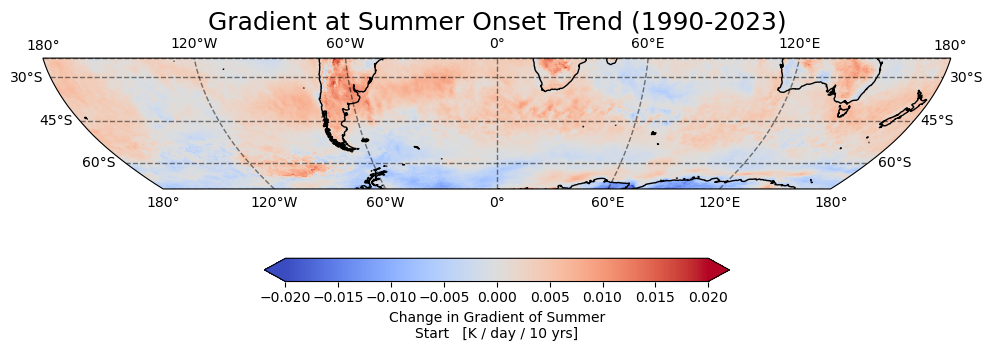

In [50]:
sh_min = -70
sh_max = -23.5

# Global summer length trend
fig = plt.figure(figsize=(12,6))

# assign axis and def projection to use
ax = plt.axes(projection=ccrs.Robinson(central_longitude=0))

# add coastlines and grid
ax.coastlines()
ax.gridlines(draw_labels=True,linewidth=1, color='black', alpha=0.5, ylocs=mticker.FixedLocator([ -70,-60,-45,-30, -23.5]), linestyle='--')

res_plot.StartMKSlope.sel(lat=slice(sh_min, sh_max)).plot(
    ax=ax,
    transform=ccrs.PlateCarree(), # assign map projection
    vmin=-0.02,
    vmax=0.02, 
    cmap="coolwarm",#"YlOrRd"#cmap="coolwarm"
    cbar_kwargs={'shrink': 0.5, 'location':'bottom'}
)

plt.title("Gradient at Summer Onset Trend (1990-2023)", fontsize=18)#+" using 1961-1990 baseline")
plt.savefig("./Plots/1990-2023_SummerOnset_Grad_Trends_SH.png")
plt.show()

#### hatching where NOT significant at p <= 0.1

In [51]:
# #sns.set_theme(style="darkgrid", rc={"patch.edgecolor": "black"})
# #sns.set_theme()
# nh_min = 23.5
# nh_max = 70


# # Global summer length trend
# fig = plt.figure(figsize=(14,8))

# # assign axis and def projection to use
# ax = plt.axes(projection=ccrs.Robinson(central_longitude=0))

# # add coastlines and grid
# ax.coastlines()
# ax.gridlines(draw_labels=True,linewidth=1, color='black', alpha=0.5,  ylocs=mticker.FixedLocator([ 23.5,30,45,60, 70]), linestyle='--')

# res_plot.StartMKSlope.sel(lat=slice(nh_min, nh_max)).plot(
#     ax=ax,
#     transform=ccrs.PlateCarree(), # assign map projection
#     vmin=-0.02,
#     vmax=0.02, 
#     cmap="coolwarm",#"YlOrRd"#cmap="coolwarm"
#     cbar_kwargs={'shrink': 0.5, 'location':'bottom'}
# )

# # points with MK test p-value OVER 0.1
# mkNOTsig = res_plot.StartMKP.sel(lat=slice(nh_min, nh_max)) > 0.1

# mkNOTsig.where(mkNOTsig.values).plot.contourf(hatches=".", transform=ccrs.PlateCarree(), cmap='none' )#cbar_kwargs={'shrink': 0.0})

# # remove the colorbar from the contour
# fig.axes[-1].remove()

# plt.title("Gradient at Summer Onset Trend (1990-2023)", fontsize=18)#+" using 1961-1990 baseline")
# plt.savefig("./Plots/1990-2023_SummerOnset_Grad_Trends_NH.png")
# plt.show()


In [52]:
# sh_min = -70
# sh_max = -23.5

# # Global summer length trend
# fig = plt.figure(figsize=(12,6))

# # assign axis and def projection to use
# ax = plt.axes(projection=ccrs.Robinson(central_longitude=0))

# # add coastlines and grid
# ax.coastlines()
# ax.gridlines(draw_labels=True,linewidth=1, color='black', alpha=0.5, ylocs=mticker.FixedLocator([ -70,-60,-45,-30, -23.5]), linestyle='--')

# res_plot.StartMKSlope.sel(lat=slice(sh_min, sh_max)).plot(
#     ax=ax,
#     transform=ccrs.PlateCarree(), # assign map projection
#     vmin=-0.02,
#     vmax=0.02, 
#     cmap="coolwarm",#"YlOrRd"#cmap="coolwarm"
#     cbar_kwargs={'shrink': 0.5, 'location':'bottom'}
# )

# # points with MK test p-value OVER 0.1
# mkNOTsig = res_plot.StartMKP.sel(lat=slice(sh_min, sh_max)) > 0.1

# mkNOTsig.where(mkNOTsig.values).plot.contourf(hatches=".", transform=ccrs.PlateCarree(), cmap='none' )#cbar_kwargs={'shrink': 0.0})

# # remove the colorbar from the contour
# fig.axes[-1].remove()

# plt.title("Gradient at Summer Onset Trend (1990-2023)", fontsize=18)#+" using 1961-1990 baseline")
# plt.savefig("./Plots/1990-2023_SummerOnset_Grad_Trends_SH.png")
# plt.show()

#### NH only map

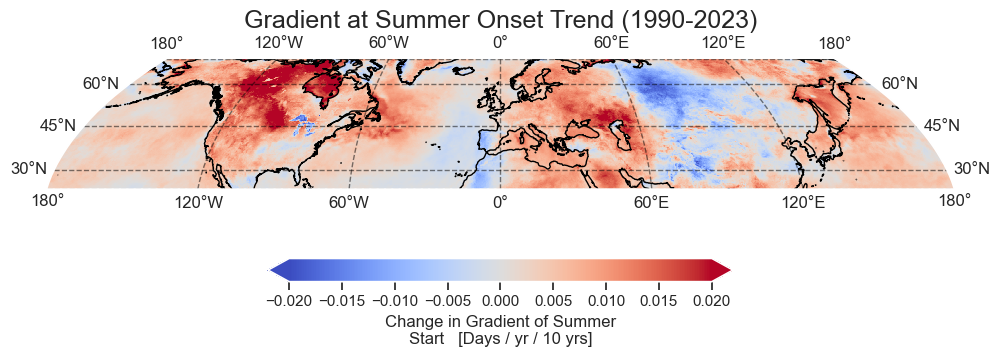

In [23]:
nh_min = 23.5
nh_max = 70

# Global summer length trend
fig = plt.figure(figsize=(12,6))

# assign axis and def projection to use
ax = plt.axes(projection=ccrs.Robinson(central_longitude=0))

# add coastlines and grid
ax.coastlines()
ax.gridlines(draw_labels=True,linewidth=1, color='black', alpha=0.5,  ylocs=mticker.FixedLocator([ 23.5,30,45,60, 70]), linestyle='--')

res_plot.StartMKSlope.sel(lat=slice(nh_min, nh_max)).plot(
    ax=ax,
    transform=ccrs.PlateCarree(), # assign map projection
    vmin=-0.02,
    vmax=0.02, 
    cmap="coolwarm",#"YlOrRd"#cmap="coolwarm"
    cbar_kwargs={'shrink': 0.5, 'location':'bottom'}
)

plt.title("Gradient at Summer Onset Trend (1990-2023)", fontsize=18)#+" using 1961-1990 baseline")
#plt.savefig("./Plots/1990-2023_SummerOnset_Grad_Trends_NH.png")
plt.show()

### North America MK test only

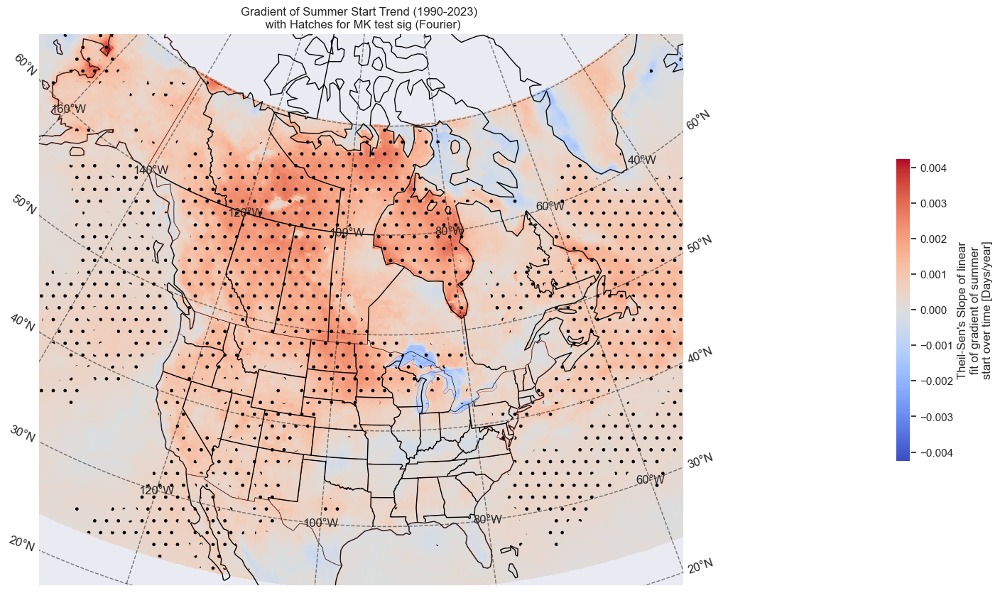

In [165]:

central_longitude = -(91 + 52 / 60)
central_latitude = 40

############
#Global map of summer start
fig = plt.figure(figsize=(15,9))

# assign axis and def projection to use
ax = plt.axes(projection=ccrs.LambertConformal(central_longitude=central_longitude, central_latitude=central_latitude))

# add coastlines and grid
ax.coastlines()
ax.gridlines(draw_labels=True, linewidth=1, color='black', alpha=0.5, linestyle='--')

dataplot = results_ds_an.StartMKSlope.where((((ds_start_analysis.lat >= 23.5) & (ds_start_analysis.lat <= 70)) | 
                              ((ds_start_analysis.lat <= -23.5) & (ds_start_analysis.lat >= -70)))).plot(
    ax=ax,
    transform=ccrs.PlateCarree(), # assign map projection
    #vmin=-0.5,
    #vmax=0.5, 
    cmap="coolwarm",
    cbar_kwargs={'shrink': 0.5}
    
)

# points with MK test p-value under 0.05
mksig = results_ds_an.StartMKP.where((((ds_start_analysis.lat >= 23.5) & (ds_start_analysis.lat <= 70)) | 
                              ((ds_start_analysis.lat <= -23.5) & (ds_start_analysis.lat >= -70)))) <= 0.1

mksig.where(mksig.values).plot.contourf(hatches=".", transform=ccrs.PlateCarree(), 
                                        #colors='none', 
                                        cmap='none' )#cbar_kwargs={'shrink': 0.0})

# remove the colorbar from the contour
fig.axes[-1].remove()



ax.set_extent((-130, -60, 20, 75))

provinces_50m = cfeature.NaturalEarthFeature('cultural',
                                             'admin_1_states_provinces_lines',
                                             '50m',
                                             facecolor='none')
ax.add_feature(cfeature.BORDERS, linewidth=0.5, edgecolor='black')
ax.add_feature(cfeature.STATES, linewidth=0.3, edgecolor='brown')
ax.add_feature(provinces_50m)
plt.title("Gradient of Summer Start Trend (1990-2023) \n with Hatches for MK test sig (Fourier)")#+" using 1961-1990 baseline")
#plt.savefig("./Plots/"+str(input_year)+"_SummerMeanHS_global.png")
plt.tight_layout()
#plt.savefig("./Plots/"+str(input_year)+"_SummerLength_global.png")
plt.show()


## Gradient of Summer End Trends

In [87]:
ds_full_end = ds_full.GradientSummEndFourier
ds_full_end

<xarray.DataArray 'GradientSummEndFourier' (time: 63, lat: 721, lon: 1440)> Size: 523MB
[65409120 values with dtype=float64]
Coordinates:
  * lat      (lat) float64 6kB -90.0 -89.75 -89.5 -89.25 ... 89.5 89.75 90.0
  * lon      (lon) float64 12kB -180.0 -179.8 -179.5 ... 179.2 179.5 179.8
  * time     (time) datetime64[ns] 504B 1961-01-01 1962-01-01 ... 2023-01-01
Attributes:
    long_name:  Gradient of Fourier Fit at Summer End
    units:      Deg/Day

In [88]:
%%time

# takes 27 min for 63 years with MK test!

# grid parameters for looping
num_lat = 721
num_lon = 1440

loop_lats = ds_full_end.lat.values[:num_lat]
loop_lons = ds_full_end.lon.values[:num_lon]

# empty data arrays for summer stats
# variables from modified mann-kendall test (Hamed & Rao)
end_mkslope = xr.DataArray(np.zeros((num_lat,num_lon)), 
                            coords=[loop_lats, loop_lons], 
                            dims=['lat','lon'])

end_mkh = xr.DataArray(np.zeros((num_lat,num_lon)), 
                           coords=[loop_lats, loop_lons], 
                           dims=['lat','lon'])

end_mkp = xr.DataArray(np.zeros((num_lat,num_lon)), 
                           coords=[loop_lats, loop_lons], 
                           dims=['lat','lon'])


# add attributes
end_mkslope.attrs["long_name"] = "Theil-Sen's Slope of linear fit of gradient of summer end over time"
end_mkslope.attrs["units"] = "Days/year"

end_mkh.attrs["long_name"] = "Hamed & Rao MK test for presence of trend"
end_mkh.attrs["units"] = "Binary"

end_mkp.attrs["long_name"] = "Hamed & Rao MK test for significance (p-value) of trend"
end_mkp.attrs["units"] = "None"



# loop through all of the lat,lon of interest
for input_lat in loop_lats:
    for input_lon in loop_lons:

        # create x & y values for linear fit
        x = ds_full_end.time.dt.year.values
        y = ds_full_end.sel(lat=input_lat, lon=input_lon).values

        # Modified Mann-Kendall (hamed & Rao) results
        result_mk = mk.hamed_rao_modification_test(y)
        end_mkslope.loc[input_lat, input_lon] = result_mk.slope
        end_mkh.loc[input_lat, input_lon] = result_mk.h
        end_mkp.loc[input_lat, input_lon] = result_mk.p

        
# results dataset
results_ds = xr.Dataset(data_vars={'EndMKSlope':end_mkslope,
                           'EndMKH':end_mkh,
                           'EndMKP':end_mkp
                                  })

# see results
results_ds

CPU times: user 24min 41s, sys: 2min 42s, total: 27min 23s
Wall time: 27min 53s


<xarray.Dataset> Size: 25MB
Dimensions:     (lat: 721, lon: 1440)
Coordinates:
  * lat         (lat) float64 6kB -90.0 -89.75 -89.5 -89.25 ... 89.5 89.75 90.0
  * lon         (lon) float64 12kB -180.0 -179.8 -179.5 ... 179.2 179.5 179.8
Data variables:
    EndMKSlope  (lat, lon) float64 8MB -0.0008538 -0.0008538 ... 0.001141
    EndMKH      (lat, lon) float64 8MB 1.0 1.0 1.0 1.0 1.0 ... 1.0 1.0 1.0 1.0
    EndMKP      (lat, lon) float64 8MB 0.002769 0.002769 0.002769 ... 0.0 0.0

### Summer End trends over analysis period: 1990-2023

In [91]:
# restrict to 1990-2023
ds_end_analysis = ds_full_end.sel(time=slice('1990','2023'))
ds_end_analysis
                                    

<xarray.DataArray 'GradientSummEndFourier' (time: 34, lat: 721, lon: 1440)> Size: 282MB
[35300160 values with dtype=float64]
Coordinates:
  * lat      (lat) float64 6kB -90.0 -89.75 -89.5 -89.25 ... 89.5 89.75 90.0
  * lon      (lon) float64 12kB -180.0 -179.8 -179.5 ... 179.2 179.5 179.8
  * time     (time) datetime64[ns] 272B 1990-01-01 1991-01-01 ... 2023-01-01
Attributes:
    long_name:  Gradient of Fourier Fit at Summer End
    units:      Deg/Day

### Linear trends for each grid cell 1990-2023

In [92]:
%%time

# takes 20 min for 34 years w/ MK test

# grid parameters for looping
num_lat = 721
num_lon = 1440

loop_lats = ds_end_analysis.lat.values[:num_lat]
loop_lons = ds_end_analysis.lon.values[:num_lon]


# empty data arrays for summer stats
# variables from modified mann-kendall test (Hamed & Rao)
end_mkslope = xr.DataArray(np.zeros((num_lat,num_lon)), 
                            coords=[loop_lats, loop_lons], 
                            dims=['lat','lon'])

end_mkh = xr.DataArray(np.zeros((num_lat,num_lon)), 
                           coords=[loop_lats, loop_lons], 
                           dims=['lat','lon'])

end_mkp = xr.DataArray(np.zeros((num_lat,num_lon)), 
                           coords=[loop_lats, loop_lons], 
                           dims=['lat','lon'])


# add attributes
end_mkslope.attrs["long_name"] = "Theil-Sen's Slope of linear fit of gradient of summer end over time"
end_mkslope.attrs["units"] = "Days/year"

end_mkh.attrs["long_name"] = "Hamed & Rao MK test for presence of trend"
end_mkh.attrs["units"] = "Binary"

end_mkp.attrs["long_name"] = "Hamed & Rao MK test for significance (p-value) of trend"
end_mkp.attrs["units"] = "None"



# loop through all of the lat,lon of interest
for input_lat in loop_lats:
    for input_lon in loop_lons:

        # create x & y values for linear fit
        x = ds_end_analysis.time.dt.year.values
        y = ds_end_analysis.sel(lat=input_lat, lon=input_lon).values

        # Modified Mann-Kendall (hamed & Rao) results
        result_mk = mk.hamed_rao_modification_test(y)
        end_mkslope.loc[input_lat, input_lon] = result_mk.slope
        end_mkh.loc[input_lat, input_lon] = result_mk.h
        end_mkp.loc[input_lat, input_lon] = result_mk.p

        
# results dataset
results_ds_an = xr.Dataset(data_vars={'EndMKSlope':end_mkslope,
                           'EndMKH':end_mkh,
                           'EndMKP':end_mkp
                                  })

# see results
results_ds_an

CPU times: user 19min 42s, sys: 1min 24s, total: 21min 7s
Wall time: 21min 10s


<xarray.Dataset> Size: 25MB
Dimensions:     (lat: 721, lon: 1440)
Coordinates:
  * lat         (lat) float64 6kB -90.0 -89.75 -89.5 -89.25 ... 89.5 89.75 90.0
  * lon         (lon) float64 12kB -180.0 -179.8 -179.5 ... 179.2 179.5 179.8
Data variables:
    EndMKSlope  (lat, lon) float64 8MB -0.0001097 -0.0001097 ... 0.001456
    EndMKH      (lat, lon) float64 8MB 0.0 0.0 0.0 0.0 0.0 ... 1.0 1.0 1.0 1.0
    EndMKP      (lat, lon) float64 8MB 0.8469 0.8469 ... 4.707e-05 4.707e-05

### Output Summer End trends

In [95]:
# write those results out for later use
output_path = '../../../Data/ERA5-global/Analysis/New-Fourier/Gradients/1961-2023_EndGradTrends.nc'
results_ds.to_netcdf(output_path)

output_path2 = '../../../Data/ERA5-global/Analysis/New-Fourier/Gradients/1990-2023_EndGradTrends.nc'
results_ds_an.to_netcdf(output_path2)

## Read the end trends back in to make plots

In [11]:
input_path = '../../../Data/ERA5-global/Analysis/New-Fourier/Gradients/1961-2023_EndGradTrends.nc'
results_ds = xr.open_dataset(input_path)

input_path2 = '../../../Data/ERA5-global/Analysis/New-Fourier/Gradients/1990-2023_EndGradTrends.nc'
results_ds_an = xr.open_dataset(input_path2)

### 1961-2023: Plot with hatching from MK test

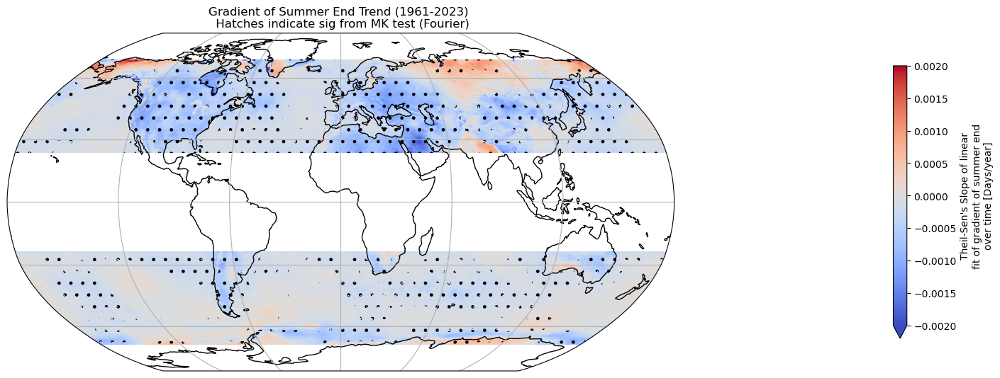

In [12]:

# Global summer end trend
fig = plt.figure(figsize=(15,8))

# assign axis and def projection to use
ax = plt.axes(projection=ccrs.Robinson(central_longitude=0))

# add coastlines and grid
ax.coastlines()
ax.gridlines()

results_ds.EndMKSlope.where((((results_ds.lat >= 23.5) & (results_ds.lat <= 70)) | 
                              ((results_ds.lat <= -23.5) & (results_ds.lat >= -70)))).plot(
    ax=ax,
    transform=ccrs.PlateCarree(), # assign map projection
    vmin=-0.002,
    vmax=0.002, 
    cmap="coolwarm",#"YlOrRd"#cmap="coolwarm"
    cbar_kwargs={'shrink': 0.5}
)

# points with MK test p-value under 0.05
mksig = results_ds.EndMKP.where((((results_ds.lat >= 23.5) & (results_ds.lat <= 70)) | 
                              ((results_ds.lat <= -23.5) & (results_ds.lat >= -70)))) <= 0.1

mksig.where(mksig.values).plot.contourf(hatches=".", transform=ccrs.PlateCarree(), 
                                        #colors='none', 
                                        cmap='none' )#cbar_kwargs={'shrink': 0.0})

# remove the colorbar from the contour
fig.axes[-1].remove()

plt.title("Gradient of Summer End Trend (1961-2023) \n Hatches indicate sig from MK test (Fourier)")#+" using 1961-1990 baseline")
#plt.savefig("./Plots/"+str(input_year)+"_SummerMeanHS_global.png")
plt.tight_layout()
plt.show()

### North America MK test only

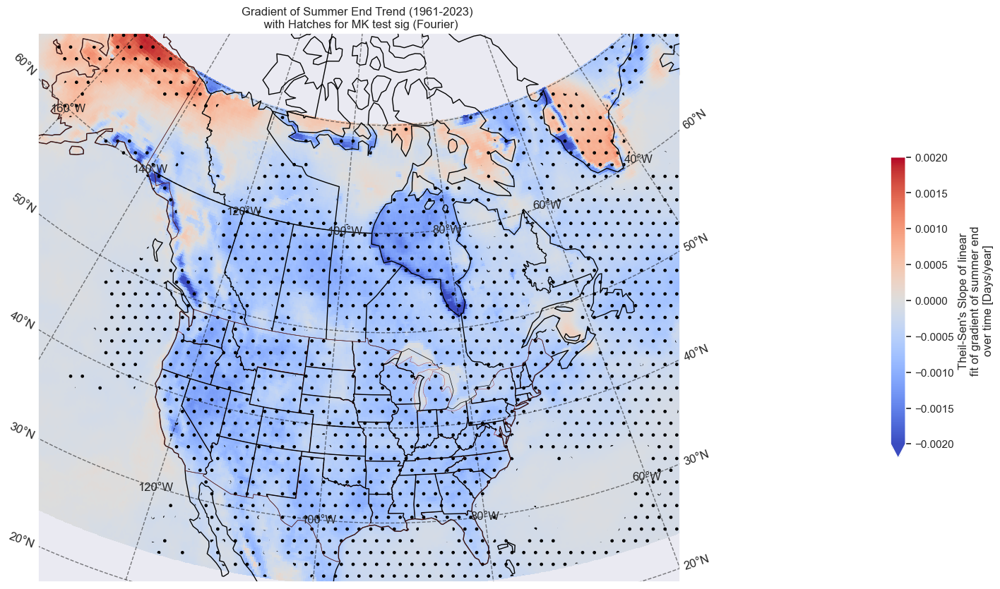

In [168]:

central_longitude = -(91 + 52 / 60)
central_latitude = 40

############
#Global map of summer end
fig = plt.figure(figsize=(15,9))

# assign axis and def projection to use
ax = plt.axes(projection=ccrs.LambertConformal(central_longitude=central_longitude, central_latitude=central_latitude))

# add coastlines and grid
ax.coastlines()
ax.gridlines(draw_labels=True, linewidth=1, color='black', alpha=0.5, linestyle='--')

dataplot = results_ds.EndMKSlope.where((((ds_full_end.lat >= 23.5) & (ds_full_end.lat <= 70)) | 
                              ((ds_full_end.lat <= -23.5) & (ds_full_end.lat >= -70)))).plot(
    ax=ax,
    transform=ccrs.PlateCarree(), # assign map projection
    vmin=-0.002,
    vmax=0.002,  
    cmap="coolwarm",
    cbar_kwargs={'shrink': 0.5}
    
)

# points with MK test p-value under 0.05
mksig = results_ds.EndMKP.where((((ds_full_end.lat >= 23.5) & (ds_full_end.lat <= 70)) | 
                              ((ds_full_end.lat <= -23.5) & (ds_full_end.lat >= -70)))) <= 0.1

mksig.where(mksig.values).plot.contourf(hatches=".", transform=ccrs.PlateCarree(), 
                                        #colors='none', 
                                        cmap='none' )#cbar_kwargs={'shrink': 0.0})

# remove the colorbar from the contour
fig.axes[-1].remove()



ax.set_extent((-130, -60, 20, 75))

provinces_50m = cfeature.NaturalEarthFeature('cultural',
                                             'admin_1_states_provinces_lines',
                                             '50m',
                                             facecolor='none')
ax.add_feature(cfeature.BORDERS, linewidth=0.5, edgecolor='black')
ax.add_feature(cfeature.STATES, linewidth=0.3, edgecolor='brown')
ax.add_feature(provinces_50m)
plt.title("Gradient of Summer End Trend (1961-2023) \n with Hatches for MK test sig (Fourier)")#+" using 1961-1990 baseline")
#plt.savefig("./Plots/"+str(input_year)+"_SummerMeanHS_global.png")
plt.tight_layout()
#plt.savefig("./Plots/"+str(input_year)+"_SummerLength_global.png")
plt.show()


#### Make NH and SH FDR maps for full period 1961-2023

#### FDR applied

In [13]:
np.sum(results_ds.EndMKP.values <= 0), np.sum(results_ds.EndMKP.values == 0), np.sum(results_ds.EndMKP.values == 1)

(np.int64(20211), np.int64(20211), np.int64(3267))

In [14]:
# have to replace the zeroes and ones with values between 0 and 1 for FDR
results_ds_p = results_ds.EndMKP
results_ds_p = results_ds_p.where(results_ds_p.values > 0)
results_ds_p = results_ds_p.fillna(1e-10) # fix zeroes
results_ds_p
#np.sum(results_ds_an_tmp.LengthMKP.values <= 0)
results_ds_p = results_ds_p.where(results_ds_p.values < 1.0)
results_ds_p
results_ds_p = results_ds_p.fillna(0.999) # fix ones
results_ds_p

<xarray.DataArray 'EndMKP' (lat: 721, lon: 1440)> Size: 8MB
array([[2.76908112e-03, 2.76908112e-03, 2.76908112e-03, ...,
        2.76908112e-03, 2.76908112e-03, 2.76908112e-03],
       [2.41295449e-03, 2.42532499e-03, 2.42532499e-03, ...,
        2.43791888e-03, 2.42532499e-03, 2.42532499e-03],
       [1.25974299e-03, 1.24524149e-03, 1.26436234e-03, ...,
        1.19488475e-03, 1.20556053e-03, 1.25974299e-03],
       ...,
       [1.00000000e-10, 1.00000000e-10, 1.00000000e-10, ...,
        1.00000000e-10, 1.00000000e-10, 1.00000000e-10],
       [1.00000000e-10, 1.00000000e-10, 1.00000000e-10, ...,
        1.00000000e-10, 1.00000000e-10, 1.00000000e-10],
       [1.00000000e-10, 1.00000000e-10, 1.00000000e-10, ...,
        1.00000000e-10, 1.00000000e-10, 1.00000000e-10]],
      shape=(721, 1440))
Coordinates:
  * lat      (lat) float64 6kB -90.0 -89.75 -89.5 -89.25 ... 89.5 89.75 90.0
  * lon      (lon) float64 12kB -180.0 -179.8 -179.5 ... 179.2 179.5 179.8
Attributes:
    long_name:  Hamed & Rao MK test for significance (p-value) of trend
    units:      None

In [15]:
# use func from scipi.stats
pval_fdr_cor = stats.false_discovery_control(results_ds_p.values)

# add as variable to dataset
results_ds_p['EndPvalFDR'] = (['lat','lon'], pval_fdr_cor)

results_ds_p

<xarray.DataArray 'EndMKP' (lat: 721, lon: 1440)> Size: 8MB
array([[2.76908112e-03, 2.76908112e-03, 2.76908112e-03, ...,
        2.76908112e-03, 2.76908112e-03, 2.76908112e-03],
       [2.41295449e-03, 2.42532499e-03, 2.42532499e-03, ...,
        2.43791888e-03, 2.42532499e-03, 2.42532499e-03],
       [1.25974299e-03, 1.24524149e-03, 1.26436234e-03, ...,
        1.19488475e-03, 1.20556053e-03, 1.25974299e-03],
       ...,
       [1.00000000e-10, 1.00000000e-10, 1.00000000e-10, ...,
        1.00000000e-10, 1.00000000e-10, 1.00000000e-10],
       [1.00000000e-10, 1.00000000e-10, 1.00000000e-10, ...,
        1.00000000e-10, 1.00000000e-10, 1.00000000e-10],
       [1.00000000e-10, 1.00000000e-10, 1.00000000e-10, ...,
        1.00000000e-10, 1.00000000e-10, 1.00000000e-10]],
      shape=(721, 1440))
Coordinates:
  * lat         (lat) float64 6kB -90.0 -89.75 -89.5 -89.25 ... 89.5 89.75 90.0
  * lon         (lon) float64 12kB -180.0 -179.8 -179.5 ... 179.2 179.5 179.8
    EndPvalFDR  (lat, lon) float64 8MB 0.01203 0.01188 ... 2.575e-09 2.884e-09
Attributes:
    long_name:  Hamed & Rao MK test for significance (p-value) of trend
    units:      None

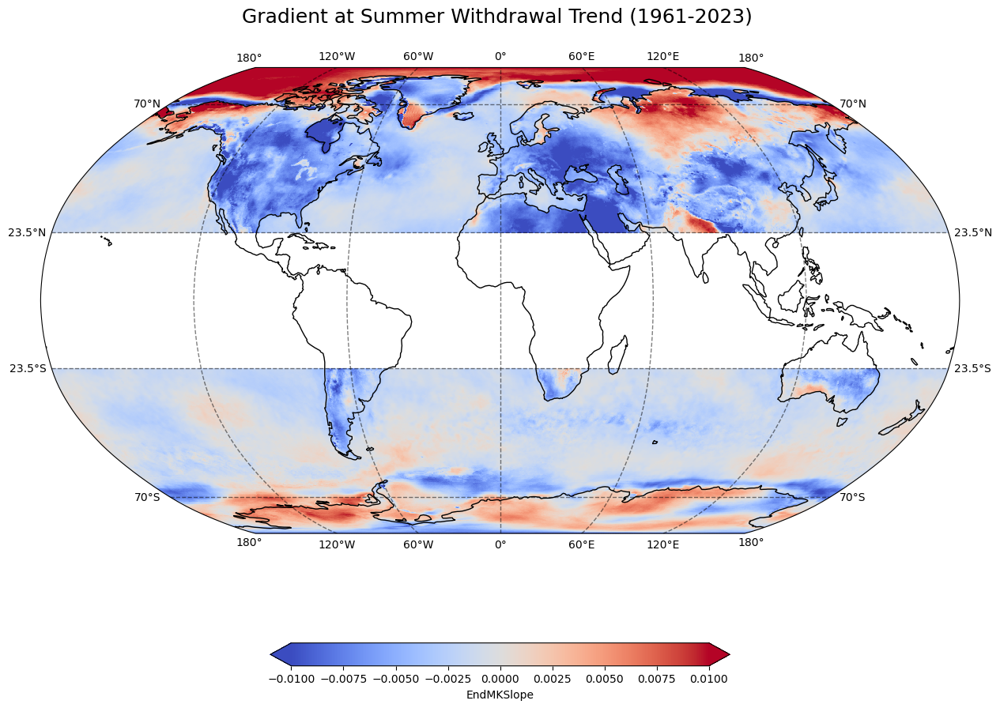

In [22]:

# Global summer length trend
fig = plt.figure(figsize=(15,12))

# assign axis and def projection to use
ax = plt.axes(projection=ccrs.Robinson(central_longitude=0))

# add coastlines and grid
ax.coastlines()
ax.gridlines(draw_labels=True,linewidth=1, color='black', alpha=0.5, ylocs=mticker.FixedLocator([-70, -23.5, 23.5, 70]), linestyle='--')

(results_ds.EndMKSlope.where(((results_ds.lat >= 23.5) | (results_ds.lat <= -23.5)))*10).plot(# & (results_ds_an_p.LengthPvalFDR < 0.1)).plot(
    ax=ax,
    transform=ccrs.PlateCarree(), # assign map projection
    vmin=-0.01,
    vmax=0.01, 
    cmap="coolwarm",#"YlOrRd"#cmap="coolwarm"
    cbar_kwargs={'shrink': 0.5, 'location':'bottom'}
)

plt.title("Gradient at Summer Withdrawal Trend (1961-2023) \n ", fontsize=18)#+" using 1961-1990 baseline")
#plt.savefig("./Plots/"+str(input_year)+"_SummerMeanHS_global.png")
plt.show()

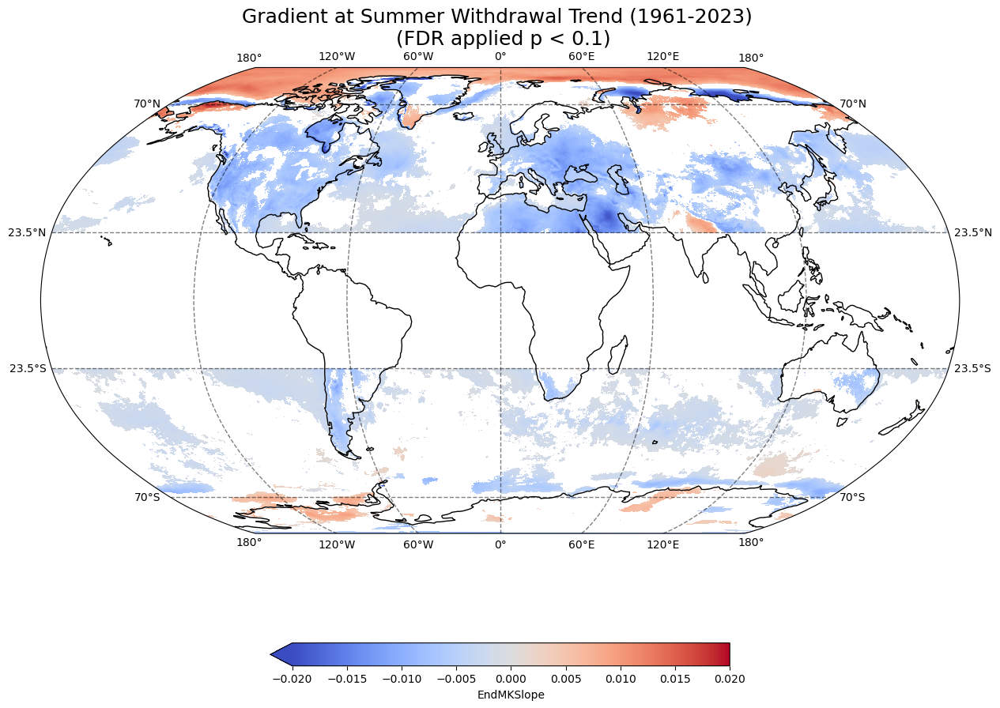

In [58]:

# Global summer length trend
fig = plt.figure(figsize=(15,12))

# assign axis and def projection to use
ax = plt.axes(projection=ccrs.Robinson(central_longitude=0))

# add coastlines and grid
ax.coastlines()
ax.gridlines(draw_labels=True,linewidth=1, color='black', alpha=0.5, ylocs=mticker.FixedLocator([-70, -23.5, 23.5, 70]), linestyle='--')

(results_ds.EndMKSlope.where(((results_ds.lat >= 23.5) | (results_ds.lat <= -23.5)) & (results_ds_p.EndPvalFDR < 0.1))*10).plot(# & (results_ds_an_p.LengthPvalFDR < 0.1)).plot(
    ax=ax,
    transform=ccrs.PlateCarree(), # assign map projection
    vmin=-0.01,
    vmax=0.01, 
    cmap="coolwarm",#"YlOrRd"#cmap="coolwarm"
    cbar_kwargs={'shrink': 0.5, 'location':'bottom'}
)

plt.title("Gradient at Summer Withdrawal Trend (1961-2023) \n (FDR applied p < 0.1)", fontsize=18)#+" using 1961-1990 baseline")
#plt.savefig("./Plots/"+str(input_year)+"_SummerMeanHS_global.png")
plt.show()

#### relabel, adjust units, and make better plot for publication?

In [16]:
# make a copy to keep original intact
res_plot = results_ds.copy(deep=True)

# update to be change in days per decade
res_plot['EndMKSlope'] = res_plot.EndMKSlope * 10

# update attributes
res_plot['EndMKSlope'].attrs["long_name"] = "Change in Gradient at Summer Withdrawal \n"
res_plot['EndMKSlope'].attrs["units"] = "$^{\circ}$C / day / decade"

res_plot, results_ds

(<xarray.Dataset> Size: 25MB
 Dimensions:     (lat: 721, lon: 1440)
 Coordinates:
   * lat         (lat) float64 6kB -90.0 -89.75 -89.5 -89.25 ... 89.5 89.75 90.0
   * lon         (lon) float64 12kB -180.0 -179.8 -179.5 ... 179.2 179.5 179.8
 Data variables:
     EndMKSlope  (lat, lon) float64 8MB -0.008538 -0.008538 ... 0.01141 0.01141
     EndMKH      (lat, lon) float64 8MB ...
     EndMKP      (lat, lon) float64 8MB 0.002769 0.002769 0.002769 ... 0.0 0.0,
 <xarray.Dataset> Size: 25MB
 Dimensions:     (lat: 721, lon: 1440)
 Coordinates:
   * lat         (lat) float64 6kB -90.0 -89.75 -89.5 -89.25 ... 89.5 89.75 90.0
   * lon         (lon) float64 12kB -180.0 -179.8 -179.5 ... 179.2 179.5 179.8
 Data variables:
     EndMKSlope  (lat, lon) float64 8MB ...
     EndMKH      (lat, lon) float64 8MB ...
     EndMKP      (lat, lon) float64 8MB 0.002769 0.002769 0.002769 ... 0.0 0.0)

#### NH only map

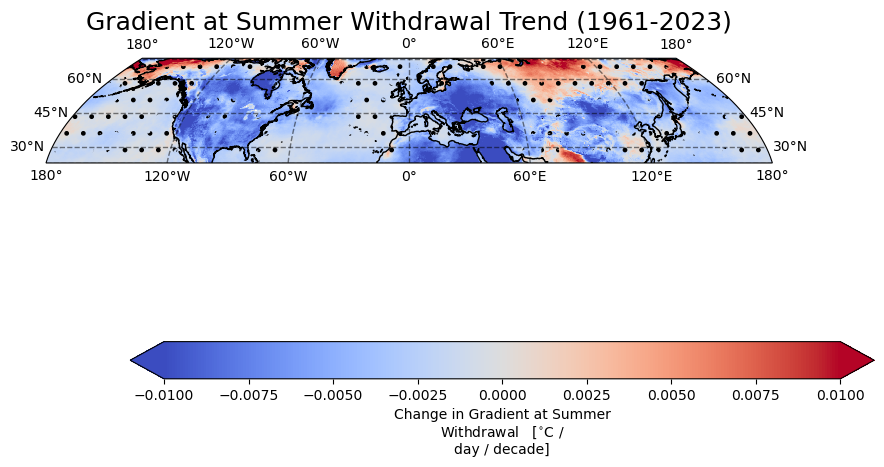

In [25]:
nh_min = 23.5
nh_max = 70

# Global summer length trend
fig = plt.figure(figsize=(12,6))

# assign axis and def projection to use
ax = plt.axes(projection=ccrs.Robinson(central_longitude=0))

# add coastlines and grid
ax.coastlines()
ax.gridlines(draw_labels=True,linewidth=1, color='black', alpha=0.5,  ylocs=mticker.FixedLocator([ 23.5,30,45,60, 70]), linestyle='--')

# filtering out great lakes due to ERA5 issues
mask = res_plot.EndMKSlope.sel(lat=slice(nh_min, nh_max)).where((res_plot.lat > 41) & (res_plot.lat < 49) & (res_plot.lon < -75) & (res_plot.lon > -92)) > 0

res_plot.EndMKSlope.sel(lat=slice(nh_min, nh_max)).where(mask == False).plot(
    ax=ax,
    transform=ccrs.PlateCarree(), # assign map projection
    vmin=-0.01,
    vmax=0.01, 
    cmap="coolwarm",#"YlOrRd"#cmap="coolwarm"
    cbar_kwargs={'shrink': 0.8, 'location':'bottom'}
)

# points with MK test p-value OVER 0.1
mkNOTsig = res_plot.EndMKP.sel(lat=slice(nh_min, nh_max)) > 0.1

mkNOTsig.where(mkNOTsig.values).plot.contourf(hatches=".", transform=ccrs.PlateCarree(), cmap='none' )#cbar_kwargs={'shrink': 0.0})

# remove the colorbar from the contour
fig.axes[-1].remove()


plt.title("Gradient at Summer Withdrawal Trend (1961-2023)", fontsize=18)#+" using 1961-1990 baseline")
plt.savefig("./Plots/1961-2023_SummerWithdrawal_Grad_Trends_NH_FDR_hatches.png",bbox_inches='tight')
plt.savefig("./Plots/1961-2023_SummerWithdrawal_Grad_Trends_NH_FDR_hatches.pdf",bbox_inches='tight')
plt.show()

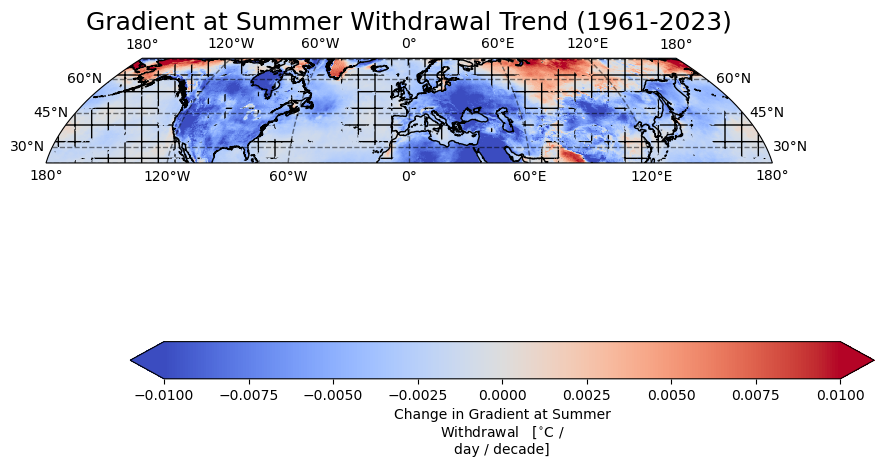

In [17]:
nh_min = 23.5
nh_max = 70

# Global summer length trend
fig = plt.figure(figsize=(12,6))

# assign axis and def projection to use
ax = plt.axes(projection=ccrs.Robinson(central_longitude=0))

# add coastlines and grid
ax.coastlines()
ax.gridlines(draw_labels=True,linewidth=1, color='black', alpha=0.5,  ylocs=mticker.FixedLocator([ 23.5,30,45,60, 70]), linestyle='--')

# filtering out great lakes due to ERA5 issues
mask = res_plot.EndMKSlope.sel(lat=slice(nh_min, nh_max)).where((res_plot.lat > 41) & (res_plot.lat < 49) & (res_plot.lon < -75) & (res_plot.lon > -92)) > 0

res_plot.EndMKSlope.sel(lat=slice(nh_min, nh_max)).where(mask == False).plot(
    ax=ax,
    transform=ccrs.PlateCarree(), # assign map projection
    vmin=-0.01,
    vmax=0.01, 
    cmap="coolwarm",#"YlOrRd"#cmap="coolwarm"
    cbar_kwargs={'shrink': 0.8, 'location':'bottom'}
)

# points with MK test p-value OVER 0.1
mkNOTsig = res_plot.EndMKP.sel(lat=slice(nh_min, nh_max)) > 0.1

mkNOTsig.where(mkNOTsig.values).plot.contourf(hatches="+", transform=ccrs.PlateCarree(), cmap='none' )#cbar_kwargs={'shrink': 0.0})

# remove the colorbar from the contour
fig.axes[-1].remove()


plt.title("Gradient at Summer Withdrawal Trend (1961-2023)", fontsize=18)#+" using 1961-1990 baseline")
plt.savefig("./Plots/1961-2023_SummerWithdrawal_Grad_Trends_NH_FDR_notsig+.png",bbox_inches='tight')
plt.savefig("./Plots/1961-2023_SummerWithdrawal_Grad_Trends_NH_FDR_notsig+.pdf",bbox_inches='tight')
plt.show()

#### NH only map - unfiltered


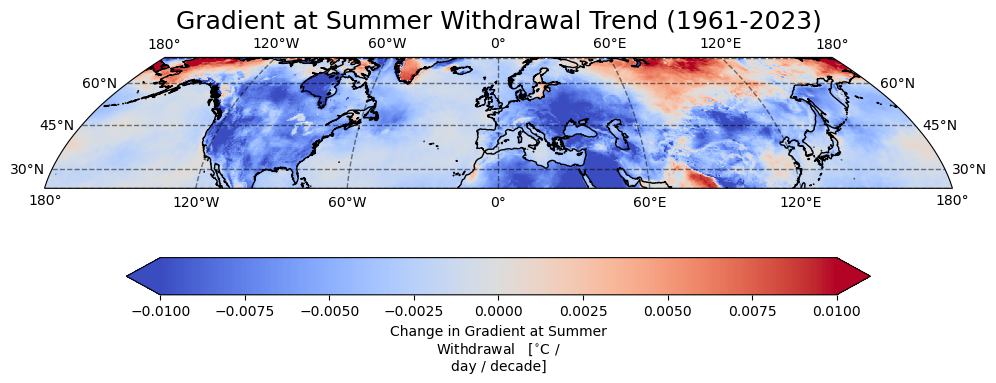

In [18]:
nh_min = 23.5
nh_max = 70

# Global summer length trend
fig = plt.figure(figsize=(12,6))

# assign axis and def projection to use
ax = plt.axes(projection=ccrs.Robinson(central_longitude=0))

# add coastlines and grid
ax.coastlines()
ax.gridlines(draw_labels=True,linewidth=1, color='black', alpha=0.5,  ylocs=mticker.FixedLocator([ 23.5,30,45,60, 70]), linestyle='--')

# filtering out great lakes due to ERA5 issues
mask = res_plot.EndMKSlope.sel(lat=slice(nh_min, nh_max)).where((res_plot.lat > 41) & (res_plot.lat < 49) & (res_plot.lon < -75) & (res_plot.lon > -92)) >= 0

res_plot.EndMKSlope.sel(lat=slice(nh_min, nh_max)).where(mask == False).plot(
    ax=ax,
    transform=ccrs.PlateCarree(), # assign map projection
    vmin=-0.01,
    vmax=0.01, 
    cmap="coolwarm",#"YlOrRd"#cmap="coolwarm"
    cbar_kwargs={'shrink': 0.8, 'location':'bottom'}
)

plt.title("Gradient at Summer Withdrawal Trend (1961-2023)", fontsize=18)#+" using 1961-1990 baseline")
plt.savefig("./Plots/1961-2023_SummerWithdrawal_Grad_Trends_NH_unfiltered.png",bbox_inches='tight')
plt.savefig("./Plots/1961-2023_SummerWithdrawal_Grad_Trends_NH_unfiltered.pdf",bbox_inches='tight')
plt.show()

#### SH only map

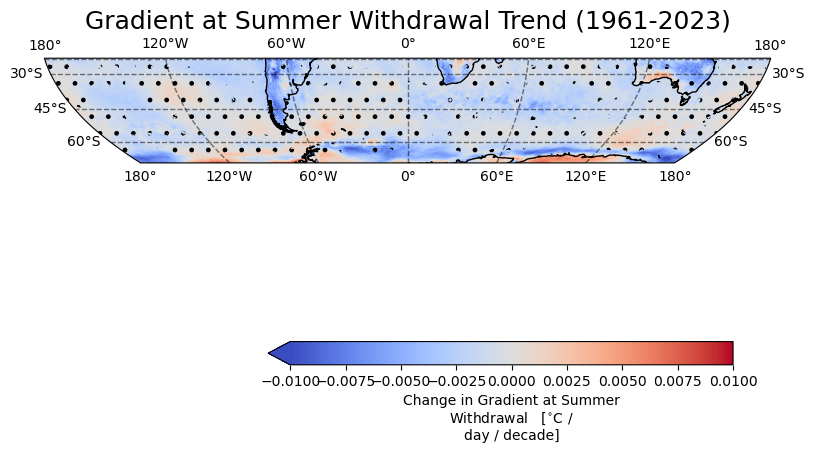

In [26]:
sh_min = -70
sh_max = -23.5

# Global summer length trend
fig = plt.figure(figsize=(12,6))

# assign axis and def projection to use
ax = plt.axes(projection=ccrs.Robinson(central_longitude=0))

# add coastlines and grid
ax.coastlines()
ax.gridlines(draw_labels=True,linewidth=1, color='black', alpha=0.5, ylocs=mticker.FixedLocator([ -70,-60,-45,-30, -23.5]), linestyle='--')

res_plot.EndMKSlope.sel(lat=slice(sh_min, sh_max)).plot(
    ax=ax,
    transform=ccrs.PlateCarree(), # assign map projection
    vmin=-0.01,
    vmax=0.01, 
    cmap="coolwarm",#"YlOrRd"#cmap="coolwarm"
    cbar_kwargs={'shrink': 0.5, 'location':'bottom'}
)

# points with MK test p-value OVER 0.1
mkNOTsig = res_plot.EndMKP.sel(lat=slice(sh_min, sh_max)) > 0.1

mkNOTsig.where(mkNOTsig.values).plot.contourf(hatches=".", transform=ccrs.PlateCarree(), cmap='none' )#cbar_kwargs={'shrink': 0.0})

# remove the colorbar from the contour
fig.axes[-1].remove()

plt.title("Gradient at Summer Withdrawal Trend (1961-2023)", fontsize=18)#+" using 1961-1990 baseline")
plt.savefig("./Plots/1961-2023_SummerWithdrawal_Grad_Trends_SH_FDR_hatches.png",bbox_inches='tight')
plt.savefig("./Plots/1961-2023_SummerWithdrawal_Grad_Trends_SH_FDR_hatches.pdf",bbox_inches='tight')

plt.show()

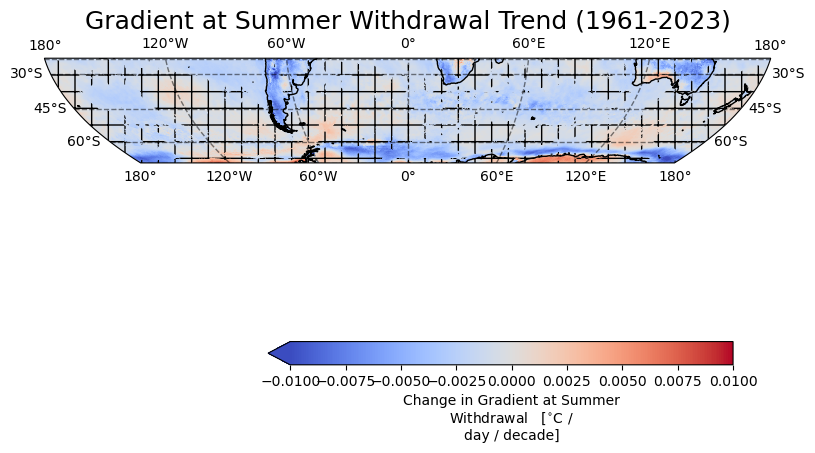

In [19]:
sh_min = -70
sh_max = -23.5

# Global summer length trend
fig = plt.figure(figsize=(12,6))

# assign axis and def projection to use
ax = plt.axes(projection=ccrs.Robinson(central_longitude=0))

# add coastlines and grid
ax.coastlines()
ax.gridlines(draw_labels=True,linewidth=1, color='black', alpha=0.5, ylocs=mticker.FixedLocator([ -70,-60,-45,-30, -23.5]), linestyle='--')

res_plot.EndMKSlope.sel(lat=slice(sh_min, sh_max)).plot(
    ax=ax,
    transform=ccrs.PlateCarree(), # assign map projection
    vmin=-0.01,
    vmax=0.01, 
    cmap="coolwarm",#"YlOrRd"#cmap="coolwarm"
    cbar_kwargs={'shrink': 0.5, 'location':'bottom'}
)

# points with MK test p-value OVER 0.1
mkNOTsig = res_plot.EndMKP.sel(lat=slice(sh_min, sh_max)) > 0.1

mkNOTsig.where(mkNOTsig.values).plot.contourf(hatches="+", transform=ccrs.PlateCarree(), cmap='none' )#cbar_kwargs={'shrink': 0.0})

# remove the colorbar from the contour
fig.axes[-1].remove()

plt.title("Gradient at Summer Withdrawal Trend (1961-2023)", fontsize=18)#+" using 1961-1990 baseline")
plt.savefig("./Plots/1961-2023_SummerWithdrawal_Grad_Trends_SH_FDR_notsig+.png",bbox_inches='tight')
plt.savefig("./Plots/1961-2023_SummerWithdrawal_Grad_Trends_SH_FDR_notsig+.pdf",bbox_inches='tight')

plt.show()

#### SH only map - unfiltered

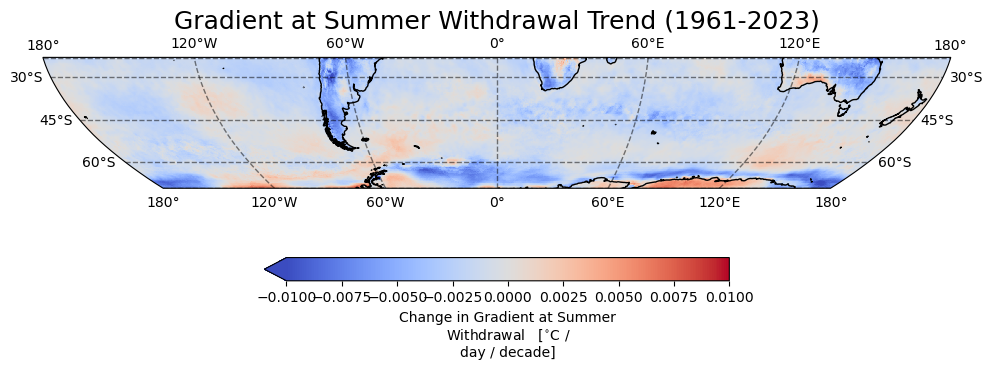

In [20]:
sh_min = -70
sh_max = -23.5

# Global summer length trend
fig = plt.figure(figsize=(12,6))

# assign axis and def projection to use
ax = plt.axes(projection=ccrs.Robinson(central_longitude=0))

# add coastlines and grid
ax.coastlines()
ax.gridlines(draw_labels=True,linewidth=1, color='black', alpha=0.5, ylocs=mticker.FixedLocator([ -70,-60,-45,-30, -23.5]), linestyle='--')

res_plot.EndMKSlope.sel(lat=slice(sh_min, sh_max)).plot(
    ax=ax,
    transform=ccrs.PlateCarree(), # assign map projection
    vmin=-0.01,
    vmax=0.01, 
    cmap="coolwarm",#"YlOrRd"#cmap="coolwarm"
    cbar_kwargs={'shrink': 0.5, 'location':'bottom'}
)

plt.title("Gradient at Summer Withdrawal Trend (1961-2023)", fontsize=18)#+" using 1961-1990 baseline")
plt.savefig("./Plots/1961-2023_SummerWithdrawal_Grad_Trends_SH_unfiltered.png",bbox_inches='tight')
plt.savefig("./Plots/1961-2023_SummerWithdrawal_Grad_Trends_SH_unfiltered.pdf",bbox_inches='tight')
plt.show()

### *** Below has not been updated

### 1990-2023: Plot with hatching from MK test

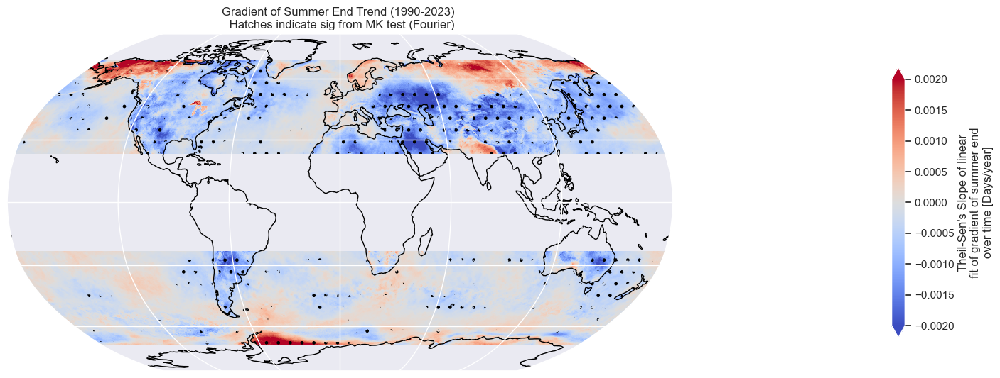

In [169]:

# Global summer end trend
fig = plt.figure(figsize=(15,8))

# assign axis and def projection to use
ax = plt.axes(projection=ccrs.Robinson(central_longitude=0))

# add coastlines and grid
ax.coastlines()
ax.gridlines()

results_ds_an.EndMKSlope.where((((ds_end_analysis.lat >= 23.5) & (ds_end_analysis.lat <= 70)) | 
                              ((ds_end_analysis.lat <= -23.5) & (ds_end_analysis.lat >= -70)))).plot(
    ax=ax,
    transform=ccrs.PlateCarree(), # assign map projection
    vmin=-0.002,
    vmax=0.002, 
    cmap="coolwarm",#"YlOrRd"#cmap="coolwarm"
    cbar_kwargs={'shrink': 0.5}
)

# points with MK test p-value under 0.05
mksig = results_ds_an.EndMKP.where((((ds_end_analysis.lat >= 23.5) & (ds_end_analysis.lat <= 70)) | 
                              ((ds_end_analysis.lat <= -23.5) & (ds_end_analysis.lat >= -70)))) <= 0.1

mksig.where(mksig.values).plot.contourf(hatches=".", transform=ccrs.PlateCarree(), 
                                        #colors='none', 
                                        cmap='none' )#cbar_kwargs={'shrink': 0.0})

# remove the colorbar from the contour
fig.axes[-1].remove()

plt.title("Gradient of Summer End Trend (1990-2023) \n Hatches indicate sig from MK test (Fourier)")#+" using 1961-1990 baseline")
#plt.savefig("./Plots/"+str(input_year)+"_SummerMeanHS_global.png")
plt.tight_layout()
plt.show()

### North America MK test only

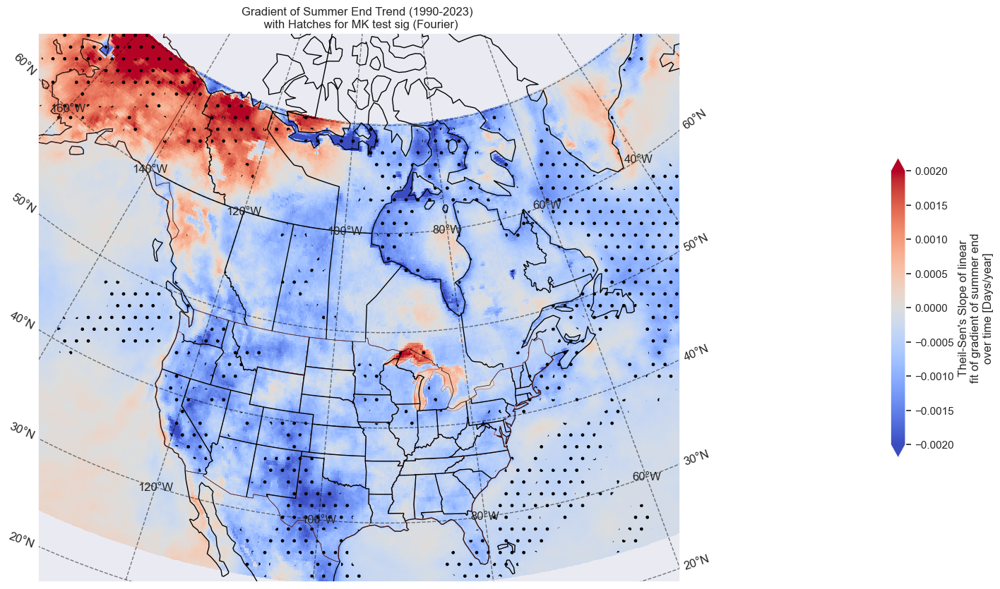

In [170]:

central_longitude = -(91 + 52 / 60)
central_latitude = 40

############
#Global map of summer end
fig = plt.figure(figsize=(15,9))

# assign axis and def projection to use
ax = plt.axes(projection=ccrs.LambertConformal(central_longitude=central_longitude, central_latitude=central_latitude))

# add coastlines and grid
ax.coastlines()
ax.gridlines(draw_labels=True, linewidth=1, color='black', alpha=0.5, linestyle='--')

dataplot = results_ds_an.EndMKSlope.where((((ds_end_analysis.lat >= 23.5) & (ds_end_analysis.lat <= 70)) | 
                              ((ds_end_analysis.lat <= -23.5) & (ds_end_analysis.lat >= -70)))).plot(
    ax=ax,
    transform=ccrs.PlateCarree(), # assign map projection
    vmin=-0.002,
    vmax=0.002, 
    cmap="coolwarm",
    cbar_kwargs={'shrink': 0.5}
    
)

# points with MK test p-value under 0.05
mksig = results_ds_an.EndMKP.where((((ds_end_analysis.lat >= 23.5) & (ds_end_analysis.lat <= 70)) | 
                              ((ds_end_analysis.lat <= -23.5) & (ds_end_analysis.lat >= -70)))) <= 0.1

mksig.where(mksig.values).plot.contourf(hatches=".", transform=ccrs.PlateCarree(), 
                                        #colors='none', 
                                        cmap='none' )#cbar_kwargs={'shrink': 0.0})

# remove the colorbar from the contour
fig.axes[-1].remove()



ax.set_extent((-130, -60, 20, 75))

provinces_50m = cfeature.NaturalEarthFeature('cultural',
                                             'admin_1_states_provinces_lines',
                                             '50m',
                                             facecolor='none')
ax.add_feature(cfeature.BORDERS, linewidth=0.5, edgecolor='black')
ax.add_feature(cfeature.STATES, linewidth=0.3, edgecolor='brown')
ax.add_feature(provinces_50m, edgecolor='black')
plt.title("Gradient of Summer End Trend (1990-2023) \n with Hatches for MK test sig (Fourier)")#+" using 1961-1990 baseline")
#plt.savefig("./Plots/"+str(input_year)+"_SummerMeanHS_global.png")
plt.tight_layout()
#plt.savefig("./Plots/"+str(input_year)+"_SummerLength_global.png")
plt.show()


### Europe MK test

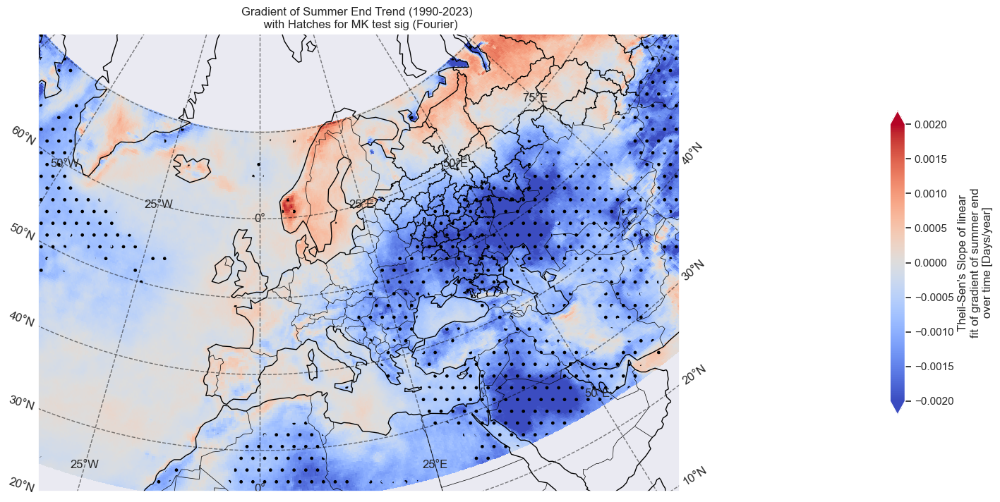

In [171]:
central_longitude = 0
central_latitude = 40

############
#Global map of summer length
fig = plt.figure(figsize=(15,9))

# assign axis and def projection to use
ax = plt.axes(projection=ccrs.LambertConformal(central_longitude=central_longitude, central_latitude=central_latitude))

# add coastlines and grid
ax.coastlines()
ax.gridlines(draw_labels=True, linewidth=1, color='black', alpha=0.5, linestyle='--')

dataplot = results_ds_an.EndMKSlope.where((((ds_end_analysis.lat >= 23.5) & (ds_end_analysis.lat <= 70)) | 
                              ((ds_end_analysis.lat <= -23.5) & (ds_end_analysis.lat >= -70)))).plot(
    ax=ax,
    transform=ccrs.PlateCarree(), # assign map projection
    vmin=-0.002,
    vmax=0.002, 
    cmap="coolwarm",
    cbar_kwargs={'shrink': 0.5}
    
)

# points with MK test p-value under 0.05
mksig = results_ds_an.EndMKP.where((((ds_end_analysis.lat >= 23.5) & (ds_end_analysis.lat <= 70)) | 
                              ((ds_end_analysis.lat <= -23.5) & (ds_end_analysis.lat >= -70)))) <= 0.1

mksig.where(mksig.values).plot.contourf(hatches=".", transform=ccrs.PlateCarree(), 
                                        #colors='black', 
                                        cmap='none' )#cbar_kwargs={'shrink': 0.0})

# remove the colorbar from the contour
fig.axes[-1].remove()

ax.set_extent((-30, 60, 20, 75))

provinces_50m = cfeature.NaturalEarthFeature('cultural',
                                             'admin_1_states_provinces_lines',
                                             '50m',
                                             facecolor='none')
ax.add_feature(cfeature.BORDERS, linewidth=0.5, edgecolor='black')
ax.add_feature(cfeature.STATES, linewidth=0.3, edgecolor='brown')
ax.add_feature(provinces_50m, edgecolor='black')

plt.title("Gradient of Summer End Trend (1990-2023) \n with Hatches for MK test sig (Fourier)")#+" using 1961-1990 baseline")
#plt.savefig("./Plots/"+str(input_year)+"_SummerMeanHS_global.png")
plt.tight_layout()
plt.show()




### relabel, adjust units, and make better plot for publication?

In [64]:
# make a copy to keep original intact
res_plot = results_ds_an.copy(deep=True)

# update to be change in days per decade
res_plot['EndMKSlope'] = res_plot.EndMKSlope * 10

# update attributes
res_plot['EndMKSlope'].attrs["long_name"] = "Change in Gradient of Summer End \n"
res_plot['EndMKSlope'].attrs["units"] = "K / Day / 10 yrs"

res_plot, results_ds_an

(<xarray.Dataset> Size: 25MB
 Dimensions:     (lat: 721, lon: 1440)
 Coordinates:
   * lat         (lat) float64 6kB -90.0 -89.75 -89.5 -89.25 ... 89.5 89.75 90.0
   * lon         (lon) float64 12kB -180.0 -179.8 -179.5 ... 179.2 179.5 179.8
 Data variables:
     EndMKSlope  (lat, lon) float64 8MB -0.001097 -0.001097 ... 0.01456 0.01456
     EndMKH      (lat, lon) float64 8MB ...
     EndMKP      (lat, lon) float64 8MB ...,
 <xarray.Dataset> Size: 25MB
 Dimensions:     (lat: 721, lon: 1440)
 Coordinates:
   * lat         (lat) float64 6kB -90.0 -89.75 -89.5 -89.25 ... 89.5 89.75 90.0
   * lon         (lon) float64 12kB -180.0 -179.8 -179.5 ... 179.2 179.5 179.8
 Data variables:
     EndMKSlope  (lat, lon) float64 8MB ...
     EndMKH      (lat, lon) float64 8MB ...
     EndMKP      (lat, lon) float64 8MB ...)

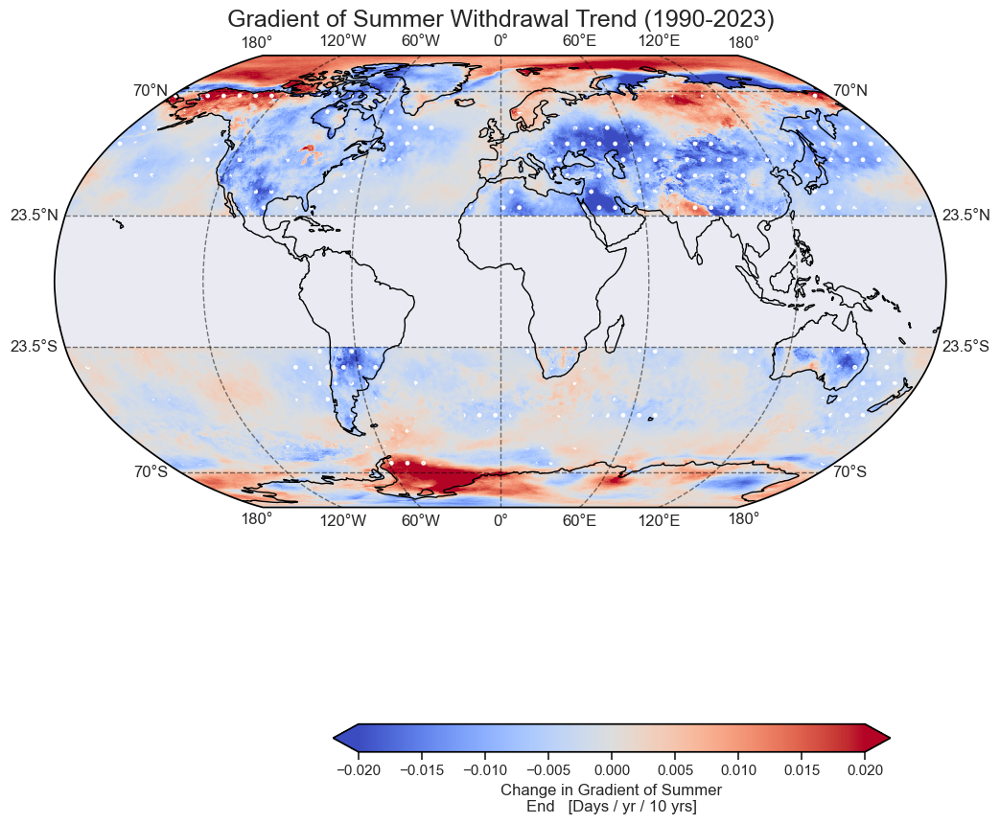

In [65]:

# Global summer length trend
fig = plt.figure(figsize=(15,12))

# assign axis and def projection to use
ax = plt.axes(projection=ccrs.Robinson(central_longitude=0))

# add coastlines and grid
ax.coastlines()
ax.gridlines(draw_labels=True,linewidth=1, color='black', alpha=0.5, ylocs=mticker.FixedLocator([-70, -23.5, 23.5, 70]), linestyle='--')

res_plot.EndMKSlope.where((res_plot.lat >= 23.5) | (res_plot.lat <= -23.5)).plot(
    ax=ax,
    transform=ccrs.PlateCarree(), # assign map projection
    vmin=-0.02,
    vmax=0.02, 
    cmap="coolwarm",#"YlOrRd"#cmap="coolwarm"
    cbar_kwargs={'shrink': 0.5, 'location':'bottom'}
)

# points with MK test p-value under 0.05
mksig = res_plot.EndMKP.where((((res_plot.lat >= 23.5) & (res_plot.lat <= 70)) | 
                              ((res_plot.lat <= -23.5) & (res_plot.lat >= -70)))) <= 0.1

mksig.where(mksig.values).plot.contourf(hatches="..", transform=ccrs.PlateCarree(), 
                                        #colors='none', 
                                        cmap='none' )#cbar_kwargs={'shrink': 0.0})

# remove the colorbar from the contour
fig.axes[-1].remove()

plt.title("Gradient of Summer Withdrawal Trend (1990-2023)", fontsize=18)#+" using 1961-1990 baseline")
#plt.savefig("./Plots/"+str(input_year)+"_SummerMeanHS_global.png")
plt.show()

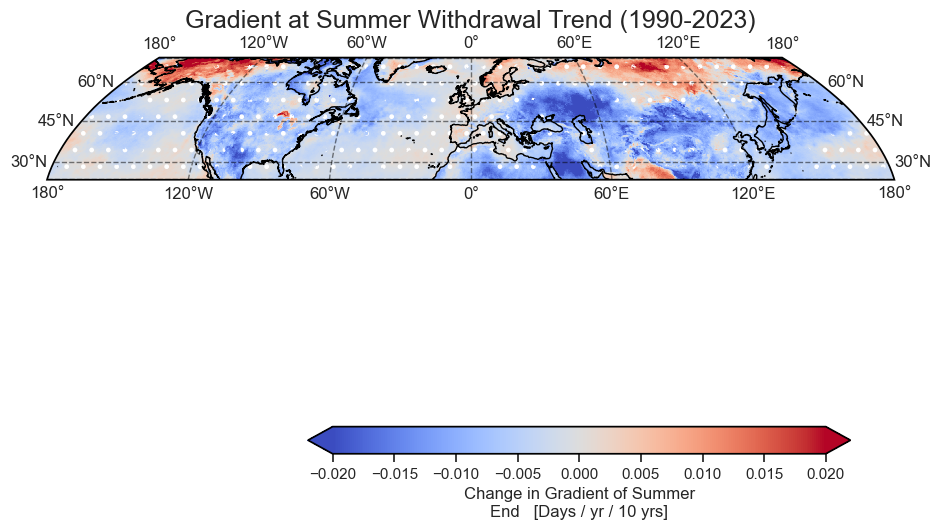

In [68]:
#sns.set_theme(style="darkgrid", rc={"patch.edgecolor": "black"})
#sns.set_theme()
nh_min = 23.5
nh_max = 70


# Global summer length trend
fig = plt.figure(figsize=(14,8))

# assign axis and def projection to use
ax = plt.axes(projection=ccrs.Robinson(central_longitude=0))

# add coastlines and grid
ax.coastlines()
ax.gridlines(draw_labels=True,linewidth=1, color='black', alpha=0.5,  ylocs=mticker.FixedLocator([ 23.5,30,45,60, 70]), linestyle='--')

res_plot.EndMKSlope.sel(lat=slice(nh_min, nh_max)).plot(
    ax=ax,
    transform=ccrs.PlateCarree(), # assign map projection
    vmin=-0.02,
    vmax=0.02, 
    cmap="coolwarm",#"YlOrRd"#cmap="coolwarm"
    cbar_kwargs={'shrink': 0.5, 'location':'bottom'}
)

# points with MK test p-value OVER 0.1
mkNOTsig = res_plot.EndMKP.sel(lat=slice(nh_min, nh_max)) > 0.1

mkNOTsig.where(mkNOTsig.values).plot.contourf(hatches=".", transform=ccrs.PlateCarree(), cmap='none' )#cbar_kwargs={'shrink': 0.0})

# remove the colorbar from the contour
fig.axes[-1].remove()

plt.title("Gradient at Summer Withdrawal Trend (1990-2023)", fontsize=18)#+" using 1961-1990 baseline")
plt.savefig("./Plots/1990-2023_SummerWithdrawal_Grad_Trends_NH.png")
plt.show()


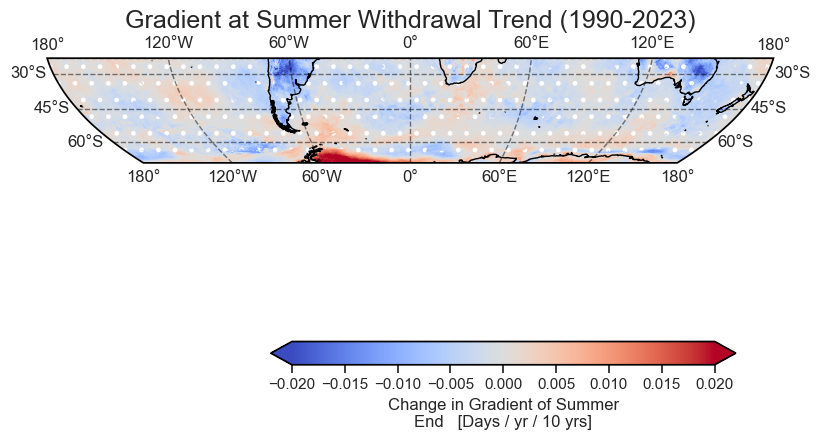

In [69]:
sh_min = -70
sh_max = -23.5

# Global summer length trend
fig = plt.figure(figsize=(12,6))

# assign axis and def projection to use
ax = plt.axes(projection=ccrs.Robinson(central_longitude=0))

# add coastlines and grid
ax.coastlines()
ax.gridlines(draw_labels=True,linewidth=1, color='black', alpha=0.5, ylocs=mticker.FixedLocator([ -70,-60,-45,-30, -23.5]), linestyle='--')

res_plot.EndMKSlope.sel(lat=slice(sh_min, sh_max)).plot(
    ax=ax,
    transform=ccrs.PlateCarree(), # assign map projection
    vmin=-0.02,
    vmax=0.02, 
    cmap="coolwarm",#"YlOrRd"#cmap="coolwarm"
    cbar_kwargs={'shrink': 0.5, 'location':'bottom'}
)

# points with MK test p-value OVER 0.1
mkNOTsig = res_plot.EndMKP.sel(lat=slice(sh_min, sh_max)) > 0.1

mkNOTsig.where(mkNOTsig.values).plot.contourf(hatches=".", transform=ccrs.PlateCarree(), cmap='none' )#cbar_kwargs={'shrink': 0.0})

# remove the colorbar from the contour
fig.axes[-1].remove()

plt.title("Gradient at Summer Withdrawal Trend (1990-2023)", fontsize=18)#+" using 1961-1990 baseline")
plt.savefig("./Plots/1990-2023_SummerWithdrawal_Grad_Trends_SH.png")
plt.show()

## Mid latitude Mean Gradients of Start and End

## Both Gradients plotted: Land (that is not Coastal), Coastal, Ocean

In [3]:
# plot properties so I can more easily tweak them
s = 18
lw = 4
alpha = 0.6
fs = 20

sns.set_theme(style="darkgrid")

In [4]:
# find weights (this is a regular grid so we can use cos(latitude))
weights = np.cos(np.deg2rad(ds_full.lat))
weights.name = "weights"

In [5]:
%%time

# takes 36 sec

# latitude & longitude ranges for NH and SH midlatitudes so they will be easy to adjust
nh_min = 23.5
nh_max = 70
sh_min = -23.5
sh_max = -70

# datasets of weighted averages for the midlatitudes

nh_ocean_full = ds_full.where((ds_full.lsm <= 0.5) & 
                              ((ds_full.lat >= nh_min) & (ds_full.lat <= nh_max))).weighted(weights).mean(dim=['lat','lon'])


sh_ocean_full = ds_full.where((ds_full.lsm <= 0.5) &  
                              ((ds_full.lat >= sh_max) & (ds_full.lat <= sh_min))).weighted(weights).mean(dim=['lat','lon'])


nh_ocean_an = ds_full.sel(time=slice('1990','2023')).where((ds_full.lsm <= 0.5) & 
                                                           ((ds_full.lat >= nh_min) & (ds_full.lat <= nh_max))).weighted(weights).mean(dim=['lat','lon'])


sh_ocean_an = ds_full.sel(time=slice('1990','2023')).where((ds_full.lsm <= 0.5) & 
                                                           ((ds_full.lat >= sh_max) & (ds_full.lat <= sh_min))).weighted(weights).mean(dim=['lat','lon'])

nh_land_full = ds_full.where((ds_full.lsm > 0.5) & (ds_full.Coastal == False) &
                             ((ds_full.lat >= nh_min) & (ds_full.lat <= nh_max))).weighted(weights).mean(dim=['lat','lon'])

nh_coast_full = ds_full.where((ds_full.Coastal) & 
                              ((ds_full.lat >= nh_min) & (ds_full.lat <= nh_max))).weighted(weights).mean(dim=['lat','lon'])

sh_land_full = ds_full.where((ds_full.lsm > 0.5) & (ds_full.Coastal == False) &
                             ((ds_full.lat >= sh_max) & (ds_full.lat <= sh_min))).weighted(weights).mean(dim=['lat','lon'])

sh_coast_full = ds_full.where((ds_full.Coastal) &  
                              ((ds_full.lat >= sh_max) & (ds_full.lat <= sh_min))).weighted(weights).mean(dim=['lat','lon'])

nh_land_an = ds_full.sel(time=slice('1990','2023')).where((ds_full.lsm > 0.5) & (ds_full.Coastal == False) &
                                                          ((ds_full.lat >= nh_min) & (ds_full.lat <= nh_max))).weighted(weights).mean(dim=['lat','lon'])

nh_coast_an = ds_full.sel(time=slice('1990','2023')).where((ds_full.Coastal) & 
                                                           ((ds_full.lat >= nh_min) & (ds_full.lat <= nh_max))).weighted(weights).mean(dim=['lat','lon'])

sh_land_an = ds_full.sel(time=slice('1990','2023')).where((ds_full.lsm > 0.5) & (ds_full.Coastal == False) &
                                                          ((ds_full.lat >= sh_max) & (ds_full.lat <= sh_min))).weighted(weights).mean(dim=['lat','lon'])

sh_coast_an = ds_full.sel(time=slice('1990','2023')).where((ds_full.Coastal) & 
                                                           ((ds_full.lat >= sh_max) & (ds_full.lat <= sh_min))).weighted(weights).mean(dim=['lat','lon'])





CPU times: user 13.8 s, sys: 9.35 s, total: 23.1 s
Wall time: 24.3 s


In [6]:
ds_full

<xarray.Dataset> Size: 3GB
Dimensions:                   (lat: 721, lon: 1440, time: 63)
Coordinates:
  * lat                       (lat) float64 6kB -90.0 -89.75 ... 89.75 90.0
  * lon                       (lon) float64 12kB -180.0 -179.8 ... 179.5 179.8
  * time                      (time) datetime64[ns] 504B 1961-01-01 ... 2023-...
Data variables:
    SummerStart               (time, lat, lon) float64 523MB ...
    SummerEnd                 (time, lat, lon) float64 523MB ...
    GradientSummStartFourier  (time, lat, lon) float64 523MB ...
    GradientSummEndFourier    (time, lat, lon) float64 523MB ...
    lsm                       (time, lat, lon) float64 523MB ...
    Coastal                   (time, lat, lon) bool 65MB ...

In [6]:
plot_vars = list(ds_full.data_vars)
remove_me = {'SummerStart','lsm','Coastal','SummerEnd' }
plot_vars = [item for item in plot_vars if item not in remove_me]
plot_vars

['GradientSummStartFourier', 'GradientSummEndFourier']

### Plot gradients over time - units are in "$^{\circ}$C / day each year" so I've multiplied the slopes and error by 10 to get to per decade

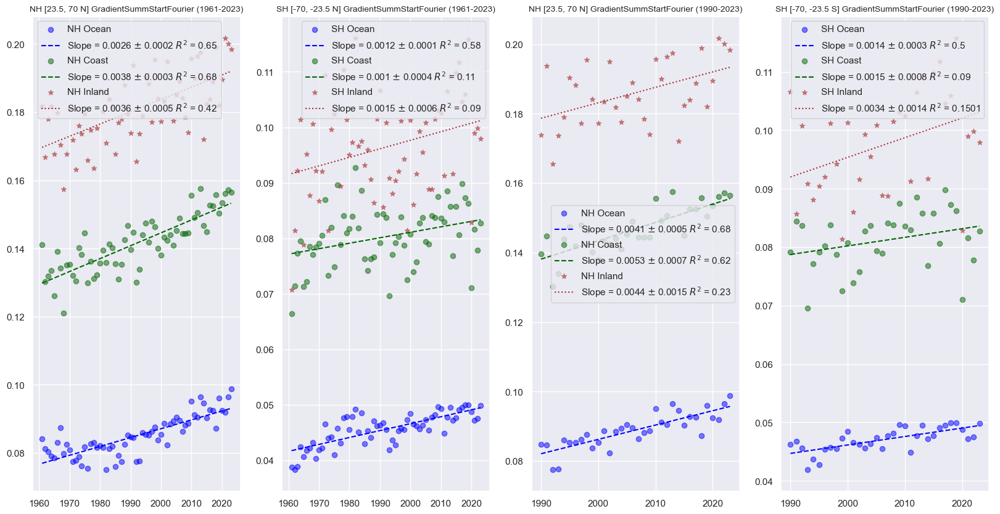

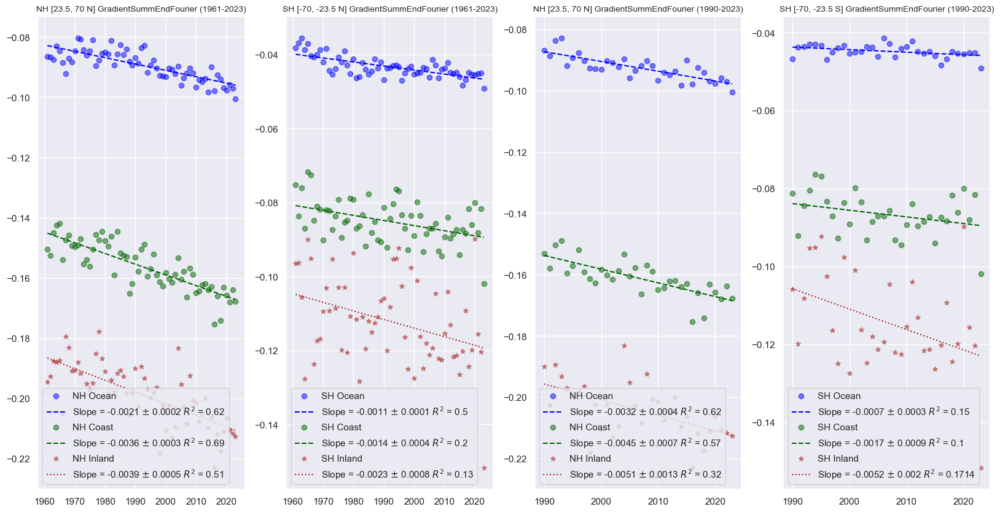

CPU times: user 658 ms, sys: 34.9 ms, total: 693 ms
Wall time: 719 ms


In [8]:
%%time

# takes 30 sec



# loop through all plot variables
for i,v in enumerate(plot_vars):

    # create blank fig
    fig = plt.figure(figsize = (20,10))
    
    # Full Time Period NH
    ax1 = fig.add_subplot(1,4,1)

    # linear fits for slope
    x_land = nh_land_full.time.dt.year.values
    y_land = nh_land_full[v].values
    coefs_land, V = np.polyfit(x_land, y_land, 1, cov=True)
    poly_land = np.poly1d(coefs_land)
    slope_land = np.round(coefs_land[0]*10,4)
    slope_land_sd = np.round(np.sqrt(V[0][0])*10,4)  
    # add in R^2 and RMSE
    ymean = np.mean(y_land)
    ss_total = np.sum((y_land - ymean)**2)
    ss_res = np.sum((y_land - poly_land(x_land))**2)
    #rmse = np.sqrt(ss_res/365.0)
    r_squared_land = np.round(1 - (ss_res / ss_total),2)

    # linear fits for slope
    x_coast = nh_coast_full.time.dt.year.values
    y_coast = nh_coast_full[v].values
    coefs_coast, V = np.polyfit(x_coast, y_coast, 1, cov=True)
    poly_coast = np.poly1d(coefs_coast)
    slope_coast = np.round(coefs_coast[0]*10,4)
    slope_coast_sd = np.round(np.sqrt(V[0][0])*10,4)  
    # add in R^2 and RMSE
    ymean = np.mean(y_coast)
    ss_total = np.sum((y_coast - ymean)**2)
    ss_res = np.sum((y_coast - poly_coast(x_coast))**2)
    #rmse = np.sqrt(ss_res/365.0)
    r_squared_coast = np.round(1 - (ss_res / ss_total),2)

    # linear fits for slope
    x_ocean = nh_ocean_full.time.dt.year.values
    y_ocean = nh_ocean_full[v].values
    coefs_ocean, V = np.polyfit(x_ocean, y_ocean, 1, cov=True)
    poly_ocean = np.poly1d(coefs_ocean)
    slope_ocean = np.round(coefs_ocean[0]*10,4)
    slope_ocean_sd = np.round(np.sqrt(V[0][0])*10,4)  
    # add in R^2 and RMSE
    ymean = np.mean(y_ocean)
    ss_total = np.sum((y_ocean - ymean)**2)
    ss_res = np.sum((y_ocean - poly_ocean(x_ocean))**2)
    #rmse = np.sqrt(ss_res/365.0)
    r_squared_ocean = np.round(1 - (ss_res / ss_total),2)
    
    # plot data
    ax1.scatter(x_ocean, y_ocean, label="NH Ocean", c="blue", alpha=0.5)
    ax1.plot(x_ocean, poly_ocean(x_ocean), linestyle="dashed", color='blue', 
         label="Slope = "+str(slope_ocean)+" $\pm$ "+str(slope_ocean_sd)+" $R^2$ = "+str(r_squared_ocean))
    ax1.scatter(x_coast, y_coast, label="NH Coast", c="darkgreen", alpha=0.5)
    ax1.plot(x_coast, poly_coast(x_coast), linestyle="dashed", color='darkgreen', 
         label="Slope = "+str(slope_coast)+" $\pm$ "+str(slope_coast_sd)+" $R^2$ = "+str(r_squared_coast))
    ax1.scatter(x_land, y_land, label="NH Inland", marker='*', facecolors='brown', edgecolors='brown', alpha=0.5)
    ax1.plot(x_land, poly_land(x_land), linestyle="dotted", color='brown',
         label="Slope = "+str(slope_land)+" $\pm$ "+str(slope_land_sd)+" $R^2$ = "+str(r_squared_land))
    ax1.set_title("NH [23.5, 70 N] " + v + " (1961-2023)", fontsize = 10)
    ax1.legend(loc='best')

    # Full time period SH
    ax2 = fig.add_subplot(1,4,2)

    # linear fits for slope
    x_land = sh_land_full.time.dt.year.values
    y_land = sh_land_full[v].values
    coefs_land, V = np.polyfit(x_land, y_land, 1, cov=True)
    poly_land = np.poly1d(coefs_land)
    slope_land = np.round(coefs_land[0]*10,4)
    slope_land_sd = np.round(np.sqrt(V[0][0])*10,4)  
    # add in R^2 and RMSE
    ymean = np.mean(y_land)
    ss_total = np.sum((y_land - ymean)**2)
    ss_res = np.sum((y_land - poly_land(x_land))**2)
    #rmse = np.sqrt(ss_res/365.0)
    r_squared_land = np.round(1 - (ss_res / ss_total),2)

    # linear fits for slope
    x_coast = sh_coast_full.time.dt.year.values
    y_coast = sh_coast_full[v].values
    coefs_coast, V = np.polyfit(x_coast, y_coast, 1, cov=True)
    poly_coast = np.poly1d(coefs_coast)
    slope_coast = np.round(coefs_coast[0]*10,4)
    slope_coast_sd = np.round(np.sqrt(V[0][0])*10,4)  
    # add in R^2 and RMSE
    ymean = np.mean(y_coast)
    ss_total = np.sum((y_coast - ymean)**2)
    ss_res = np.sum((y_coast - poly_coast(x_coast))**2)
    #rmse = np.sqrt(ss_res/365.0)
    r_squared_coast = np.round(1 - (ss_res / ss_total),2)

    # linear fits for slope
    x_ocean = sh_ocean_full.time.dt.year.values
    y_ocean = sh_ocean_full[v].values
    coefs_ocean, V = np.polyfit(x_ocean, y_ocean, 1, cov=True)
    poly_ocean = np.poly1d(coefs_ocean)
    slope_ocean = np.round(coefs_ocean[0]*10,4)
    slope_ocean_sd = np.round(np.sqrt(V[0][0])*10,4)  
    # add in R^2 and RMSE
    ymean = np.mean(y_ocean)
    ss_total = np.sum((y_ocean - ymean)**2)
    ss_res = np.sum((y_ocean - poly_ocean(x_ocean))**2)
    #rmse = np.sqrt(ss_res/365.0)
    r_squared_ocean = np.round(1 - (ss_res / ss_total),2)
    
    # plot data
    ax2.scatter(x_ocean, y_ocean, label="SH Ocean", c="blue", alpha=0.5)
    ax2.plot(x_ocean, poly_ocean(x_ocean), linestyle="dashed", color='blue', 
         label="Slope = "+str(slope_ocean)+" $\pm$ "+str(slope_ocean_sd)+" $R^2$ = "+str(r_squared_ocean))
    ax2.scatter(x_coast, y_coast, label="SH Coast", c="darkgreen", alpha=0.5)
    ax2.plot(x_coast, poly_coast(x_coast), linestyle="dashed", color='darkgreen', 
         label="Slope = "+str(slope_coast)+" $\pm$ "+str(slope_coast_sd)+" $R^2$ = "+str(r_squared_coast))
    ax2.scatter(x_land, y_land, label="SH Inland", marker='*', facecolors='brown', edgecolors='brown', alpha=0.5)
    ax2.plot(x_land, poly_land(x_land), linestyle="dotted", color='brown',
         label="Slope = "+str(slope_land)+" $\pm$ "+str(slope_land_sd)+" $R^2$ = "+str(r_squared_land))
    ax2.set_title("SH [-70, -23.5 N] " + v + " (1961-2023)", fontsize = 10)
    ax2.legend(loc='best')
    

    # Analysis time period NH
    ax3 = fig.add_subplot(1,4,3)

    # linear fits for slope
    x_land = nh_land_an.time.dt.year.values
    y_land = nh_land_an[v].values
    coefs_land, V = np.polyfit(x_land, y_land, 1, cov=True)
    poly_land = np.poly1d(coefs_land)
    slope_land = np.round(coefs_land[0]*10,4)
    slope_land_sd = np.round(np.sqrt(V[0][0])*10,4)  
    # add in R^2 and RMSE
    ymean = np.mean(y_land)
    ss_total = np.sum((y_land - ymean)**2)
    ss_res = np.sum((y_land - poly_land(x_land))**2)
    #rmse = np.sqrt(ss_res/365.0)
    r_squared_land = np.round(1 - (ss_res / ss_total),2)

    # linear fits for slope
    x_coast = nh_coast_an.time.dt.year.values
    y_coast = nh_coast_an[v].values
    coefs_coast, V = np.polyfit(x_coast, y_coast, 1, cov=True)
    poly_coast = np.poly1d(coefs_coast)
    slope_coast = np.round(coefs_coast[0]*10,4)
    slope_coast_sd = np.round(np.sqrt(V[0][0])*10,4)  
    # add in R^2 and RMSE
    ymean = np.mean(y_coast)
    ss_total = np.sum((y_coast - ymean)**2)
    ss_res = np.sum((y_coast - poly_coast(x_coast))**2)
    #rmse = np.sqrt(ss_res/365.0)
    r_squared_coast = np.round(1 - (ss_res / ss_total),2)

    # linear fits for slope
    x_ocean = nh_ocean_an.time.dt.year.values
    y_ocean = nh_ocean_an[v].values
    coefs_ocean, V = np.polyfit(x_ocean, y_ocean, 1, cov=True)
    poly_ocean = np.poly1d(coefs_ocean)
    slope_ocean = np.round(coefs_ocean[0]*10,4)
    slope_ocean_sd = np.round(np.sqrt(V[0][0])*10,4)  
    # add in R^2 and RMSE
    ymean = np.mean(y_ocean)
    ss_total = np.sum((y_ocean - ymean)**2)
    ss_res = np.sum((y_ocean - poly_ocean(x_ocean))**2)
    #rmse = np.sqrt(ss_res/365.0)
    r_squared_ocean = np.round(1 - (ss_res / ss_total),2)
    
    # plot data
    ax3.scatter(x_ocean, y_ocean, label="NH Ocean", c="blue", alpha=0.5)
    ax3.plot(x_ocean, poly_ocean(x_ocean), linestyle="dashed", color='blue', 
         label="Slope = "+str(slope_ocean)+" $\pm$ "+str(slope_ocean_sd)+" $R^2$ = "+str(r_squared_ocean))
    ax3.scatter(x_coast, y_coast, label="NH Coast", c="darkgreen", alpha=0.5)
    ax3.plot(x_coast, poly_coast(x_coast), linestyle="dashed", color='darkgreen', 
         label="Slope = "+str(slope_coast)+" $\pm$ "+str(slope_coast_sd)+" $R^2$ = "+str(r_squared_coast))
    ax3.scatter(x_land, y_land, label="NH Inland", marker='*', facecolors='brown', edgecolors='brown', alpha=0.5)
    ax3.plot(x_land, poly_land(x_land), linestyle="dotted", color='brown',
         label="Slope = "+str(slope_land)+" $\pm$ "+str(slope_land_sd)+" $R^2$ = "+str(r_squared_land))
    ax3.set_title("NH [23.5, 70 N] " + v + " (1990-2023)", fontsize = 10)
    ax3.legend(loc='best')


    # Analysis time period SH
    ax4 = fig.add_subplot(1,4,4)

    # linear fits for slope
    x_land = sh_land_an.time.dt.year.values
    y_land = sh_land_an[v].values
    coefs_land, V = np.polyfit(x_land, y_land, 1, cov=True)
    poly_land = np.poly1d(coefs_land)
    slope_land = np.round(coefs_land[0]*10,4)
    slope_land_sd = np.round(np.sqrt(V[0][0])*10,4)  
    # add in R^2 and RMSE
    ymean = np.mean(y_land)
    ss_total = np.sum((y_land - ymean)**2)
    ss_res = np.sum((y_land - poly_land(x_land))**2)
    #rmse = np.sqrt(ss_res/365.0)
    r_squared_land = np.round(1 - (ss_res / ss_total),4)

    # linear fits for slope
    x_coast = sh_coast_an.time.dt.year.values
    y_coast = sh_coast_an[v].values
    coefs_coast, V = np.polyfit(x_coast, y_coast, 1, cov=True)
    poly_coast = np.poly1d(coefs_coast)
    slope_coast = np.round(coefs_coast[0]*10,4)
    slope_coast_sd = np.round(np.sqrt(V[0][0])*10,4)  
    # add in R^2 and RMSE
    ymean = np.mean(y_coast)
    ss_total = np.sum((y_coast - ymean)**2)
    ss_res = np.sum((y_coast - poly_coast(x_coast))**2)
    #rmse = np.sqrt(ss_res/365.0)
    r_squared_coast = np.round(1 - (ss_res / ss_total),2)

    # linear fits for slope
    x_ocean = sh_ocean_an.time.dt.year.values
    y_ocean = sh_ocean_an[v].values
    coefs_ocean, V = np.polyfit(x_ocean, y_ocean, 1, cov=True)
    poly_ocean = np.poly1d(coefs_ocean)
    slope_ocean = np.round(coefs_ocean[0]*10,4)
    slope_ocean_sd = np.round(np.sqrt(V[0][0])*10,4)  
    # add in R^2 and RMSE
    ymean = np.mean(y_ocean)
    ss_total = np.sum((y_ocean - ymean)**2)
    ss_res = np.sum((y_ocean - poly_ocean(x_ocean))**2)
    #rmse = np.sqrt(ss_res/365.0)
    r_squared_ocean = np.round(1 - (ss_res / ss_total),2)
    
    # plot data
    ax4.scatter(x_ocean, y_ocean, label="SH Ocean", c="blue", alpha=0.5)
    ax4.plot(x_ocean, poly_ocean(x_ocean), linestyle="dashed", color='blue', 
         label="Slope = "+str(slope_ocean)+" $\pm$ "+str(slope_ocean_sd)+" $R^2$ = "+str(r_squared_ocean))
    ax4.scatter(x_coast, y_coast, label="SH Coast", c="darkgreen", alpha=0.5)
    ax4.plot(x_coast, poly_coast(x_coast), linestyle="dashed", color='darkgreen', 
         label="Slope = "+str(slope_coast)+" $\pm$ "+str(slope_coast_sd)+" $R^2$ = "+str(r_squared_coast))
    ax4.scatter(x_land, y_land, label="SH Inland", marker='*', facecolors='brown', edgecolors='brown', alpha=0.5)
    ax4.plot(x_land, poly_land(x_land), linestyle="dotted", color='brown',
         label="Slope = "+str(slope_land)+" $\pm$ "+str(slope_land_sd)+" $R^2$ = "+str(r_squared_land))
    ax4.set_title("SH [-70, -23.5 S] " + v + " (1990-2023)", fontsize = 10)
    ax4.legend(loc='best')


#plt.tight_layout()
plt.show()


#plt.tight_layout()
plt.show()

## Zonal means of start and end gradient trends: analysis period 1990-2023. Is it getting steeper at the higher latitudes, faster?

In [104]:
# read in the trends
input_path_end = '../../../Data/ERA5-global/Analysis/New-Fourier/Gradients/1990-2023_EndGradTrends.nc'
ds_trend_end = xr.open_dataset(input_path_end)

input_path_start = '../../../Data/ERA5-global/Analysis/New-Fourier/Gradients/1990-2023_StartGradTrends.nc'
ds_trend_start = xr.open_dataset(input_path_start)

ds_trend_start

<xarray.Dataset> Size: 25MB
Dimensions:       (lat: 721, lon: 1440)
Coordinates:
  * lat           (lat) float64 6kB -90.0 -89.75 -89.5 ... 89.5 89.75 90.0
  * lon           (lon) float64 12kB -180.0 -179.8 -179.5 ... 179.2 179.5 179.8
Data variables:
    StartMKSlope  (lat, lon) float64 8MB ...
    StartMKH      (lat, lon) float64 8MB ...
    StartMKP      (lat, lon) float64 8MB ...

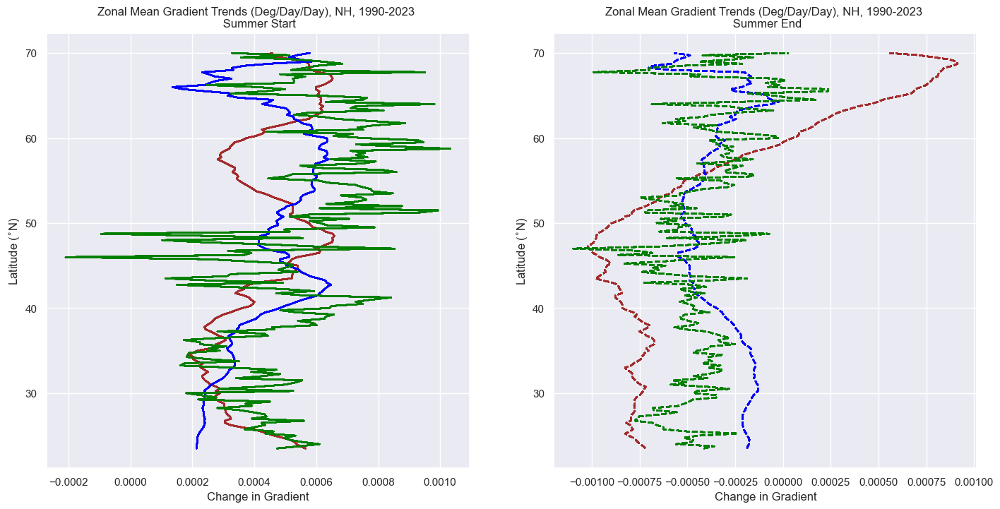

In [112]:
# make the plot - use coastal and lsm flags from ds_full since we don't have those on the gradient trends
fig = plt.figure(figsize=(17,8))
zonal_mean_land_start = ds_trend_start.StartMKSlope.where((ds_full.lsm > 0.5) & (ds_full.Coastal == False)).mean(dim=['lon'])
zonal_mean_ocean_start = ds_trend_start.StartMKSlope.where((ds_full.lsm <= 0.5) & (ds_full.Coastal == False)).mean(dim=['lon'])
zonal_mean_coast_start = ds_trend_start.StartMKSlope.where((ds_full.Coastal == True)).mean(dim=['lon'])
zonal_mean_land_end = ds_trend_end.EndMKSlope.where((ds_full.lsm > 0.5) & (ds_full.Coastal == False)).mean(dim=['lon'])
zonal_mean_ocean_end = ds_trend_end.EndMKSlope.where((ds_full.lsm <= 0.5) & (ds_full.Coastal == False)).mean(dim=['lon'])
zonal_mean_coast_end = ds_trend_end.EndMKSlope.where((ds_full.Coastal == True)).mean(dim=['lon'])

# get NH and SH midlatitudes separately
zonal_mean_land_start_nh = zonal_mean_land_start.where((ds_full.lat >= nh_min) & (ds_full.lat <= nh_max))
zonal_mean_ocean_start_nh = zonal_mean_ocean_start.where((ds_full.lat >= nh_min) & (ds_full.lat <= nh_max))
zonal_mean_coast_start_nh = zonal_mean_coast_start.where((ds_full.lat >= nh_min) & (ds_full.lat <= nh_max))
zonal_mean_land_start_sh = zonal_mean_land_start.where((ds_full.lat >= sh_max) & (ds_full.lat <= sh_min))
zonal_mean_ocean_start_sh = zonal_mean_ocean_start.where((ds_full.lat >= sh_max) & (ds_full.lat <= sh_min))
zonal_mean_coast_start_sh = zonal_mean_coast_start.where((ds_full.lat >= sh_max) & (ds_full.lat <= sh_min))

zonal_mean_land_end_nh = zonal_mean_land_end.where((ds_full.lat >= nh_min) & (ds_full.lat <= nh_max))
zonal_mean_ocean_end_nh = zonal_mean_ocean_end.where((ds_full.lat >= nh_min) & (ds_full.lat <= nh_max))
zonal_mean_coast_end_nh = zonal_mean_coast_end.where((ds_full.lat >= nh_min) & (ds_full.lat <= nh_max))
zonal_mean_land_end_sh = zonal_mean_land_end.where((ds_full.lat >= sh_max) & (ds_full.lat <= sh_min))
zonal_mean_ocean_end_sh = zonal_mean_ocean_end.where((ds_full.lat >= sh_max) & (ds_full.lat <= sh_min))
zonal_mean_coast_end_sh = zonal_mean_coast_end.where((ds_full.lat >= sh_max) & (ds_full.lat <= sh_min))


ax1 = fig.add_subplot(1,2,1)
latitude = zonal_mean_land_start_nh.lat
ax1.plot(zonal_mean_land_start_nh, latitude, c='brown', label='Start Grad Slope: Land')
ax1.plot(zonal_mean_ocean_start_nh, latitude, c='blue', label='Start Grad Slope: Ocean')
ax1.plot(zonal_mean_coast_start_nh, latitude, c='green', label='Start Grad Slope: Coast')
ax1.set_xlabel("Change in Gradient")
ax1.set_ylabel("Latitude ($^{\circ}$N)")
ax1.set_title('Zonal Mean Gradient Trends (Deg/Day/Day), NH, 1990-2023 \n Summer Start')

ax2 = fig.add_subplot(1,2,2)
latitude = zonal_mean_land_end_nh.lat
ax2.plot(zonal_mean_land_end_nh, latitude, c='brown', linestyle='dashed', label='End Grad Slope: Land')
ax2.plot(zonal_mean_ocean_end_nh, latitude, c='blue', linestyle='dashed', label='End Grad Slope: Ocean')
ax2.plot(zonal_mean_coast_end_nh, latitude, c='green', linestyle='dashed', label='End Grad Slope: Coast')
ax2.set_xlabel("Change in Gradient")
ax2.set_ylabel("Latitude ($^{\circ}$N)")
ax2.set_title('Zonal Mean Gradient Trends (Deg/Day/Day), NH, 1990-2023 \n Summer End')
#plt.legend()

plt.show()

# ********** Rachel suggests

# ***** Check GradStart + GradEnd to check how symmetric the shape is. Do it as midlat mean values for NH and SH

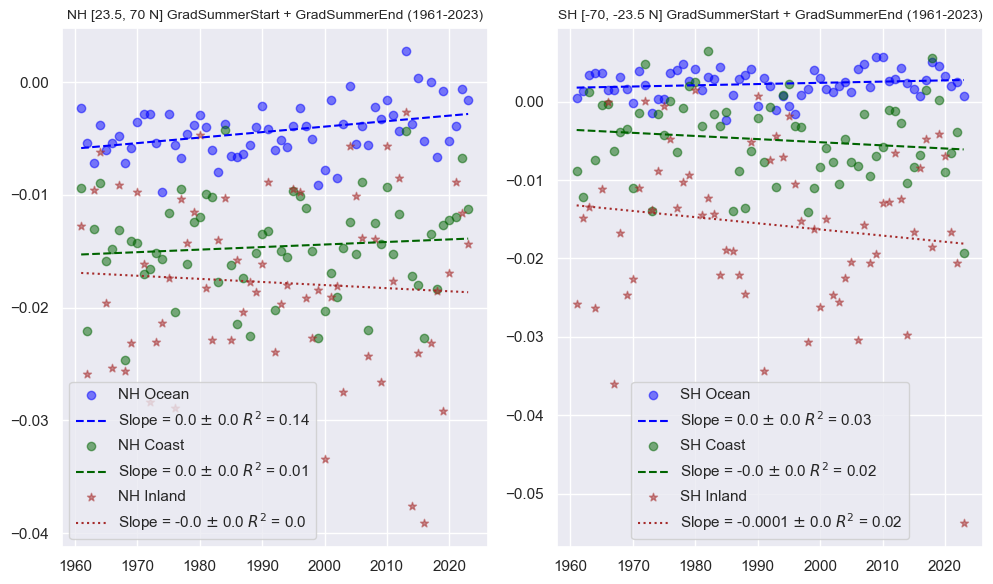

CPU times: user 243 ms, sys: 14.3 ms, total: 257 ms
Wall time: 257 ms


In [16]:
%%time

# takes 30 sec





# create blank fig
fig = plt.figure(figsize = (20,6))

# Full Time Period NH
ax1 = fig.add_subplot(1,4,1)

# linear fits for slope
x_land = nh_land_full.time.dt.year.values
y_land = (nh_land_full.GradientSummStartFourier + nh_land_full.GradientSummEndFourier).values
coefs_land, V = np.polyfit(x_land, y_land, 1, cov=True)
poly_land = np.poly1d(coefs_land)
slope_land = np.round(coefs_land[0],4)
slope_land_sd = np.round(np.sqrt(V[0][0]),2)  
# add in R^2 and RMSE
ymean = np.mean(y_land)
ss_total = np.sum((y_land - ymean)**2)
ss_res = np.sum((y_land - poly_land(x_land))**2)
#rmse = np.sqrt(ss_res/365.0)
r_squared_land = np.round(1 - (ss_res / ss_total),2)

# linear fits for slope
x_coast = nh_coast_full.time.dt.year.values
y_coast = (nh_coast_full.GradientSummStartFourier + nh_coast_full.GradientSummEndFourier).values
coefs_coast, V = np.polyfit(x_coast, y_coast, 1, cov=True)
poly_coast = np.poly1d(coefs_coast)
slope_coast = np.round(coefs_coast[0],4)
slope_coast_sd = np.round(np.sqrt(V[0][0]),2)  
# add in R^2 and RMSE
ymean = np.mean(y_coast)
ss_total = np.sum((y_coast - ymean)**2)
ss_res = np.sum((y_coast - poly_coast(x_coast))**2)
#rmse = np.sqrt(ss_res/365.0)
r_squared_coast = np.round(1 - (ss_res / ss_total),2)

# linear fits for slope
x_ocean = nh_ocean_full.time.dt.year.values
y_ocean = (nh_ocean_full.GradientSummStartFourier + nh_ocean_full.GradientSummEndFourier).values
coefs_ocean, V = np.polyfit(x_ocean, y_ocean, 1, cov=True)
poly_ocean = np.poly1d(coefs_ocean)
slope_ocean = np.round(coefs_ocean[0],4)
slope_ocean_sd = np.round(np.sqrt(V[0][0]),2)  
# add in R^2 and RMSE
ymean = np.mean(y_ocean)
ss_total = np.sum((y_ocean - ymean)**2)
ss_res = np.sum((y_ocean - poly_ocean(x_ocean))**2)
#rmse = np.sqrt(ss_res/365.0)
r_squared_ocean = np.round(1 - (ss_res / ss_total),2)

# plot data
ax1.scatter(x_ocean, y_ocean, label="NH Ocean", c="blue", alpha=0.5)
ax1.plot(x_ocean, poly_ocean(x_ocean), linestyle="dashed", color='blue', 
     label="Slope = "+str(slope_ocean)+" $\pm$ "+str(slope_ocean_sd)+" $R^2$ = "+str(r_squared_ocean))
ax1.scatter(x_coast, y_coast, label="NH Coast", c="darkgreen", alpha=0.5)
ax1.plot(x_coast, poly_coast(x_coast), linestyle="dashed", color='darkgreen', 
     label="Slope = "+str(slope_coast)+" $\pm$ "+str(slope_coast_sd)+" $R^2$ = "+str(r_squared_coast))
ax1.scatter(x_land, y_land, label="NH Inland", marker='*', facecolors='brown', edgecolors='brown', alpha=0.5)
ax1.plot(x_land, poly_land(x_land), linestyle="dotted", color='brown',
     label="Slope = "+str(slope_land)+" $\pm$ "+str(slope_land_sd)+" $R^2$ = "+str(r_squared_land))
ax1.set_title("NH [23.5, 70 N] " + "GradSummerStart + GradSummerEnd" + " (1961-2023)", fontsize = 10)
ax1.legend(loc='best')

# Full time period SH
ax2 = fig.add_subplot(1,4,2)

# linear fits for slope
x_land = sh_land_full.time.dt.year.values
y_land = (sh_land_full.GradientSummStartFourier+sh_land_full.GradientSummEndFourier).values
coefs_land, V = np.polyfit(x_land, y_land, 1, cov=True)
poly_land = np.poly1d(coefs_land)
slope_land = np.round(coefs_land[0],4)
slope_land_sd = np.round(np.sqrt(V[0][0]),2)  
# add in R^2 and RMSE
ymean = np.mean(y_land)
ss_total = np.sum((y_land - ymean)**2)
ss_res = np.sum((y_land - poly_land(x_land))**2)
#rmse = np.sqrt(ss_res/365.0)
r_squared_land = np.round(1 - (ss_res / ss_total),2)

# linear fits for slope
x_coast = sh_coast_full.time.dt.year.values
y_coast = (sh_coast_full.GradientSummStartFourier+sh_coast_full.GradientSummEndFourier).values
coefs_coast, V = np.polyfit(x_coast, y_coast, 1, cov=True)
poly_coast = np.poly1d(coefs_coast)
slope_coast = np.round(coefs_coast[0],4)
slope_coast_sd = np.round(np.sqrt(V[0][0]),2)  
# add in R^2 and RMSE
ymean = np.mean(y_coast)
ss_total = np.sum((y_coast - ymean)**2)
ss_res = np.sum((y_coast - poly_coast(x_coast))**2)
#rmse = np.sqrt(ss_res/365.0)
r_squared_coast = np.round(1 - (ss_res / ss_total),2)

# linear fits for slope
x_ocean = sh_ocean_full.time.dt.year.values
y_ocean = (sh_ocean_full.GradientSummStartFourier+sh_ocean_full.GradientSummEndFourier).values
coefs_ocean, V = np.polyfit(x_ocean, y_ocean, 1, cov=True)
poly_ocean = np.poly1d(coefs_ocean)
slope_ocean = np.round(coefs_ocean[0],4)
slope_ocean_sd = np.round(np.sqrt(V[0][0]),2)  
# add in R^2 and RMSE
ymean = np.mean(y_ocean)
ss_total = np.sum((y_ocean - ymean)**2)
ss_res = np.sum((y_ocean - poly_ocean(x_ocean))**2)
#rmse = np.sqrt(ss_res/365.0)
r_squared_ocean = np.round(1 - (ss_res / ss_total),2)

# plot data
ax2.scatter(x_ocean, y_ocean, label="SH Ocean", c="blue", alpha=0.5)
ax2.plot(x_ocean, poly_ocean(x_ocean), linestyle="dashed", color='blue', 
     label="Slope = "+str(slope_ocean)+" $\pm$ "+str(slope_ocean_sd)+" $R^2$ = "+str(r_squared_ocean))
ax2.scatter(x_coast, y_coast, label="SH Coast", c="darkgreen", alpha=0.5)
ax2.plot(x_coast, poly_coast(x_coast), linestyle="dashed", color='darkgreen', 
     label="Slope = "+str(slope_coast)+" $\pm$ "+str(slope_coast_sd)+" $R^2$ = "+str(r_squared_coast))
ax2.scatter(x_land, y_land, label="SH Inland", marker='*', facecolors='brown', edgecolors='brown', alpha=0.5)
ax2.plot(x_land, poly_land(x_land), linestyle="dotted", color='brown',
     label="Slope = "+str(slope_land)+" $\pm$ "+str(slope_land_sd)+" $R^2$ = "+str(r_squared_land))
ax2.set_title("SH [-70, -23.5 N] " + "GradSummerStart + GradSummerEnd" + " (1961-2023)", fontsize = 10)
ax2.legend(loc='best')


# # Analysis time period NH
# ax3 = fig.add_subplot(1,4,3)

# # linear fits for slope
# x_land = nh_land_an.time.dt.year.values
# y_land = nh_land_an[v].values
# coefs_land, V = np.polyfit(x_land, y_land, 1, cov=True)
# poly_land = np.poly1d(coefs_land)
# slope_land = np.round(coefs_land[0],4)
# slope_land_sd = np.round(np.sqrt(V[0][0]),2)  
# # add in R^2 and RMSE
# ymean = np.mean(y_land)
# ss_total = np.sum((y_land - ymean)**2)
# ss_res = np.sum((y_land - poly_land(x_land))**2)
# #rmse = np.sqrt(ss_res/365.0)
# r_squared_land = np.round(1 - (ss_res / ss_total),2)

# # linear fits for slope
# x_coast = nh_coast_an.time.dt.year.values
# y_coast = nh_coast_an[v].values
# coefs_coast, V = np.polyfit(x_coast, y_coast, 1, cov=True)
# poly_coast = np.poly1d(coefs_coast)
# slope_coast = np.round(coefs_coast[0],4)
# slope_coast_sd = np.round(np.sqrt(V[0][0]),2)  
# # add in R^2 and RMSE
# ymean = np.mean(y_coast)
# ss_total = np.sum((y_coast - ymean)**2)
# ss_res = np.sum((y_coast - poly_coast(x_coast))**2)
# #rmse = np.sqrt(ss_res/365.0)
# r_squared_coast = np.round(1 - (ss_res / ss_total),2)

# # linear fits for slope
# x_ocean = nh_ocean_an.time.dt.year.values
# y_ocean = nh_ocean_an[v].values
# coefs_ocean, V = np.polyfit(x_ocean, y_ocean, 1, cov=True)
# poly_ocean = np.poly1d(coefs_ocean)
# slope_ocean = np.round(coefs_ocean[0],4)
# slope_ocean_sd = np.round(np.sqrt(V[0][0]),2)  
# # add in R^2 and RMSE
# ymean = np.mean(y_ocean)
# ss_total = np.sum((y_ocean - ymean)**2)
# ss_res = np.sum((y_ocean - poly_ocean(x_ocean))**2)
# #rmse = np.sqrt(ss_res/365.0)
# r_squared_ocean = np.round(1 - (ss_res / ss_total),2)

# # plot data
# ax3.scatter(x_ocean, y_ocean, label="NH Ocean", c="blue", alpha=0.5)
# ax3.plot(x_ocean, poly_ocean(x_ocean), linestyle="dashed", color='blue', 
#      label="Slope = "+str(slope_ocean)+" $\pm$ "+str(slope_ocean_sd)+" $R^2$ = "+str(r_squared_ocean))
# ax3.scatter(x_coast, y_coast, label="NH Coast", c="darkgreen", alpha=0.5)
# ax3.plot(x_coast, poly_coast(x_coast), linestyle="dashed", color='darkgreen', 
#      label="Slope = "+str(slope_coast)+" $\pm$ "+str(slope_coast_sd)+" $R^2$ = "+str(r_squared_coast))
# ax3.scatter(x_land, y_land, label="NH Inland", marker='*', facecolors='brown', edgecolors='brown', alpha=0.5)
# ax3.plot(x_land, poly_land(x_land), linestyle="dotted", color='brown',
#      label="Slope = "+str(slope_land)+" $\pm$ "+str(slope_land_sd)+" $R^2$ = "+str(r_squared_land))
# ax3.set_title("NH [23.5, 70 N] " + v + " (1990-2023)", fontsize = 10)
# ax3.legend(loc='best')


# # Analysis time period SH
# ax4 = fig.add_subplot(1,4,4)

# # linear fits for slope
# x_land = sh_land_an.time.dt.year.values
# y_land = sh_land_an[v].values
# coefs_land, V = np.polyfit(x_land, y_land, 1, cov=True)
# poly_land = np.poly1d(coefs_land)
# slope_land = np.round(coefs_land[0],4)
# slope_land_sd = np.round(np.sqrt(V[0][0]),2)  
# # add in R^2 and RMSE
# ymean = np.mean(y_land)
# ss_total = np.sum((y_land - ymean)**2)
# ss_res = np.sum((y_land - poly_land(x_land))**2)
# #rmse = np.sqrt(ss_res/365.0)
# r_squared_land = np.round(1 - (ss_res / ss_total),2)

# # linear fits for slope
# x_coast = sh_coast_an.time.dt.year.values
# y_coast = sh_coast_an[v].values
# coefs_coast, V = np.polyfit(x_coast, y_coast, 1, cov=True)
# poly_coast = np.poly1d(coefs_coast)
# slope_coast = np.round(coefs_coast[0],4)
# slope_coast_sd = np.round(np.sqrt(V[0][0]),2)  
# # add in R^2 and RMSE
# ymean = np.mean(y_coast)
# ss_total = np.sum((y_coast - ymean)**2)
# ss_res = np.sum((y_coast - poly_coast(x_coast))**2)
# #rmse = np.sqrt(ss_res/365.0)
# r_squared_coast = np.round(1 - (ss_res / ss_total),2)

# # linear fits for slope
# x_ocean = sh_ocean_an.time.dt.year.values
# y_ocean = sh_ocean_an[v].values
# coefs_ocean, V = np.polyfit(x_ocean, y_ocean, 1, cov=True)
# poly_ocean = np.poly1d(coefs_ocean)
# slope_ocean = np.round(coefs_ocean[0],4)
# slope_ocean_sd = np.round(np.sqrt(V[0][0]),2)  
# # add in R^2 and RMSE
# ymean = np.mean(y_ocean)
# ss_total = np.sum((y_ocean - ymean)**2)
# ss_res = np.sum((y_ocean - poly_ocean(x_ocean))**2)
# #rmse = np.sqrt(ss_res/365.0)
# r_squared_ocean = np.round(1 - (ss_res / ss_total),2)

# # plot data
# ax4.scatter(x_ocean, y_ocean, label="SH Ocean", c="blue", alpha=0.5)
# ax4.plot(x_ocean, poly_ocean(x_ocean), linestyle="dashed", color='blue', 
#      label="Slope = "+str(slope_ocean)+" $\pm$ "+str(slope_ocean_sd)+" $R^2$ = "+str(r_squared_ocean))
# ax4.scatter(x_coast, y_coast, label="SH Coast", c="darkgreen", alpha=0.5)
# ax4.plot(x_coast, poly_coast(x_coast), linestyle="dashed", color='darkgreen', 
#      label="Slope = "+str(slope_coast)+" $\pm$ "+str(slope_coast_sd)+" $R^2$ = "+str(r_squared_coast))
# ax4.scatter(x_land, y_land, label="SH Inland", marker='*', facecolors='brown', edgecolors='brown', alpha=0.5)
# ax4.plot(x_land, poly_land(x_land), linestyle="dotted", color='brown',
#      label="Slope = "+str(slope_land)+" $\pm$ "+str(slope_land_sd)+" $R^2$ = "+str(r_squared_land))
# ax4.set_title("SH [-70, -23.5 S] " + v + " (1990-2023)", fontsize = 10)
# ax4.legend(loc='best')


plt.tight_layout()
plt.show()



## Conclusion? Looks like decent symmetry in the slope of the start and the end with Ocean being the most symmetric, coast a bit steeper for summer end, and inland areas even more steep for summer end

## Rachel would like to see a map of the summ avg'd over time as a map

In [7]:
%%time

# takes 36 sec

# latitude & longitude ranges for NH and SH midlatitudes so they will be easy to adjust
nh_min = 23.5
nh_max = 70
sh_min = -23.5
sh_max = -70

# filter to midlatitudes and get temporal averages, then sum the gradients

sum_avg = ds_full.where(((ds_full.lat >= nh_min) & (ds_full.lat <= nh_max)) | ((ds_full.lat >= sh_max) & (ds_full.lat <= sh_min))).mean(dim=['time'])



CPU times: user 975 ms, sys: 1.18 s, total: 2.15 s
Wall time: 2.2 s


In [8]:
sum_avg['SumOfGradients'] = sum_avg.GradientSummStartFourier + sum_avg.GradientSummEndFourier
sum_avg

<xarray.Dataset> Size: 58MB
Dimensions:                   (lat: 721, lon: 1440)
Coordinates:
  * lat                       (lat) float64 6kB -90.0 -89.75 ... 89.75 90.0
  * lon                       (lon) float64 12kB -180.0 -179.8 ... 179.5 179.8
Data variables:
    SummerStart               (lat, lon) float64 8MB nan nan nan ... nan nan nan
    SummerEnd                 (lat, lon) float64 8MB nan nan nan ... nan nan nan
    GradientSummStartFourier  (lat, lon) float64 8MB nan nan nan ... nan nan nan
    GradientSummEndFourier    (lat, lon) float64 8MB nan nan nan ... nan nan nan
    lsm                       (lat, lon) float64 8MB nan nan nan ... nan nan nan
    Coastal                   (lat, lon) float64 8MB nan nan nan ... nan nan nan
    SumOfGradients            (lat, lon) float64 8MB nan nan nan ... nan nan nan

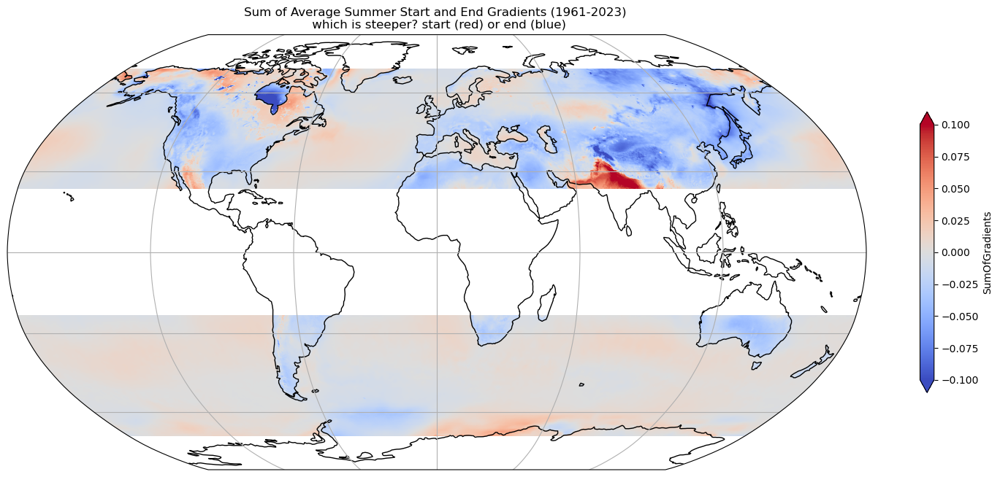

In [12]:
# Global summer start trend
fig = plt.figure(figsize=(15,8))

# assign axis and def projection to use
ax = plt.axes(projection=ccrs.Robinson(central_longitude=0))

# add coastlines and grid
ax.coastlines()
ax.gridlines()

sum_avg.SumOfGradients.plot(
    ax=ax,
    transform=ccrs.PlateCarree(), # assign map projection
    vmin=-0.1,
    vmax=0.1, 
    cmap="coolwarm",#"YlOrRd"#cmap="coolwarm"
    cbar_kwargs={'shrink': 0.5}
)


plt.title("Sum of Average Summer Start and End Gradients (1961-2023) \n which is steeper? start (red) or end (blue)")#+" using 1961-1990 baseline")
#plt.savefig("./Plots/"+str(input_year)+"_SummerMeanHS_global.png")
plt.tight_layout()
plt.show()

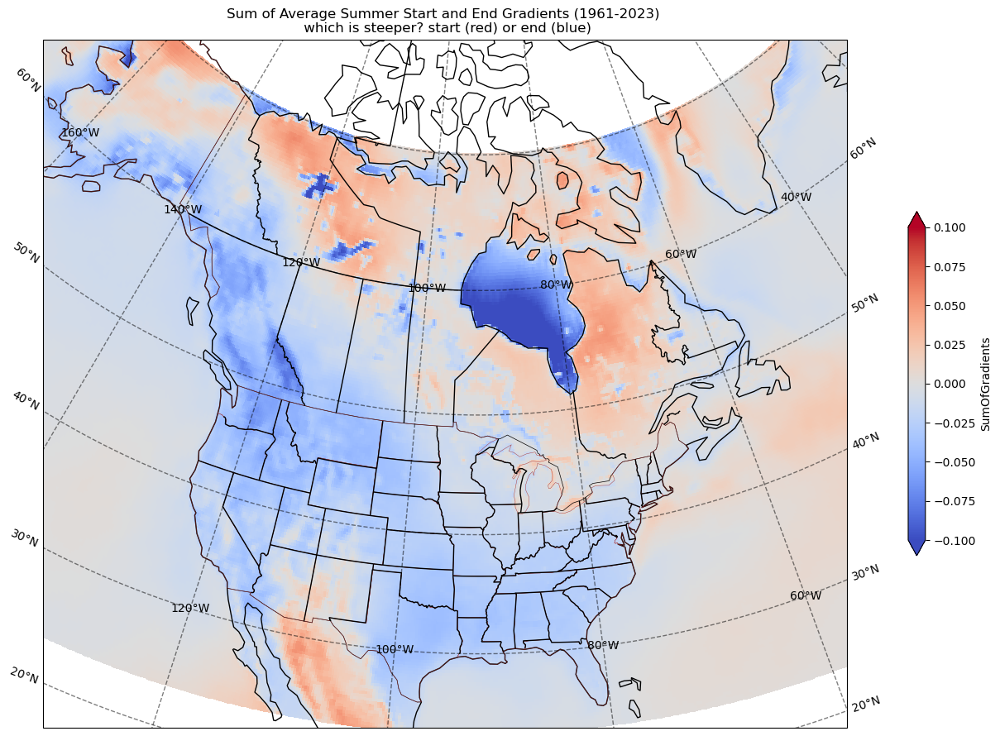

In [14]:

central_longitude = -(91 + 52 / 60)
central_latitude = 40

############
#Global map of summer end
fig = plt.figure(figsize=(15,9))

# assign axis and def projection to use
ax = plt.axes(projection=ccrs.LambertConformal(central_longitude=central_longitude, central_latitude=central_latitude))

# add coastlines and grid
ax.coastlines()
ax.gridlines(draw_labels=True, linewidth=1, color='black', alpha=0.5, linestyle='--')

dataplot = sum_avg.SumOfGradients.plot(
    ax=ax,
    transform=ccrs.PlateCarree(), # assign map projection
    vmin=-0.1,
    vmax=0.1,  
    cmap="coolwarm",
    cbar_kwargs={'shrink': 0.5}
    
)


ax.set_extent((-130, -60, 20, 75))

provinces_50m = cfeature.NaturalEarthFeature('cultural',
                                             'admin_1_states_provinces_lines',
                                             '50m',
                                             facecolor='none')
ax.add_feature(cfeature.BORDERS, linewidth=0.5, edgecolor='black')
ax.add_feature(cfeature.STATES, linewidth=0.3, edgecolor='brown')
ax.add_feature(provinces_50m)
plt.title("Sum of Average Summer Start and End Gradients (1961-2023) \n which is steeper? start (red) or end (blue)")#+" using 1961-1990 baseline")
#plt.savefig("./Plots/"+str(input_year)+"_SummerMeanHS_global.png")
plt.tight_layout()
#plt.savefig("./Plots/"+str(input_year)+"_SummerLength_global.png")
plt.show()

### zonal means for surface types

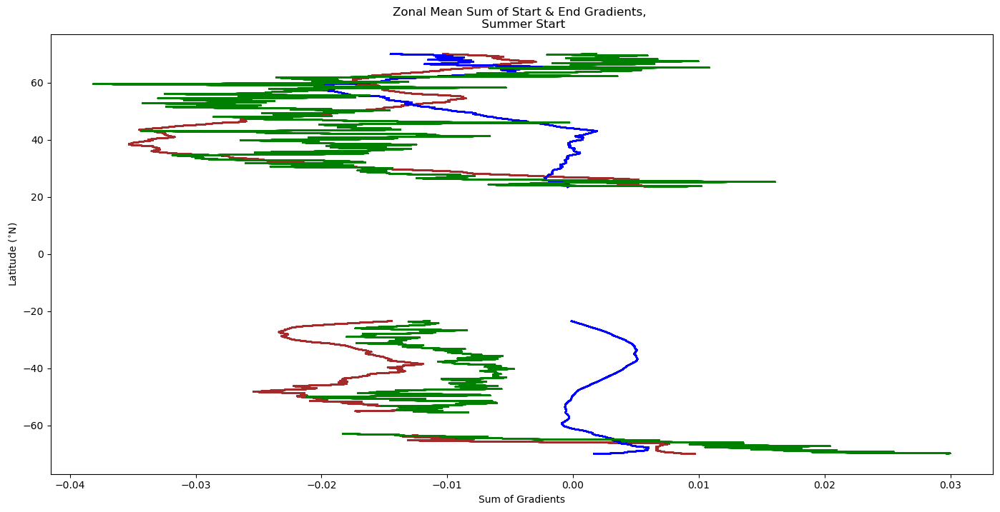

In [15]:
# make the plot - use coastal and lsm flags from ds_full since we don't have those on the gradient trends
fig = plt.figure(figsize=(17,8))
zonal_mean_land_sum = sum_avg.SumOfGradients.where((ds_full.lsm > 0.5) & (ds_full.Coastal == False)).mean(dim=['lon'])
zonal_mean_ocean_sum = sum_avg.SumOfGradients.where((ds_full.lsm <= 0.5) & (ds_full.Coastal == False)).mean(dim=['lon'])
zonal_mean_coast_sum = sum_avg.SumOfGradients.where((ds_full.Coastal == True)).mean(dim=['lon'])


# get NH and SH midlatitudes separately
# zonal_mean_land_start_nh = zonal_mean_land_start.where((ds_full.lat >= nh_min) & (ds_full.lat <= nh_max))
# zonal_mean_ocean_start_nh = zonal_mean_ocean_start.where((ds_full.lat >= nh_min) & (ds_full.lat <= nh_max))
# zonal_mean_coast_start_nh = zonal_mean_coast_start.where((ds_full.lat >= nh_min) & (ds_full.lat <= nh_max))



ax1 = fig.add_subplot(1,1,1)
latitude = zonal_mean_land_sum.lat
ax1.plot(zonal_mean_land_sum, latitude, c='brown', label='Start Grad Slope: Land')
ax1.plot(zonal_mean_ocean_sum, latitude, c='blue', label='Start Grad Slope: Ocean')
ax1.plot(zonal_mean_coast_sum, latitude, c='green', label='Start Grad Slope: Coast')
ax1.set_xlabel("Sum of Gradients")
ax1.set_ylabel("Latitude ($^{\circ}$N)")
ax1.set_title('Zonal Mean Sum of Start & End Gradients, \n Summer Start')


plt.show()